# STEP6. 수익률곡선 다요인 모형 분석

## 분석 질문

산업별 주가는 금리 전반의 수준, 장단기 기울기, 중기 구간의 곡률, 신용위험 중
무엇에 더 민감하게 반응하는가?

- <b>관련 가설</b> — H1(금리충격 원천에 따른 이질성)
- <b>선행 단계</b> — Baseline(STEP4·STEP5)에서 국고채 3년 기준 산업 간 금리베타 차이를 확인했다.

## 입력

| 구분 | 경로 |
|---|---|
| 산업·KOSPI 패널 | `data/processed/industry_rate_panel_daily.csv` |
| 국고채 1·3·5·10년 | `data/raw/rates/treasury_yield_curve_1_3_5_10y.csv` |
| 회사채 AA− 3년 | `data/raw/rates/corporate_bond_aa_minus_3y.csv` |

## 출력

<b>데이터</b>

- `data/processed/industry_rate_panel_extended.csv`

<b>Table</b> — `results/H1_yield_curve/tables/`

| 파일 | 내용 |
|---|---|
| `maturity_beta_comparison.csv` | 3년·10년·장단기차 만기별 금리 베타 비교 |
| `yield_curve_factor_betas.csv` | 산업별 Level·Slope·Curvature 계수(3요인) |
| `ns_vs_butterfly_factor_corr.csv` | NS 요인 vs 나비 스프레드 상관 |
| `curvature_ns_vs_butterfly_by_industry.csv` | 산업별 곡률 NS·나비 비교 |
| `credit_spread_betas.csv` | 신용스프레드 포함 4요인 계수 |
| `factor_correlation_vif.csv` | 요인 상관행렬·VIF |
| `industry_difference_test.csv` | 산업 간 계수 동일성 검정 |
| `exploratory_yield_pca.csv` | 곡선 주성분분석(차원) |
| `exploratory_model_parsimony.csv` | 요인 수별 설명력(조정 R²) |
| `exploratory_joint_ftest.csv` | 3요인 동시검정 |
| `exploratory_two_factor_betas.csv` | Level+Slope 2요인 계수 |
| `exploratory_orthogonalized_betas.csv` | 직교화 요인 계수 |
| `exploratory_hac_sensitivity.csv` | HAC 시차 민감도 |
| `credit_curvature_overlap.csv` | 곡률–신용 공유분 진단 |

<b>Figure</b> — `results/H1_yield_curve/figures/`

| 파일 | 내용 |
|---|---|
| `01_maturity_beta_comparison_heatmap.png` | 만기별 베타 히트맵 |
| `02_yield_curve_factor_beta_heatmap.png` | 산업별 요인 민감도 히트맵 |
| `03_{level,slope,curvature}_coefficient_plot.png` | 요인별 계수 플롯 |
| `04_yield_curve_factor_ci.png` | 4요인 계수 신뢰구간 |
| `ns_vs_butterfly_curvature.png` | NS vs 나비 곡률 산점도 |
| `05_joint_ftest.png` ~ `10_hac_sensitivity.png` | PART D 진단 그림들 |

<b>Summary</b>

- `results/H1_yield_curve/summary.md` — 텍스트 요약
- `results/H1_yield_curve/06_summary_final.html` — 표·그림 포함 공유용 리포트

## 구성

| 파트 | 내용 | 성격 |
|---|---|---|
| PART A | 3년·10년·장단기차 개별 회귀 비교 | 확증 |
| PART B | Nelson–Siegel Level·Slope·Curvature 동시모형 | 확증 |
| PART C | Credit Spread 추가 민감도 점검 | 확증 |
| PART D | 다중공선성 진단과 추가 검정 | <b>사후</b> |

> PART D는 PART A~C 결과를 본 뒤 설계한 사후 분석이다.
> 미리 계획한 검정과 같은 무게를 갖지 않으며, 산출물은 `exploratory_` 접두로 구분한다.

## 전체 수행 흐름

<b>PART A·B — 수익률곡선 요인 (B-1)</b>

1. 라이브러리와 경로 설정
2. 산업 패널 불러오기
3. 국고채 1·3·5·10년 정리
4. 산업 패널과 금리자료 병합
5. 3년·10년·장단기차 개별 회귀
6. 만기별 비교표와 그림
7. Nelson–Siegel 공통 λ 선택
8. 날짜별 Level·Slope·Curvature와 변화량
9. 세 요인 동시모형 추정
10. 계수·SE·t·p·신뢰구간 표
11. 요인 민감도 heatmap과 계수 플롯

<b>PART C — Credit Spread (B-2)</b>

12. Credit Spread 단독모형
13. Credit Spread 포함 확장모형
14. BH 보정과 결과표 저장
15. 요인 상관행렬과 VIF
16. 4요인 계수 신뢰구간 그림
17. 강건성 판정
18. 요약 문서

<b>PART D — 사후 진단</b>

- D-0 주성분분석
- D-1 동시검정
- D-2 2요인 축소
- D-3 직교화
- D-4 산업 간 계수 동일성 검정
- D-5 모형 비교
- D-6 HAC 시차 민감도


## 1단계. 라이브러리와 프로젝트 경로 설정

In [1]:
# --- 저장소 루트 부트스트랩 (모든 노트북 공통, 수정 금지) ---
# 저장소 루트에서 `pip install -e .` 를 한 번 실행했다면 아래 탐색은 건너뛴다.
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():          # VS Code Notebook
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):                        # IPython 커널 시작 폴더 (Jupyter/Lab/Colab)
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())           # 최후 수단

# config.py 와 requirements.txt 를 '둘 다' 가진 폴더만 저장소 루트로 인정한다.
# 마커를 하나만 보면 다른 폴더의 동명 config.py 를 잘못 집을 수 있다.
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
# 이미 sys.path에 있더라도 맨 앞으로 올린다. cwd(예: 바탕화면)가 앞에 있으면
# 같은 이름의 다른 config.py 가 먼저 잡히기 때문이다.
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))

import config

if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(
        f"의도하지 않은 config.py 가 import 되었습니다: {config.__file__}\n"
        f"저장소 루트({_root})에서 `pip install -e .` 를 실행하세요."
    )
# --- 부트스트랩 끝 ---

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from scipy.optimize import minimize_scalar

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# 한글 폰트. 공통 설정은 config.setup_korean_font() 한 곳에서 관리한다
# (config.py 5-c절).
# ---------------------------------------------------------------
config.setup_korean_font()

# ---------------------------------------------------------------
# 경로는 전부 config에서 가져온다.
# 로컬 별칭(PANEL_PATH = ... 같은 재정의)을 만들지 않는다. 별칭을 만들면 셀을
# 순서대로 실행하지 않았을 때 NameError가 나고, config와 값이 어긋날 수 있다.
# ---------------------------------------------------------------
if not config.RAW_YIELD_CURVE_FILE.exists():
    raise FileNotFoundError(
        f"국고채 1·3·5·10년 원본을 찾지 못했습니다: {config.RAW_YIELD_CURVE_FILE}\n"
        "config.describe() 로 탐색 결과를 확인하세요."
    )

if not config.PANEL_PATH.exists():
    raise FileNotFoundError(
        f"산업 패널을 찾지 못했습니다: {config.PANEL_PATH}\n"
        "01_data_preparation → 02_variable_generation 을 먼저 실행하세요."
    )

config.describe()

그래프 폰트: Malgun Gothic
PROJECT_ROOT : FINDSLAB-Research-Intern
DATA_DIR     : data  (exists=True)

[raw 파일]
  [OK     ] RAW_YIELD_FILE: data\raw\rates\treasury_yield_3y_10y.csv
  [OK     ] RAW_YIELD_CURVE_FILE: data\raw\rates\treasury_yield_curve_1_3_5_10y.csv
  [OK     ] RAW_CREDIT_SPREAD_FILE: data\raw\rates\corporate_bond_aa_minus_3y.csv

[가공 데이터]
  [OK     ] PANEL_PATH: data\processed\industry_rate_panel_daily.csv
  [OK     ] EXTENDED_PANEL_PATH: data\processed\industry_rate_panel_extended.csv

[산업 원본 폴더]
  KOSPI 화학     data\raw\industry\chemicals              (5 files)
  KOSPI 건설업    data\raw\industry\construction           (5 files)
  KOSPI 전기전자   data\raw\industry\electronics            (5 files)
  KOSPI 금융업    data\raw\industry\financials             (5 files)
  KOSPI 금속     data\raw\industry\metal                  (5 files)
  KOSPI 의약품    data\raw\industry\pharma                 (5 files)
  KOSPI 운수장비   data\raw\industry\transport_equipment    (5 files)
  KOSPI        data\raw\


## 2단계. 산업 패널데이터 불러오기

### 왜 확인이 필요한가?

이번 분석의 종속변수는 `industry_return`, 시장 통제변수는 `kospi_return`이다.  
또한 기존 만기별 비교를 위해 `d_y3`, `d_y10`, `d_term_spread`가 있는지도 확인한다.

In [2]:
panel = pd.read_csv(config.PANEL_PATH, encoding="utf-8-sig")
panel["date"] = pd.to_datetime(panel["date"], errors="coerce")

required_panel_cols = [
    "date",
    "industry",
    "industry_return",
    "kospi_return",
    "d_y3",
    "d_y10",
    "d_term_spread",
]

missing_cols = [c for c in required_panel_cols if c not in panel.columns]

if missing_cols:
    raise ValueError(
        "산업 패널데이터에 필요한 컬럼이 없습니다: "
        + ", ".join(missing_cols)
    )

panel = panel.sort_values(["date", "industry"]).reset_index(drop=True)

print("패널 크기:", panel.shape)
print("분석 기간:", panel["date"].min(), "~", panel["date"].max())
print("산업 수:", panel["industry"].nunique())
print("산업 목록:", sorted(panel["industry"].dropna().unique()))
display(panel.head())

패널 크기: (17164, 12)
분석 기간: 2016-01-04 00:00:00 ~ 2025-12-30 00:00:00
산업 수: 7
산업 목록: ['건설업', '금융업', '운수장비', '의약품', '전기전자', '철강금속', '화학']


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,term_spread,d_term_spread
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN



## 3단계. 국고채 금리자료 불러오기

### 왜 형태를 바꿔야 하나?

ECOS 원본은 만기가 행에 있고 날짜가 열에 있는 형태다.  
이를 날짜별로 1년·3년·5년·10년 금리가 한 행에 들어가도록 바꿔야 Nelson–Siegel 모형을 적용할 수 있다.

In [3]:
# 국고채 1·3·5·10년 원본을 읽는다. 경로·확장자는 config가 관리한다.
yield_raw = pd.read_csv(config.RAW_YIELD_CURVE_FILE, encoding="utf-8-sig")

print("원본 금리자료:", config.RAW_YIELD_CURVE_FILE.name, yield_raw.shape)
display(yield_raw.iloc[:, :12])

원본 금리자료: treasury_yield_curve_1_3_5_10y.csv (4, 2466)


,통계표,계정항목,단위,변환,2016/01/04,2016/01/05,2016/01/06,2016/01/07,2016/01/08,2016/01/11,2016/01/12,2016/01/13
0,1.3.2.1. 시장금리(일별),국고채(1년),연%,원자료,1.605,1.602,1.601,1.598,1.608,1.590,1.588,1.587
1,1.3.2.1. 시장금리(일별),국고채(3년),연%,원자료,1.634,1.643,1.639,1.639,1.665,1.635,1.638,1.633
2,1.3.2.1. 시장금리(일별),국고채(5년),연%,원자료,1.778,1.792,1.788,1.780,1.813,1.775,1.784,1.780
3,1.3.2.1. 시장금리(일별),국고채(10년),연%,원자료,2.039,2.057,2.035,2.015,2.057,2.025,2.036,2.025


In [4]:
if "계정항목" not in yield_raw.columns:
    raise ValueError("금리자료에서 '계정항목' 컬럼을 찾지 못했습니다.")

maturity_map = {
    "국고채(1년)": "y1",
    "국고채(3년)": "y3_new",
    "국고채(5년)": "y5",
    "국고채(10년)": "y10_new",
}

yield_selected = yield_raw[
    yield_raw["계정항목"].isin(maturity_map.keys())
].copy()

if len(yield_selected) != 4:
    raise ValueError("국고채 1년·3년·5년·10년 행을 모두 찾지 못했습니다.")

yield_selected["maturity_name"] = yield_selected["계정항목"].map(maturity_map)

metadata_cols = [
    col for col in ["통계표", "계정항목", "단위", "변환"]
    if col in yield_selected.columns
]

date_cols = [
    col for col in yield_selected.columns
    if col not in metadata_cols + ["maturity_name"]
]

yield_long = yield_selected.melt(
    id_vars=["maturity_name"],
    value_vars=date_cols,
    var_name="date",
    value_name="yield",
)

yield_long["date"] = pd.to_datetime(yield_long["date"], errors="coerce")
yield_long["yield"] = pd.to_numeric(yield_long["yield"], errors="coerce")

yield_wide = (
    yield_long
    .pivot(index="date", columns="maturity_name", values="yield")
    .reset_index()
    .sort_values("date")
    .dropna()
    .reset_index(drop=True)
)

yield_wide.columns.name = None
yield_wide = yield_wide[["date", "y1", "y3_new", "y5", "y10_new"]]

yield_wide["term_spread_new"] = yield_wide["y10_new"] - yield_wide["y1"]

for col in ["y1", "y3_new", "y5", "y10_new", "term_spread_new"]:
    yield_wide[f"d_{col}"] = yield_wide[col].diff()

print("정리된 금리자료 크기:", yield_wide.shape)
print("금리 기간:", yield_wide["date"].min(), "~", yield_wide["date"].max())
display(yield_wide.head())

정리된 금리자료 크기:

 (2462, 11)
금리 기간: 2016-01-04 00:00:00 ~ 2025-12-31 00:00:00


,date,y1,y3_new,y5,y10_new,term_spread_new,d_y1,d_y3_new,d_y5,d_y10_new,d_term_spread_new
0,2016-01-04,1.605,1.634,1.778,2.039,0.434,NaN,NaN,NaN,NaN,NaN
1,2016-01-05,1.602,1.643,1.792,2.057,0.455,-0.003,0.009,0.014,0.018,0.021
2,2016-01-06,1.601,1.639,1.788,2.035,0.434,-0.001,-0.004,-0.004,-0.022,-0.021
3,2016-01-07,1.598,1.639,1.780,2.015,0.417,-0.003,0.000,-0.008,-0.020,-0.017
4,2016-01-08,1.608,1.665,1.813,2.057,0.449,0.010,0.026,0.033,0.042,0.032


## 3-1단계. 회사채 AA− 결합과 Credit Spread 생성 (B-2)

### 무엇을 만드나?

$$
CreditSpread_t = CorpBond^{AA-}_{3Y,t} - y_{3Y,t}
$$

- 회사채(3년, AA−)에서 같은 만기의 국고채 3년을 뺀 값이다.
- 같은 만기끼리 빼기 때문에 만기 프리미엄이 상쇄되고 <b>신용위험 프리미엄</b>만 남는다.
- 두 금리 모두 단위가 연 %이므로 스프레드는 %p, 일별 변화분 `d_credit_spread`도 %p다.
- `d_ns_level` 등 다른 요인과 단위가 같아 계수 크기를 직접 비교할 수 있다.

### 왜 국고채 3년을 `y3_new`로 쓰나?

- 패널에 이미 있는 `d_y3`는 Baseline이 쓰는 별도 원본(`RAW_YIELD_FILE`)에서 왔다.
- 스프레드는 두 금리의 <b>차이</b>라서 출처가 섞이면 그 차이가 그대로 오차로 남는다.
- 따라서 국고채 3년은 이번 곡선 원본에서 만든 `yield_wide["y3_new"]`로 통일한다.

### 왜 `how="left"` 병합인가?

- `inner` 병합이나 추가 `dropna()`를 쓰면 `yield_wide`의 행 수가 줄 수 있다.
- 그러면 7단계의 공통 λ 최적화 입력이 바뀌고, Nelson–Siegel 요인과
- <b>B-1이 이미 만든 결과 전체가 조용히 달라진다.</b>
- 아래 `assert`가 그 사고를 막는다.

In [5]:
# Credit Spread = 회사채(3년, AA-) - 국고채 3년 (단위: %p)
if not config.RAW_CREDIT_SPREAD_FILE.exists():
    raise FileNotFoundError(
        f"회사채 AA- 원본을 찾지 못했습니다: {config.RAW_CREDIT_SPREAD_FILE}\n"
        "config.describe() 로 탐색 결과를 확인하세요."
    )

credit_raw = pd.read_csv(config.RAW_CREDIT_SPREAD_FILE, encoding="utf-8-sig")

if "계정항목" not in credit_raw.columns:
    raise ValueError("회사채 자료에서 '계정항목' 컬럼을 찾지 못했습니다.")

CREDIT_ITEM = "회사채(3년, AA-)"

credit_selected = credit_raw[credit_raw["계정항목"] == CREDIT_ITEM].copy()

if len(credit_selected) != 1:
    raise ValueError(
        f"'{CREDIT_ITEM}' 행을 정확히 1개 찾지 못했습니다: {len(credit_selected)}개"
    )

# 금리 원본은 만기가 행, 날짜가 열이다. 3단계와 같은 방식으로 세로로 편다.
credit_meta_cols = [
    col for col in ["통계표", "계정항목", "단위", "변환"]
    if col in credit_selected.columns
]

credit_date_cols = [
    col for col in credit_selected.columns
    if col not in credit_meta_cols
]

credit_long = credit_selected.melt(
    id_vars=["계정항목"],
    value_vars=credit_date_cols,
    var_name="date",
    value_name="corp_aa3",
)

credit_long["date"] = pd.to_datetime(credit_long["date"], errors="coerce")
credit_long["corp_aa3"] = pd.to_numeric(credit_long["corp_aa3"], errors="coerce")

credit_wide = (
    credit_long[["date", "corp_aa3"]]
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

# how="left" 고정. 행이 줄면 7단계 lambda 와 NS 요인이 바뀐다.
_rows_before_credit_merge = len(yield_wide)

yield_wide = yield_wide.merge(
    credit_wide,
    on="date",
    how="left",
    validate="one_to_one",
)

if len(yield_wide) != _rows_before_credit_merge:
    raise RuntimeError(
        "회사채 병합 후 yield_wide 행 수가 변했습니다. "
        "Nelson-Siegel 요인과 B-1 결과가 달라지므로 중단합니다."
    )

yield_wide["credit_spread"] = yield_wide["corp_aa3"] - yield_wide["y3_new"]

yield_wide["d_credit_spread"] = yield_wide["credit_spread"].diff()

print("회사채 원본:", config.RAW_CREDIT_SPREAD_FILE.name, credit_raw.shape)
print("회사채 결측 일수(곡선 날짜 기준):", int(yield_wide["corp_aa3"].isna().sum()))
print("음(-)의 스프레드 일수:", int((yield_wide["credit_spread"] < 0).sum()))
display(
    yield_wide[["credit_spread", "d_credit_spread"]]
    .describe()
    .round(4)
)

회사채 원본: corporate_bond_aa_minus_3y.csv (1, 2466)
회사채 결측 일수(곡선 날짜 기준): 0
음(-)의 스프레드 일수: 0


,credit_spread,d_credit_spread
count,2462.0000,2461.0000
mean,0.6724,0.0000
std,0.2838,0.0091
min,0.3780,-0.1310
25%,0.4760,-0.0030
50%,0.5650,0.0000
75%,0.7630,0.0030
max,1.7720,0.0840



## 4단계. 산업 패널과 국고채 금리자료 병합

### 왜 다시 병합하나?

- 기존 패널에는 3년·10년 금리가 있지만, 이번 분석에는 새로 수집한 1년·5년 금리와 Nelson–Siegel 요인이 추가로 필요하다.

병합 후 생성되는 파일이 다음 필수 산출물이다.

`data/processed/industry_rate_panel_extended.csv`

In [6]:
extended_panel = (
    panel
    .merge(
        yield_wide,
        on="date",
        how="inner",
        validate="many_to_one",
    )
    .sort_values(["date", "industry"])
    .reset_index(drop=True)
)

# config.EXTENDED_PANEL_PATH = config.PROCESSED_DIR / "industry_rate_panel_extended.csv"

extended_panel.to_csv(
    config.EXTENDED_PANEL_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("병합 후 크기:", extended_panel.shape)
display(extended_panel.head())

병합 후 크기: (17164, 25)


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,...,y10_new,term_spread_new,d_y1,d_y3_new,d_y5,d_y10_new,d_term_spread_new,corp_aa3,credit_spread,d_credit_spread
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN



# PART A. 3년·10년·장단기차 개별 회귀 비교

## 5단계. 세 개의 개별 모형 추정

각 산업에 대해 다음 세 회귀를 따로 실행한다.

### 모형 A1 — 3년 금리

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{3Y,i}\Delta y_{3,t}+\epsilon_{i,t}
$$

### 모형 A2 — 10년 금리

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{10Y,i}\Delta y_{10,t}+\epsilon_{i,t}
$$

### 모형 A3 — 장단기차

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{Spread,i}\Delta Spread_t+\epsilon_{i,t}
$$

### 왜 따로 돌리나?

- 3년·10년·장단기차는 서로 높은 상관관계를 가질 수 있다.  
- 먼저 하나씩 넣어 각 금리변수의 독립적인 반응 방향과 크기를 비교한다.

In [7]:
HAC_LAGS = config.HAC_MAXLAGS   # 팀 공통 설정

def run_single_rate_models(data, hac_lags=5, model_specs=None):
    """산업 x 금리변수별 2지수 개별 회귀(HAC). model_specs 로 변수 조합을 바꾼다."""
    if model_specs is None:
        model_specs = {
            "3Y": "d_y3",
            "10Y": "d_y10",
            "Term_Spread": "d_term_spread",
        }

    rows = []

    for industry, group in data.groupby("industry"):
        for model_name, rate_var in model_specs.items():
            reg_data = group[
                ["industry_return", "kospi_return", rate_var]
            ].dropna()

            X = sm.add_constant(
                reg_data[["kospi_return", rate_var]],
                has_constant="add",
            )
            y = reg_data["industry_return"]

            model = sm.OLS(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": hac_lags},
            )

            ci = model.conf_int().loc[rate_var]

            rows.append({
                "industry": industry,
                "model": model_name,
                "rate_variable": rate_var,
                "coefficient": model.params[rate_var],
                "std_error_hac": model.bse[rate_var],
                "t_value": model.tvalues[rate_var],
                "p_value": model.pvalues[rate_var],
                "ci_lower_95": ci.iloc[0],
                "ci_upper_95": ci.iloc[1],
                "significant_5pct": model.pvalues[rate_var] < 0.05,
                "market_beta": model.params["kospi_return"],
                "r_squared": model.rsquared,
                "n_obs": int(model.nobs),
                "hac_lags": hac_lags,
            })

    return pd.DataFrame(rows)

maturity_beta_comparison = run_single_rate_models(
    extended_panel,
    hac_lags=HAC_LAGS,
)

display(maturity_beta_comparison.round(6))

,industry,model,rate_variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,n_obs,hac_lags
0,건설업,3Y,d_y3,0.003205,0.008341,0.384214,0.700820,-0.013143,0.019553,False,1.015509,0.398237,2451,5
1,건설업,10Y,d_y10,0.006581,0.007948,0.828072,0.407630,-0.008996,0.022159,False,1.015502,0.398420,2451,5
2,건설업,Term_Spread,d_term_spread,0.014193,0.013236,1.072342,0.283566,-0.011748,0.040134,False,1.013508,0.398473,2451,5
3,금융업,3Y,d_y3,0.011234,0.003850,2.917974,0.003523,0.003688,0.018779,True,0.926918,0.622864,2451,5
4,금융업,10Y,d_y10,0.012810,0.004496,2.848881,0.004387,0.003997,0.021623,True,0.925958,0.623396,2451,5
5,금융업,Term_Spread,d_term_spread,0.011024,0.009366,1.177055,0.239174,-0.007333,0.029382,False,0.923707,0.622072,2451,5
6,운수장비,3Y,d_y3,0.017229,0.005809,2.965850,0.003018,0.005843,0.028615,True,1.004995,0.471961,2451,5
7,운수장비,10Y,d_y10,0.010800,0.006045,1.786679,0.073989,-0.001047,0.022647,False,1.002716,0.471024,2451,5
8,운수장비,Term_Spread,d_term_spread,-0.016487,0.012233,-1.347761,0.177735,-0.040462,0.007489,False,1.003351,0.470735,2451,5
9,의약품,3Y,d_y3,-0.027066,0.007831,-3.456104,0.000548,-0.042416,-0.011717,True,0.790549,0.243256,2451,5



## 6단계. 만기별 비교표 저장 및 시각화

이 표는 산업마다 3년·10년·장단기차 중 어느 변수에 더 크게 반응하는지 비교하기 위한 결과다.

> 한글 폰트 설정은 1단계 셀의 `config.setup_korean_font()` 호출로 처리한다. 별도 셀이 필요하지 않다.

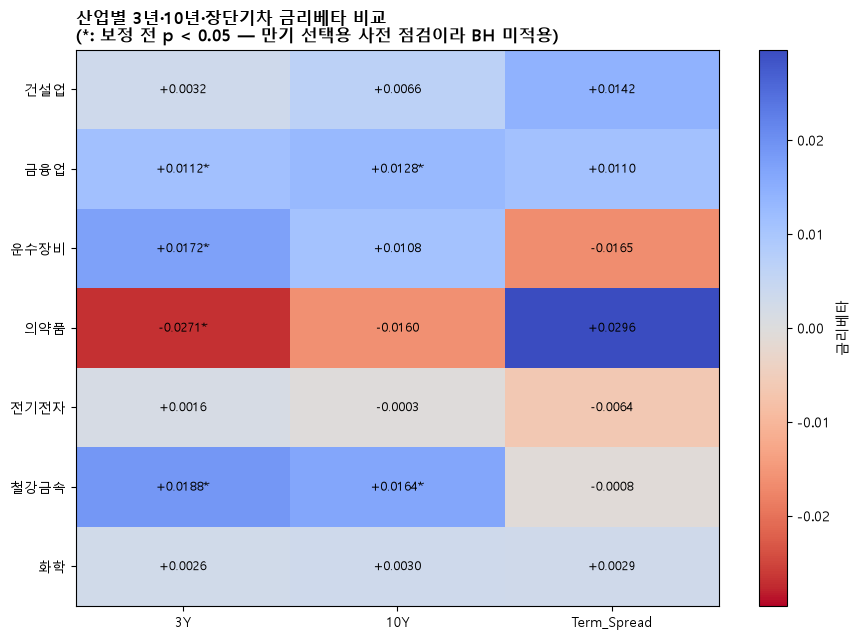

In [8]:
maturity_path = config.H1_TABDIR / "maturity_beta_comparison.csv"

maturity_beta_comparison.to_csv(
    maturity_path,
    index=False,
    encoding="utf-8-sig",
)

maturity_matrix = maturity_beta_comparison.pivot(
    index="industry",
    columns="model",
    values="coefficient",
).reindex(columns=["3Y", "10Y", "Term_Spread"])

maturity_p_matrix = maturity_beta_comparison.pivot(
    index="industry",
    columns="model",
    values="p_value",
).reindex(columns=["3Y", "10Y", "Term_Spread"])

fig, ax = plt.subplots(figsize=(9, 6.5))

max_abs = np.nanmax(np.abs(maturity_matrix.to_numpy()))

image = ax.imshow(
    maturity_matrix.to_numpy(),
    cmap="coolwarm_r",  # 색상은 계수 부호: 음(-) 빨강 / 양(+) 파랑
    vmin=-max_abs,
    vmax=max_abs,
    aspect="auto",
)

ax.set_xticks(np.arange(len(maturity_matrix.columns)))
ax.set_xticklabels(maturity_matrix.columns)
ax.set_yticks(np.arange(len(maturity_matrix.index)))
ax.set_yticklabels(maturity_matrix.index)

for i in range(len(maturity_matrix.index)):
    for j in range(len(maturity_matrix.columns)):
        value = maturity_matrix.iloc[i, j]
        p_value = maturity_p_matrix.iloc[i, j]
        star = "*" if p_value < 0.05 else ""

        ax.text(
            j,
            i,
            f"{value:+.4f}{star}",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_title(
    "산업별 3년·10년·장단기차 금리베타 비교\n(*: 보정 전 p < 0.05 — 만기 선택용 사전 점검이라 BH 미적용)",
    loc="left",
    fontweight="bold",
)

fig.colorbar(image, ax=ax, label="금리베타")
fig.tight_layout()

maturity_fig_path = config.H1_FIGDIR / "01_maturity_beta_comparison_heatmap.png"
fig.savefig(maturity_fig_path, dpi=200, bbox_inches="tight")
plt.show()


> 이 표는 산업별로 국고채 3년·10년·장단기차 각각에 대한 금리베타를 나란히 비교한다.
> 
> - <b>SE</b>: 산업 하나짜리 개별 시계열 회귀이므로 HAC(Newey–West, lag 5). 부록 A 참고.
> - <b>BH family</b>: 만기 비교는 어느 만기를 쓸지 고르기 위한 사전 점검이라 확증 검정이 아니다. 따라서 BH를 적용하지 않고 원 p값만 보고한다.

# PART B. Nelson–Siegel Level·Slope·Curvature 동시모형

## 7단계. Nelson–Siegel 공통 λ

Nelson–Siegel 모형은 각 날짜의 금리를 다음 세 요인으로 설명한다.

$$
y_t(\tau)
=
\beta_{0,t}
+
\beta_{1,t}
\left(\frac{1-e^{-\lambda\tau}}{\lambda\tau}\right)
+
\beta_{2,t}
\left[
\frac{1-e^{-\lambda\tau}}{\lambda\tau}
-
e^{-\lambda\tau}
\right]
$$

- $\beta_0$: Level
- $\beta_1$: Slope
- $\beta_2$: Curvature

### λ는 무엇을 정하나

- λ는 <b>곡률이 어느 만기를 보는지</b>를 정한다. 
- 곡률 loading이 최대가 되는 만기는
$\tau \approx 1.7932/\lambda$ 이므로, <b>λ가 커질수록 곡률이 짧은 만기 쪽을 본다.</b>

### 왜 0.5로 고정하나

| | λ = 0.5 (기본값) | λ = 0.8041 (비교값) |
|---|---|---|
| 선택 기준 | <b>산업별 요인 분리</b> | 곡선 재구성 오차 최소 |
| 곡률이 보는 만기 | 약 3.6년 | 약 2.2년 |
| 곡선 적합도 | 다소 나쁨 | <b>최적</b> |
| 요인 분리 | <b>개선</b> | 나쁨 |

- 이 모형의 목적은 곡선을 정확히 묘사하는 것이 아니라 <b>Level·Slope·Curvature 각각에 대한 산업별 노출을 분리해 추정하는 것</b>이다. 요인이 분리되지 않으면 "어느 요인 때문인가"에 답할 수 없다.

    1. λ=0.8041(곡선 적합 최소)에서는 <b>Slope VIF가 9.5</b>로 요인이 잘 안 나뉜다.
    2. 다중공선성을 최소화하는 값은 0.52 부근 → 소수점을 끌지 않게 <b>0.5로 고정</b>(차이는 무시할 수준).

- <b>두 값은 절충 관계이며 절대적으로 옳은 쪽은 없다.</b> 아래에서 두 값의 적합도·분리도를 나란히 계산하고, 이후 분석은 기본값(0.5)으로 진행한다.

> λ 선택에는 주가·검정통계량이 개입하지 않는다. 국고채 금리만으로 정한다.
> 값은 `config.NS_LAMBDA` 에서 관리한다.

### Decision Box 1 — λ는 0.5로 고정한다

- **문제:** Nelson–Siegel의 감쇠계수 λ는 곡률이 어느 만기를 보는지를 정한다. 이 값을 몇으로 둘 것인가.
- **선택:** <b>0.5</b> (곡률 정점 약 3.6년). `config.NS_LAMBDA`.
- **근거:** 이 모형의 목적은 곡선을 정확히 재현하는 것이 아니라 Level·Slope·Curvature 각각에 대한 산업별 노출을 <b>분리</b>해 추정하는 것이다. 곡선 적합이 가장 좋은 λ=0.8041에서는 요인 간 최대 VIF가 9.46으로 요인이 잘 나뉘지 않는다. VIF를 최소화하는 값은 0.52 부근(최대 VIF 7.06)이라, 소수점을 끌지 않도록 0.5로 반올림했다.
- **결론에 미친 영향:** λ를 0.2~2.0으로 바꿔가며 다시 계산하면 <b>산업 간 곡률 동일성 검정에서 유의한 산업 수는 3개로 전 구간 불변</b>이고, 의약품(p 0.0011~0.0044)·운수장비(p 0.0131~0.0146)는 어떤 λ에서도 유의하다. 반면 개별 계수의 BH 유의 개수는 λ에 민감하다(0~4개). 따라서 <b>"어느 산업이 곡률에 다르게 반응하는가"는 λ에 안정적이고, "몇 개 산업이 개별적으로 유의한가"는 λ에 민감하다</b>고 보고한다.

In [9]:
MATURITIES = np.array([1.0, 3.0, 5.0, 10.0])

def nelson_siegel_loadings(maturities, lambda_value):
    maturities = np.asarray(maturities, dtype=float)

    slope_loading = (
        1.0 - np.exp(-lambda_value * maturities)
    ) / (
        lambda_value * maturities
    )

    curvature_loading = (
        slope_loading - np.exp(-lambda_value * maturities)
    )

    return np.column_stack([
        np.ones_like(maturities),
        slope_loading,
        curvature_loading,
    ])

yield_matrix = yield_wide[
    ["y1", "y3_new", "y5", "y10_new"]
].to_numpy(dtype=float)


def total_reconstruction_sse(lambda_value):
    """주어진 lambda 로 곡선을 재구성했을 때의 전체 제곱오차."""
    if lambda_value <= 0:
        return np.inf

    X = nelson_siegel_loadings(MATURITIES, lambda_value)
    betas = yield_matrix @ np.linalg.pinv(X).T
    return float(np.sum((yield_matrix - betas @ X.T) ** 2))


def factor_separation(lambda_value):
    """요인 간 최대 VIF. 값이 작을수록 요인이 잘 분리된다."""
    X = nelson_siegel_loadings(MATURITIES, lambda_value)
    betas = yield_matrix @ np.linalg.pinv(X).T
    d = pd.DataFrame(betas, columns=["L", "S", "C"]).diff().dropna()
    design = sm.add_constant(d, has_constant="add").to_numpy(dtype=float)
    return max(variance_inflation_factor(design, i + 1) for i in range(3))


# 기본값은 config 에서 가져온다(팀 합의값).
OPTIMAL_LAMBDA = config.NS_LAMBDA
COMPARE_LAMBDA = config.NS_LAMBDA_COMPARE

print(f"{'':10}{'lambda':>9}{'곡률정점':>10}{'재구성SSE':>12}{'최대VIF':>10}")
for lam, tag in [(OPTIMAL_LAMBDA, "기본값"), (COMPARE_LAMBDA, "비교값")]:
    print(f"{tag:<10}{lam:>9.4f}{1.7932/lam:>9.2f}년"
          f"{total_reconstruction_sse(lam):>12.6f}{factor_separation(lam):>10.2f}")

print()
print(f"이후 분석은 기본값 lambda = {OPTIMAL_LAMBDA} 로 진행한다.")
print("선택 기준: 산업별 요인 분리 (config.NS_LAMBDA)")

             lambda      곡률정점      재구성SSE     최대VIF
기본값          0.5000     3.59년    2.027876      7.17
비교값          0.8041     2.23년    1.158238      9.46

이후 분석은 기본값 lambda = 0.5 로 진행한다.
선택 기준: 산업별 요인 분리 (config.NS_LAMBDA)


### 7-1. λ 선택 근거 — 네 가지 기준 비교

- λ는 연구자가 정하는 값이므로 <b>무슨 기준으로 정했는지</b>를 밝혀야 한다.
- 아래 네 기준은 <b>모두 국고채 금리만 사용한다. 주가와 검정통계량은 개입하지 않는다.</b>

| 기준 | 무엇을 최적화하나 |
|---|---|
| 곡선 재구성 오차 최소 | 곡선을 얼마나 정확히 묘사하는가 |
| <b>최대 VIF 최소</b> | <b>요인을 얼마나 잘 분리하는가</b> |
| \|corr(Slope, Curvature)\| 최소 | 두 요인의 직교성 |
| 요인 간 평균 \|상관\| 최소 | 전체 직교성 |

- 이 연구의 목적은 곡선 묘사가 아니라 <b>각 요인에 대한 산업별 노출을 분리해 추정하는 것</b>이므로
<b>요인 분리 기준</b>을 채택한다. 
- 최적값은 0.52 부근이며 0.5로 고정한다.

In [10]:
from scipy.optimize import minimize_scalar


def lambda_diagnostics(lam):
    """λ 하나의 적합도·분리도. 주가는 쓰지 않는다."""
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    rmse = float(np.sqrt(np.mean((yield_matrix - B @ X.T) ** 2)))

    f = pd.DataFrame(B, columns=["Level", "Slope", "Curvature"]).diff().dropna()
    corr = f.corr()
    design = sm.add_constant(f, has_constant="add").to_numpy(dtype=float)
    vifs = [variance_inflation_factor(design, i + 1) for i in range(3)]

    return {"rmse": rmse, "max_vif": max(vifs),
            "abs_corr_SC": abs(float(corr.loc["Slope", "Curvature"])),
            "mean_abs_corr": float(np.mean([abs(corr.loc["Level", "Slope"]),
                                            abs(corr.loc["Slope", "Curvature"]),
                                            abs(corr.loc["Level", "Curvature"])]))}


rows = []
for name, key in [("곡선 재구성 오차 최소", "rmse"),
                  ("최대 VIF 최소 (채택 기준)", "max_vif"),
                  ("|corr(Slope,Curv)| 최소", "abs_corr_SC"),
                  ("요인 간 평균 |상관| 최소", "mean_abs_corr")]:
    r = minimize_scalar(lambda x: lambda_diagnostics(x)[key],
                        bounds=(0.05, 3.0), method="bounded", options={"xatol": 1e-6})
    st = lambda_diagnostics(r.x)
    rows.append({"기준": name, "최적 λ": round(r.x, 4),
                 "곡률정점(년)": round(1.7932 / r.x, 2),
                 "RMSE": round(st["rmse"], 5),
                 "최대VIF": round(st["max_vif"], 2),
                 "|corr(S,C)|": round(st["abs_corr_SC"], 3)})

lambda_criteria = pd.DataFrame(rows)
lambda_criteria.to_csv(config.H1_TABDIR / "lambda_selection_criteria.csv",
                       index=False, encoding="utf-8-sig")
display(lambda_criteria)

print(f"채택값 λ = {OPTIMAL_LAMBDA} (요인 분리 기준 0.52를 반올림)")
print(f"비교값 λ = {COMPARE_LAMBDA} (곡선 적합도 기준)")
print(f"참고: Diebold-Li(2006)는 곡률정점 30개월 고정 → λ = {1.7932/2.5:.4f}")

,기준,최적 λ,곡률정점(년),RMSE,최대VIF,"|corr(S,C)|"
0,곡선 재구성 오차 최소,0.8041,2.23,0.01084,9.46,0.559
1,최대 VIF 최소 (채택 기준),0.5202,3.45,0.01393,7.06,0.214
2,"|corr(Slope,Curv)| 최소",0.4334,4.14,0.01586,7.79,0.000
3,요인 간 평균 |상관| 최소,2.3739,0.76,0.02131,193.18,0.983


채택값 λ = 0.5 (요인 분리 기준 0.52를 반올림)
비교값 λ = 0.8041 (곡선 적합도 기준)
참고: Diebold-Li(2006)는 곡률정점 30개월 고정 → λ = 0.7173


### 7-2. λ 민감도 — 선택이 결론을 바꾸는가

λ를 0.2~2.0으로 바꿔가며 <b>결론이 흔들리는지</b> 확인한다.

- <b>동시검정</b> — 세 요인을 묶은 결과가 λ에 의존하는가
- <b>개별 계수</b> — 어느 요인이 유의해지는가
- <b>요인 겹침</b> — 어느 λ에서도 VIF가 높은가

개별 계수가 λ에 따라 달라지는 것은 요인이 회전하며 배정이 달라지기 때문이다.
<b>핵심은 동시검정 결과가 안정적인가</b>이다.

In [11]:
LAMBDA_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8041, 1.0, 1.5, 2.0]


def lambda_case(lam):
    """λ 하나에 대해 겹침 지표와 회귀 결론을 함께 계산한다."""
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    f = pd.DataFrame(B, index=yield_wide["date"],
                     columns=["L", "S", "C"]).diff().dropna()
    f.columns = ["d_L", "d_S", "d_C"]
    f = f.reset_index()

    dd = extended_panel[["date", "industry", "industry_return", "kospi_return"]]         .merge(f, on="date", how="inner")
    fac = ["d_L", "d_S", "d_C"]

    pvals, joint = [], {}
    for ind, g in dd.groupby("industry"):
        z = g[["industry_return", "kospi_return"] + fac].dropna()
        m = sm.OLS(z["industry_return"],
                   sm.add_constant(z[["kospi_return"] + fac], has_constant="add")
                   ).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        for v in fac:
            pvals.append({"industry": ind, "var": v, "p": m.pvalues[v]})
        joint[ind] = float(m.f_test("d_L = 0, d_S = 0, d_C = 0").pvalue)

    P = pd.DataFrame(pvals)
    P["p_bh"] = P.groupby("var")["p"].transform(
        lambda s: multipletests(s, method="fdr_bh")[1])

    st = lambda_diagnostics(lam)
    return {"lambda": lam, "곡률정점": round(1.7932 / lam, 2),
            "RMSE": round(st["rmse"], 5), "최대VIF": round(st["max_vif"], 2),
            "개별_원p유의": int((P["p"] < 0.05).sum()),
            "개별_BH유의": int((P["p_bh"] < 0.05).sum()),
            "동시검정_유의산업": int(sum(v < 0.05 for v in joint.values())),
            "의약품_동시p": round(joint.get("의약품", np.nan), 5),
            "운수장비_동시p": round(joint.get("운수장비", np.nan), 5)}


lambda_sensitivity = pd.DataFrame([lambda_case(l) for l in LAMBDA_GRID])
lambda_sensitivity.to_csv(config.H1_TABDIR / "lambda_sensitivity.csv",
                          index=False, encoding="utf-8-sig")
display(lambda_sensitivity)

print(f"동시검정 유의 산업 수 범위: "
      f"{lambda_sensitivity['동시검정_유의산업'].min()} ~ "
      f"{lambda_sensitivity['동시검정_유의산업'].max()}")
print(f"최대 VIF 최솟값: {lambda_sensitivity['최대VIF'].min():.2f}")

,lambda,곡률정점,RMSE,최대VIF,개별_원p유의,개별_BH유의,동시검정_유의산업,의약품_동시p,운수장비_동시p
0,0.2000,8.97,0.02214,52.08,3,0,3,0.00440,0.01317
1,0.3000,5.98,0.01929,13.68,5,4,3,0.00371,0.01310
2,0.4000,4.48,0.01668,8.37,4,3,3,0.00314,0.01309
3,0.5000,3.59,0.01435,7.17,3,2,3,0.00268,0.01313
4,0.6000,2.99,0.01248,7.54,3,0,3,0.00232,0.01322
5,0.8041,2.23,0.01084,9.46,1,0,3,0.00181,0.01348
6,1.0000,1.79,0.01196,12.44,1,0,3,0.00151,0.01376
7,1.5000,1.20,0.01720,31.00,1,0,3,0.00117,0.01434
8,2.0000,0.90,0.02023,88.81,1,0,3,0.00106,0.01463


동시검정 유의 산업 수 범위: 3 ~ 3
최대 VIF 최솟값: 7.17


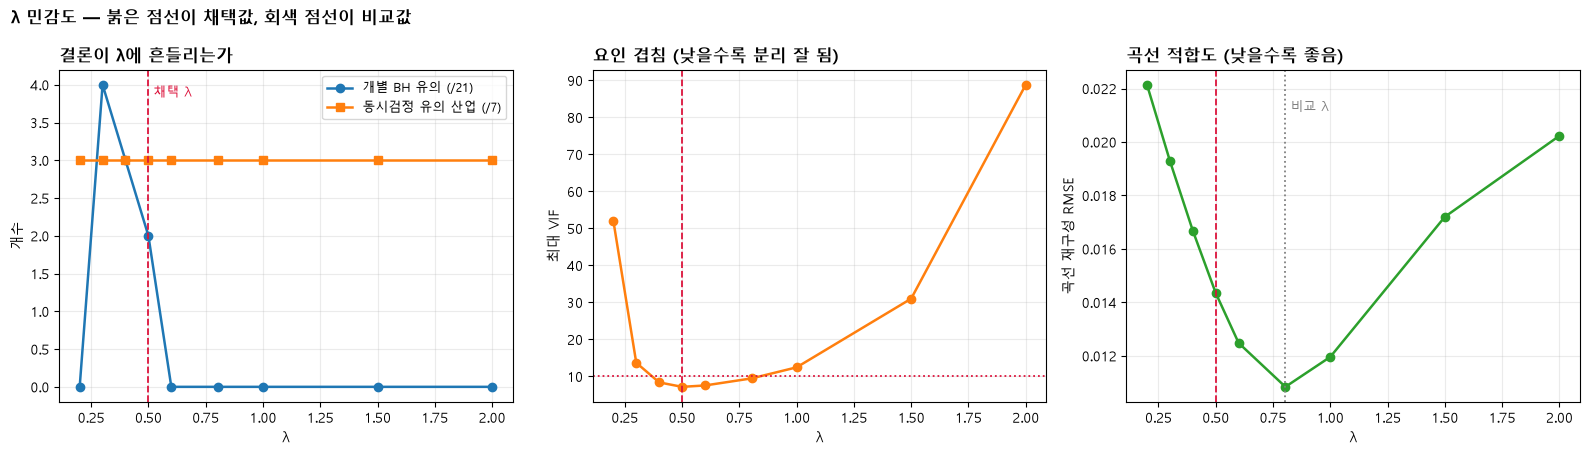

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["개별_BH유의"],
        marker="o", linewidth=1.8, label="개별 BH 유의 (/21)")
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["동시검정_유의산업"],
        marker="s", linewidth=1.8, label="동시검정 유의 산업 (/7)")
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.text(OPTIMAL_LAMBDA, ax.get_ylim()[1] * 0.95, " 채택 λ",
        color="crimson", fontsize=9, va="top")
ax.set_xlabel("λ"); ax.set_ylabel("개수")
ax.set_title("결론이 λ에 흔들리는가", loc="left", fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["최대VIF"],
        marker="o", linewidth=1.8, color="tab:orange")
ax.axhline(10, linestyle=":", color="crimson", linewidth=1.3)
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.set_xlabel("λ"); ax.set_ylabel("최대 VIF")
ax.set_title("요인 겹침 (낮을수록 분리 잘 됨)", loc="left", fontweight="bold")
ax.grid(alpha=0.25)

ax = axes[2]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["RMSE"],
        marker="o", linewidth=1.8, color="tab:green")
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.axvline(COMPARE_LAMBDA, linestyle=":", color="gray", linewidth=1.3)
ax.text(COMPARE_LAMBDA, ax.get_ylim()[1] * 0.95, " 비교 λ",
        color="gray", fontsize=9, va="top")
ax.set_xlabel("λ"); ax.set_ylabel("곡선 재구성 RMSE")
ax.set_title("곡선 적합도 (낮을수록 좋음)", loc="left", fontweight="bold")
ax.grid(alpha=0.25)

fig.suptitle("λ 민감도 — 붉은 점선이 채택값, 회색 점선이 비교값",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(config.H1_FIGDIR / "11_lambda_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()


## 8단계. 날짜별 Level·Slope·Curvature와 변화량 생성

회귀에서는 요인의 수준값이 아니라 <b>일별 변화량</b>을 사용한다.

- `d_ns_level`
- `d_ns_slope`
- `d_ns_curvature`

산업수익률도 일별 변화율이기 때문에 설명변수의 시점 단위를 맞추는 과정이다.

In [13]:
ns_loadings = nelson_siegel_loadings(
    MATURITIES,
    OPTIMAL_LAMBDA,
)

ns_pseudo_inverse = np.linalg.pinv(ns_loadings)
ns_betas = yield_matrix @ ns_pseudo_inverse.T
fitted_yields = ns_betas @ ns_loadings.T

ns_factors = yield_wide[["date"]].copy()
ns_factors["ns_level"] = ns_betas[:, 0]
ns_factors["ns_slope"] = ns_betas[:, 1]
ns_factors["ns_curvature"] = ns_betas[:, 2]

residuals = yield_matrix - fitted_yields
ns_factors["curve_rmse"] = np.sqrt(np.mean(residuals ** 2, axis=1))

for factor in ["ns_level", "ns_slope", "ns_curvature"]:
    ns_factors[f"d_{factor}"] = ns_factors[factor].diff()

print("Nelson–Siegel 요인 생성 완료")
display(ns_factors.head())
display(ns_factors["curve_rmse"].describe().to_frame("curve_rmse"))

Nelson–Siegel 요인 생성 완료


,date,ns_level,ns_slope,ns_curvature,curve_rmse,d_ns_level,d_ns_slope,d_ns_curvature
0,2016-01-04,2.482510,-0.772935,-1.499847,0.004748,NaN,NaN,NaN
1,2016-01-05,2.503357,-0.808165,-1.478302,0.004711,0.020847,-0.035229,0.021545
2,2016-01-06,2.459071,-0.773539,-1.392845,0.006932,-0.044286,0.034626,0.085457
3,2016-01-07,2.415300,-0.741832,-1.303817,0.006067,-0.043771,0.031707,0.089028
4,2016-01-08,2.466221,-0.795600,-1.295521,0.005690,0.050921,-0.053768,0.008296


,curve_rmse
count,2462.000000
mean,0.010496
std,0.009787
min,0.000002
25%,0.003064
50%,0.007294
75%,0.015481
max,0.068426


In [14]:
factor_cols = [
    "date",
    "ns_level",
    "ns_slope",
    "ns_curvature",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "curve_rmse",
]

extended_panel = (
    extended_panel
    .drop(
        columns=[c for c in factor_cols if c != "date" and c in extended_panel.columns],
        errors="ignore",
    )
    .merge(
        ns_factors[factor_cols],
        on="date",
        how="inner",
        validate="many_to_one",
    )
    .sort_values(["date", "industry"])
    .reset_index(drop=True)
)

extended_panel.to_csv(
    config.EXTENDED_PANEL_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Nelson–Siegel 요인까지 포함한 최종 패널 저장 완료")
display(extended_panel.head())

Nelson–Siegel 요인까지 포함한 최종 패널 저장 완료


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,...,corp_aa3,credit_spread,d_credit_spread,ns_level,ns_slope,ns_curvature,d_ns_level,d_ns_slope,d_ns_curvature,curve_rmse
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748



## 9단계. Level·Slope·Curvature 동시모형 추정

각 산업별 회귀식은 다음과 같다.

$$
R_{i,t}
=
\alpha_i
+
\beta_{M,i}R_{M,t}
+
\beta_{L,i}\Delta Level_t
+
\beta_{S,i}\Delta Slope_t
+
\beta_{C,i}\Delta Curvature_t
+
\epsilon_{i,t}
$$

### 왜 세 요인을 동시에 넣나?

- Level·Slope·Curvature가 서로 다른 금리곡선 움직임을 설명하므로, 세 요인을 함께 넣어야 다른 요인을 통제한 뒤 각 요인의 고유한 민감도를 추정할 수 있다.

In [15]:
def run_yield_curve_factor_model(data, hac_lags=5, x_cols=None, factor_labels=None):
    """산업별 다요인 동시모형(HAC). x_cols / factor_labels 로 요인 구성을 바꾼다."""
    if x_cols is None:
        x_cols = [
            "kospi_return",
            "d_ns_level",
            "d_ns_slope",
            "d_ns_curvature",
        ]

    if factor_labels is None:
        factor_labels = {
            "d_ns_level": "Level",
            "d_ns_slope": "Slope",
            "d_ns_curvature": "Curvature",
        }

    rows = []

    for industry, group in data.groupby("industry"):
        reg_data = group[
            ["industry_return"] + x_cols
        ].dropna()

        X = sm.add_constant(
            reg_data[x_cols],
            has_constant="add",
        )
        y = reg_data["industry_return"]

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": hac_lags},
        )

        ci = model.conf_int()

        for variable, factor in factor_labels.items():
            rows.append({
                "industry": industry,
                "factor": factor,
                "variable": variable,
                "coefficient": model.params[variable],
                "std_error_hac": model.bse[variable],
                "t_value": model.tvalues[variable],
                "p_value": model.pvalues[variable],
                "ci_lower_95": ci.loc[variable, 0],
                "ci_upper_95": ci.loc[variable, 1],
                "significant_5pct": model.pvalues[variable] < 0.05,
                "market_beta": model.params["kospi_return"],
                "r_squared": model.rsquared,
                "adj_r_squared": model.rsquared_adj,
                "n_obs": int(model.nobs),
                "hac_lags": hac_lags,
                "optimal_lambda": OPTIMAL_LAMBDA,
            })

    return pd.DataFrame(rows)

yield_curve_factor_betas = run_yield_curve_factor_model(
    extended_panel,
    hac_lags=HAC_LAGS,
)

display(yield_curve_factor_betas.round(6))

,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,건설업,Level,d_ns_level,-0.021038,0.019810,-1.061952,0.288258,-0.059866,0.017790,False,1.013279,0.399432,0.398449,2451,5,0.5
1,건설업,Slope,d_ns_slope,-0.027805,0.018091,-1.536940,0.124308,-0.063263,0.007653,False,1.013279,0.399432,0.398449,2451,5,0.5
2,건설업,Curvature,d_ns_curvature,-0.002338,0.003058,-0.764503,0.444568,-0.008330,0.003655,False,1.013279,0.399432,0.398449,2451,5,0.5
3,금융업,Level,d_ns_level,0.017979,0.008254,2.178290,0.029384,0.001802,0.034156,True,0.925754,0.623471,0.622855,2451,5,0.5
4,금융업,Slope,d_ns_slope,0.007189,0.007423,0.968519,0.332785,-0.007359,0.021737,False,0.925754,0.623471,0.622855,2451,5,0.5
5,금융업,Curvature,d_ns_curvature,0.002413,0.001370,1.762013,0.078067,-0.000271,0.005097,False,0.925754,0.623471,0.622855,2451,5,0.5
6,운수장비,Level,d_ns_level,0.013579,0.012917,1.051196,0.293168,-0.011739,0.038896,False,1.006309,0.472321,0.471458,2451,5,0.5
7,운수장비,Slope,d_ns_slope,0.009915,0.012103,0.819256,0.412641,-0.013806,0.033636,False,1.006309,0.472321,0.471458,2451,5,0.5
8,운수장비,Curvature,d_ns_curvature,0.006207,0.002310,2.687189,0.007206,0.001680,0.010735,True,1.006309,0.472321,0.471458,2451,5,0.5
9,의약품,Level,d_ns_level,-0.013817,0.015855,-0.871495,0.383484,-0.044891,0.017257,False,0.789172,0.243525,0.242288,2451,5,0.5



## 10단계. 산업별 계수·SE·t·p·95% 신뢰구간 표 저장

이 표가 Nelson–Siegel 다요인 모형의 핵심 결과표다.

- `coefficient`: 산업별 민감도
- `std_error_hac`: HAC 표준오차
- `t_value`: t 통계량
- `p_value`: 유의확률
- `ci_lower_95`, `ci_upper_95`: 95% 신뢰구간

> SE: 이 표는 산업별로 따로 돌린 개별 시계열 회귀이므로 HAC를 쓴다. 뒤의 산업 간 차이 검정은 7개 산업이 한 식에 들어가는 통합회귀라 날짜 클러스터를 쓴다. 기준은 가설이 아니라 회귀 형태다 — 전체 내역은 <b>부록 A</b> 참고.
>
> BH family: (모형, 요인) 안의 7개 산업. 검정 개수·보정 전후 p값은 <b>부록 B</b> 참고.

In [16]:
# BH(FDR) 보정 공통 함수 — 14단계뿐 아니라 10단계 핵심 결과표에서도 쓰므로 여기서 한 번만 정의한다.
def add_bh_correction(result, group_cols=("model", "factor"),
                      p_col="p_value", alpha=0.05):
    """검정족별 BH(FDR) 보정 p값을 붙인다. 원 p_value 는 그대로 둔다."""
    out = result.copy()
    group_cols = list(group_cols)

    out["p_value_bh"] = np.nan
    out["bh_n_tests"] = 0

    groupby_arg = group_cols[0] if len(group_cols) == 1 else group_cols
    for keys, idx in out.groupby(groupby_arg).groups.items():
        pvals = out.loc[idx, p_col].to_numpy(dtype=float)
        out.loc[idx, "p_value_bh"] = multipletests(pvals, method="fdr_bh")[1]
        out.loc[idx, "bh_n_tests"] = len(pvals)

    # 어떤 단위로 보정했는지 표에 남겨 두어야 나중에 재검토가 가능하다.
    out["bh_family"] = out[group_cols].astype(str).agg(" | ".join, axis=1)
    out["significant_5pct_bh"] = out["p_value_bh"] < alpha

    return out

In [17]:
factor_path = config.H1_TABDIR / "yield_curve_factor_betas.csv"

# BH(FDR) 보정을 붙인다. 검정족 = (모형, 요인) 안의 7개 산업.
# "Curvature에 대해 산업들이 다르게 반응하는가"가 하나의 연구질문이므로 그 단위로 묶는다.
# 요인을 가로질러 21개를 한 번에 묶으면 Level·Slope의 비유의 결과가 Curvature의
# 임계값을 끌어올려 검정력만 잃는다 (Decision Box 3).
yield_curve_factor_betas = add_bh_correction(
    yield_curve_factor_betas.assign(model="B_ThreeFactor"),
    group_cols=("model", "factor"),
)

yield_curve_factor_betas.to_csv(
    factor_path,
    index=False,
    encoding="utf-8-sig",
)

print("BH family별 검정 개수")
print(yield_curve_factor_betas.groupby("bh_family")["p_value_bh"].agg(["size", "min"]).round(5))

BH family별 검정 개수
                           size      min
bh_family                               
B_ThreeFactor | Curvature     7  0.01654
B_ThreeFactor | Level         7  0.20569
B_ThreeFactor | Slope         7  0.62253


> 이 표가 Nelson–Siegel 3요인 모형의 핵심 결과표다.
> 
> - <b>SE</b>: 산업별 개별 시계열 회귀이므로 HAC(Newey–West, lag 5). 부록 A 참고.
> - <b>BH family</b>: (모형, 요인) 조합 안의 7개 산업이 한 족이다 — `B_ThreeFactor | Level`, `B_ThreeFactor | Slope`, `B_ThreeFactor | Curvature` 로 3개 족(각 7개 검정). 보정 전후 p값은 부록 B 참고.


## 11단계. 산업별 수익률곡선 요인 민감도 Heatmap

한 산업이 Level·Slope·Curvature 중 어떤 요인에 상대적으로 더 크게 반응하는지 한눈에 비교한다.

별표는 BH 보정 후 5% 수준에서 유의함을 의미한다. 검정족은 요인 하나당 7개 산업이다.

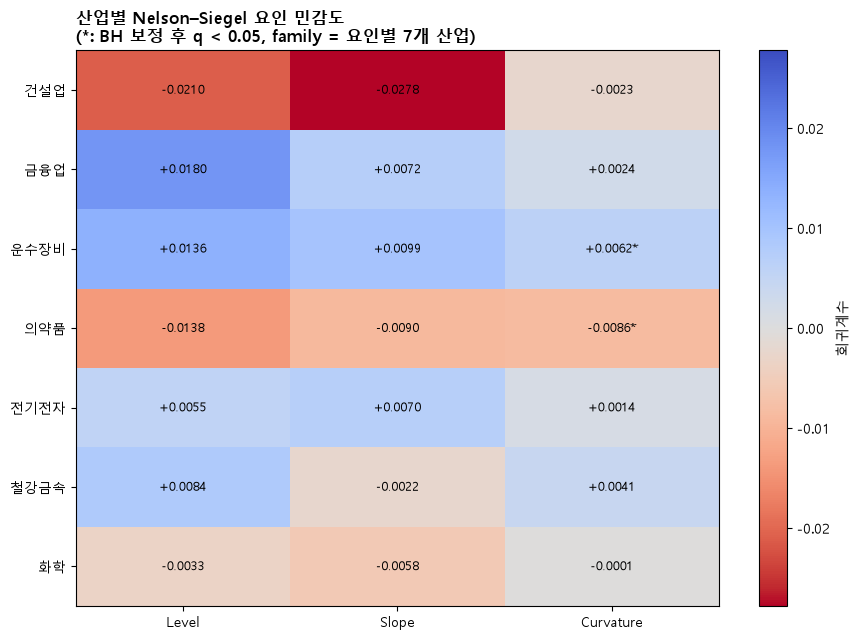

In [18]:
factor_order = ["Level", "Slope", "Curvature"]

coef_matrix = yield_curve_factor_betas.pivot(
    index="industry",
    columns="factor",
    values="coefficient",
).reindex(columns=factor_order)

# 별표는 BH 보정 후 q값 기준이다. 표에서 BH로 판정하고 그림에서 원 p로 별표를 찍으면
# 같은 결과를 두 기준으로 말하게 되므로, 04·07과 마찬가지로 BH 기준으로 통일한다.
p_matrix = yield_curve_factor_betas.pivot(
    index="industry",
    columns="factor",
    values="p_value_bh",
).reindex(index=coef_matrix.index, columns=factor_order)

fig, ax = plt.subplots(figsize=(9, 6.5))

max_abs = np.nanmax(np.abs(coef_matrix.to_numpy()))

image = ax.imshow(
    coef_matrix.to_numpy(),
    cmap="coolwarm_r",  # 색상은 계수 부호: 음(-) 빨강 / 양(+) 파랑
    vmin=-max_abs,
    vmax=max_abs,
    aspect="auto",
)

ax.set_xticks(np.arange(len(factor_order)))
ax.set_xticklabels(factor_order)
ax.set_yticks(np.arange(len(coef_matrix.index)))
ax.set_yticklabels(coef_matrix.index)

for i in range(len(coef_matrix.index)):
    for j in range(len(factor_order)):
        value = coef_matrix.iloc[i, j]
        p_value = p_matrix.iloc[i, j]
        star = "*" if p_value < 0.05 else ""

        ax.text(
            j,
            i,
            f"{value:+.4f}{star}",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_title(
    "산업별 Nelson–Siegel 요인 민감도\n(*: BH 보정 후 q < 0.05, family = 요인별 7개 산업)",
    loc="left",
    fontweight="bold",
)

fig.colorbar(image, ax=ax, label="회귀계수")
fig.tight_layout()

factor_fig_path = config.H1_FIGDIR / "02_yield_curve_factor_beta_heatmap.png"
fig.savefig(factor_fig_path, dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 색은 요인별 산업 계수(음=빨강 / 양=파랑), 별표는 BH 보정 후 5% 유의.
- 별표가 붙는 칸은 <b>Curvature의 의약품(q=0.0165)·운수장비(q=0.0252)</b> 둘뿐이다.
- 금융업 Level은 보정 전 p=0.0294로 5%를 넘지만 BH 보정 후 q=0.206으로 유의하지 않다. 7개 산업을 한 검정족으로 묶으면 이 정도 크기는 우연으로 설명되는 범위다.
- 유의한 칸이 둘뿐이라 세 요인이 산업수익률을 고르게 가르지는 않는다. 가르는 축은 Curvature 하나다.


## 12단계. 요인별 계수 플롯

각 요인에 대해 산업별 계수와 95% 신뢰구간을 비교한다.

신뢰구간이 0을 지나지 않으면 해당 요인의 산업별 민감도가 5% 수준에서 유의하다.

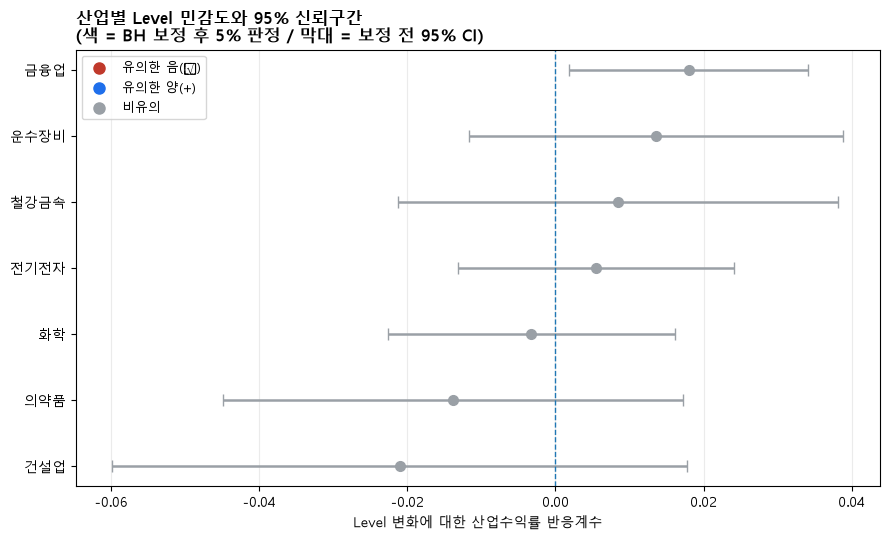

저장 완료: results\H1_yield_curve\figures\03_level_coefficient_plot.png


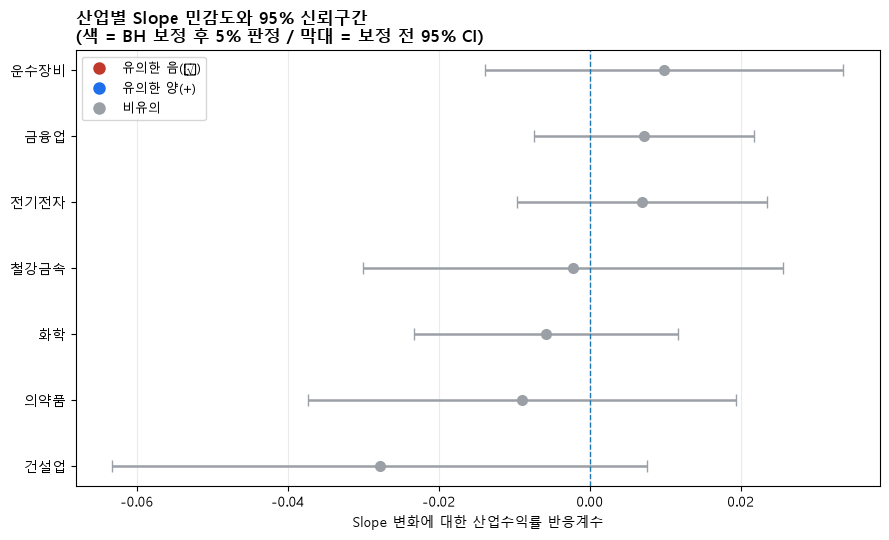

저장 완료: results\H1_yield_curve\figures\03_slope_coefficient_plot.png


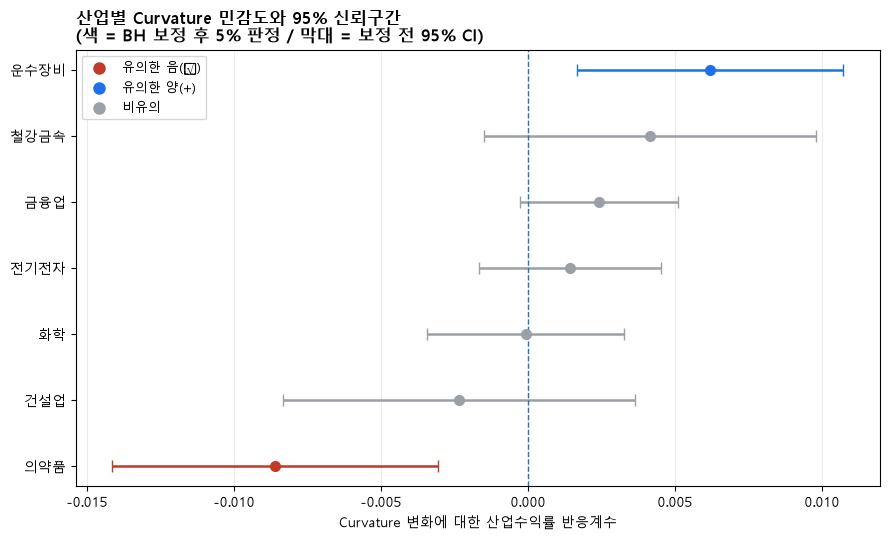

저장 완료: results\H1_yield_curve\figures\03_curvature_coefficient_plot.png


In [19]:
for factor in factor_order:
    plot_data = (
        yield_curve_factor_betas[
            yield_curve_factor_betas["factor"] == factor
        ]
        .sort_values("coefficient")
        .reset_index(drop=True)
    )

    y_pos = np.arange(len(plot_data))

    lower_error = (
        plot_data["coefficient"] - plot_data["ci_lower_95"]
    )
    upper_error = (
        plot_data["ci_upper_95"] - plot_data["coefficient"]
    )

    # 색상은 계수 부호를 나타낸다. 유의 판정은 BH 보정 후 q < 0.05 기준이다.
    # 오차막대는 보정하지 않은 95% 신뢰구간이므로, 구간이 0을 벗어나도 회색일 수 있다.
    point_colors = [
        config.sign_color(coef, sig)
        for coef, sig in zip(plot_data["coefficient"], plot_data["significant_5pct_bh"])
    ]

    fig, ax = plt.subplots(figsize=(9, 5.5))

    for y, coef, lo, hi, color in zip(
        y_pos, plot_data["coefficient"], lower_error, upper_error, point_colors,
    ):
        ax.errorbar(
            coef, y,
            xerr=[[lo], [hi]],
            fmt="o",
            capsize=4,
            linewidth=1.8,
            markersize=7,
            color=color,
            ecolor=color,
        )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_data["industry"])
    ax.set_xlabel(f"{factor} 변화에 대한 산업수익률 반응계수")
    ax.set_title(
        f"산업별 {factor} 민감도와 95% 신뢰구간\n(색 = BH 보정 후 5% 판정 / 막대 = 보정 전 95% CI)",
        loc="left",
        fontweight="bold",
    )
    ax.grid(axis="x", alpha=0.25)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["ns"], label="비유의"),
    ]
    ax.legend(handles=legend_handles, loc="best", frameon=True, fontsize=9)

    fig.tight_layout()

    path = config.H1_FIGDIR / f"03_{factor.lower()}_coefficient_plot.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

    print("저장 완료:", config._rel(path))

### 관찰 결과

- 오차막대는 보정하지 않은 95% 신뢰구간, 점의 색은 BH 보정 후 판정이다. 둘은 기준이 달라 어긋날 수 있다.
- Curvature에서 의약품(음)·운수장비(양)가 0을 벗어나고 BH 보정 후에도 유의하다.
- 금융업 Level은 신뢰구간이 0을 살짝 벗어나지만(보정 전 p=0.0294) 보정 후에는 유의하지 않아 회색으로 표시된다.
- 산업 간 차이는 주로 Curvature 축에서 관측된다.

### 비유의 결과도 본문 결과다 (§4.1)

- Level·Slope는 <b>BH 보정 후 어느 산업에서도 유의하지 않다</b>. 이는 부수적 누락이 아니라 <b>계획된 검정의 결과</b>다.
- 보정 전 기준으로는 금융업 Level 하나가 p=0.0294로 5%를 넘지만, 7개 산업을 한 검정족으로 묶으면 q=0.206이 되어 남지 않는다. 보정 전후를 모두 부록 B에 적어 두었다.
- 곡선 대부분이 평행이동으로 움직이고 Slope·Curvature가 따로 움직이는 몫이 작다는 PCA·VIF 결과와 정합적이다(D-0·15단계).
- 따라서 사전 계획된 비유의 결과는 부록이 아니라 본문에 남긴다.

## 12-1. 관측금리 나비 스프레드로 본 곡률 측정방식 민감도

NS 곡률은 λ에 따라 값이 달라진다(7-2 참고). λ를 전혀 쓰지 않는 관측금리 조합(나비 스프레드)으로 곡률을 다시 만들어, NS 곡률과 같은 방향을 가리키는지 비교한다.
<b>대체가 아니라 병기</b>다 — 두 방식을 비교한 정보 자체가 결과다.

### Decision Box 2 — 나비 스프레드는 중심 3년, 날개 1·5년으로 만든다

- **문제:** 관측금리만으로 곡률을 만들 때 어느 만기를 중심에 두고 어느 만기를 날개로 쓸 것인가.
- **선택:** 중심 3년, 날개 1·5년. Curvature = 2·Δy3 − Δy1 − Δy5, Level = ¼(Δy1+Δy3+Δy5+Δy10), Slope = Δy10 − Δy1.
- **근거:** 3년이 1년과 5년의 정확한 중점이므로 이 조합은 <b>곡선의 평행이동(Level)과 선형 기울기(Slope)에 정확히 0</b>이 된다. 즉 순수하게 굽음만 뽑아낸다. λ=0.5의 곡률 정점(약 3.6년)과도 가까워 NS 곡률과 직접 비교할 수 있다.
- **결론에 미친 영향:** 두 방식의 곡률 계열 상관은 <b>0.83</b>이고, 7개 산업 중 <b>4개에서 부호가 일치</b>한다. 의약품은 두 방식 모두에서 음(−)이고 개별적으로 유의하다(NS p=0.0024, 나비 p=0.0048). 그러나 산업 간 계수 동일성 검정은 NS Curvature에서만 유의하고 나비 Curvature에서는 유의하지 않으므로, 전체 산업의 곡률 이질성은 곡률 구성 방식에 민감한 조건부 결과다.

,factor,corr_NS_butterfly
0,Level,0.5933
1,Slope,-0.9935
2,Curvature,0.8330


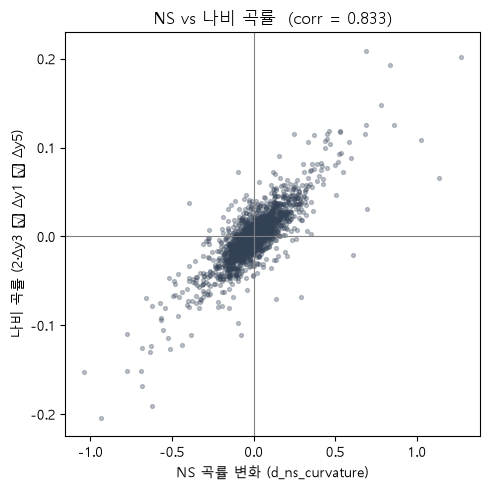

In [20]:
# 관측금리 나비 스프레드 프록시 (λ 불필요) — 대체가 아니라 NS와 병기해 비교 (교수 §4.2)
extended_panel["bfly_level"] = (
    extended_panel["d_y1"] + extended_panel["d_y3_new"]
    + extended_panel["d_y5"] + extended_panel["d_y10_new"]
) / 4                                                              # 4개 만기 평균 = 수준
extended_panel["bfly_slope"] = extended_panel["d_y10_new"] - extended_panel["d_y1"]        # Δy10 − Δy1 = 기울기
extended_panel["bfly_curvature"] = (
    2 * extended_panel["d_y3_new"] - extended_panel["d_y1"] - extended_panel["d_y5"]        # 2Δy3 − Δy1 − Δy5
)                                                                  # 곡률 (Level·Slope에 정확히 중립)

_fac = extended_panel.drop_duplicates("date")
ns_bfly_corr = pd.DataFrame([
    {"factor": lab, "corr_NS_butterfly": _fac[ns].corr(_fac[bf])}
    for lab, ns, bf in [("Level", "d_ns_level", "bfly_level"),
                        ("Slope", "d_ns_slope", "bfly_slope"),
                        ("Curvature", "d_ns_curvature", "bfly_curvature")]
])
display(ns_bfly_corr.round(4))
ns_bfly_corr.to_csv(config.H1_TABDIR / "ns_vs_butterfly_factor_corr.csv",
                    index=False, encoding="utf-8-sig")

_c = _fac[["d_ns_curvature", "bfly_curvature"]].dropna()
_r = _c["d_ns_curvature"].corr(_c["bfly_curvature"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(_c["d_ns_curvature"], _c["bfly_curvature"], s=8, alpha=0.3, color="#334155")
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("NS 곡률 변화 (d_ns_curvature)")
ax.set_ylabel("나비 곡률 (2·Δy3 − Δy1 − Δy5)")
ax.set_title(f"NS vs 나비 곡률  (corr = {_r:.3f})")
fig.tight_layout()
fig.savefig(config.H1_FIGDIR / "ns_vs_butterfly_curvature.png", dpi=120, bbox_inches="tight")
plt.show()

In [21]:
# 산업 수준 병기: 같은 산업 모형을 나비 곡률로 다시 추정해 NS 곡률 결과와 비교
_bf_fit = run_yield_curve_factor_model(
    extended_panel, hac_lags=HAC_LAGS,
    x_cols=["kospi_return", "bfly_level", "bfly_slope", "bfly_curvature"],
    factor_labels={"bfly_level": "Level", "bfly_slope": "Slope", "bfly_curvature": "Curvature"},
)
_ns_curv = (yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
            [["industry", "coefficient", "p_value"]]
            .rename(columns={"coefficient": "NS_곡률β", "p_value": "NS_p"}))
_bf_curv = (_bf_fit[_bf_fit["factor"] == "Curvature"]
            [["industry", "coefficient", "p_value"]]
            .rename(columns={"coefficient": "나비_곡률β", "p_value": "나비_p"}))
curvature_ns_vs_butterfly = _ns_curv.merge(_bf_curv, on="industry")
curvature_ns_vs_butterfly["부호일치"] = (
    np.sign(curvature_ns_vs_butterfly["NS_곡률β"]) == np.sign(curvature_ns_vs_butterfly["나비_곡률β"])
)
display(curvature_ns_vs_butterfly.round(5))
curvature_ns_vs_butterfly.to_csv(
    config.H1_TABDIR / "curvature_ns_vs_butterfly_by_industry.csv",
    index=False, encoding="utf-8-sig")

,industry,NS_곡률β,NS_p,나비_곡률β,나비_p,부호일치
0,건설업,-0.00234,0.44457,0.00279,0.82073,False
1,금융업,0.00241,0.07807,-0.00078,0.91779,False
2,운수장비,0.00621,0.00721,0.01042,0.30881,True
3,의약품,-0.00860,0.00236,-0.04014,0.00480,True
4,전기전자,0.00144,0.36228,0.00015,0.98287,True
5,철강금속,0.00415,0.14948,0.01624,0.18079,True
6,화학,-0.00008,0.96244,0.00258,0.76441,False


### 관찰 결과

- 요인 수준에서 NS 곡률과 나비 곡률의 상관은 약 <b>0.83</b>(Level 0.59). 곡률은 λ를 쓰지 않은 관측금리 조합으로도 거의 같은 방향으로 움직인다.
- 산업별 개별 회귀에서는 의약품의 음(−) 곡률 반응이 두 방식 모두 유의하다(NS p≈0.002, 나비 p≈0.005). 다만 이는 개별 산업 수준의 신호다.
- 산업 간 계수 동일성 검정에서는 NS Curvature가 유의하지만(F≈3.580, BH p≈0.0047), 나비 Curvature는 유의하지 않다(F≈1.706, raw p≈0.1155, BH p≈0.2794).
- 따라서 전체 산업의 곡률 이질성이 λ 또는 곡률 구성 방식에 강건하다고 해석할 수 없다. 의약품의 음(−) 반응만 두 측정 방식에서 공통적으로 관찰되는 제한적 신호로 남는다. 원계수·상관은 결과표(`ns_vs_butterfly_factor_corr.csv`, `curvature_ns_vs_butterfly_by_industry.csv`)에 저장한다.

# PART C. Credit Spread 추가 민감도 점검 (B-2)

## 12단계. Credit Spread 단독모형

먼저 Credit Spread 하나만 넣은 2지수 모형을 본다.

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{Credit,i}\Delta CreditSpread_t+\epsilon_{i,t}
$$

- 5단계에서 만든 `run_single_rate_models()`를 `model_specs` 인자만 바꿔 그대로 재사용한다.
새 함수를 만들지 않으므로 만기별 비교 결과는 영향을 받지 않는다.

### 부호를 어떻게 읽나 (결과를 보기 전에 먼저 적어 둔다)

- `d_credit_spread`가 양(+)이라는 것은 <b>신용스프레드 확대 = 신용위험 악화</b>를 뜻한다.
- 따라서 계수가 음(−)이면 신용위험이 커질 때 그 산업 주가가 더 많이 떨어진다는 의미다.

    - <b>건설업·화학·철강금속</b> — 레버리지가 높고 경기민감도가 커서 음(−) 예상
    - <b>의약품</b> — 방어적 성격이 강해 0에 가까울 것으로 예상
    - <b>금융업 — 사전 예상 없음 </b>

- 금융업을 왜 비워 두는지는 아래 13단계 뒤에 따로 적는다.

In [22]:
# Credit Spread 단독모형.
# model_specs 만 갈아끼우고 함수는 5단계 것을 그대로 쓴다.
credit_spread_single = run_single_rate_models(
    extended_panel,
    hac_lags=HAC_LAGS,
    model_specs={"Credit_Spread": "d_credit_spread"},
)

display(credit_spread_single.round(6))

,industry,model,rate_variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,n_obs,hac_lags
0,건설업,Credit_Spread,d_credit_spread,-0.006627,0.033401,-0.198415,0.842721,-0.072092,0.058838,False,1.015018,0.398200,2451,5
1,금융업,Credit_Spread,d_credit_spread,-0.035308,0.020979,-1.682981,0.092379,-0.076427,0.005811,False,0.925408,0.622364,2451,5
2,운수장비,Credit_Spread,d_credit_spread,-0.057150,0.030019,-1.903785,0.056938,-0.115986,0.001686,False,1.002731,0.471308,2451,5
3,의약품,Credit_Spread,d_credit_spread,0.110007,0.041327,2.661862,0.007771,0.029007,0.191007,True,0.793752,0.242992,2451,5
4,전기전자,Credit_Spread,d_credit_spread,-0.001354,0.018067,-0.074965,0.940242,-0.036765,0.034056,False,1.205398,0.719268,2451,5
5,철강금속,Credit_Spread,d_credit_spread,-0.064747,0.028716,-2.254782,0.024147,-0.121029,-0.008466,True,1.023287,0.382886,2451,5
6,화학,Credit_Spread,d_credit_spread,0.018430,0.019754,0.932976,0.350832,-0.020287,0.057147,False,1.053827,0.643730,2451,5


## 13단계. Credit Spread 포함 확장모형

$$
R_{i,t}
=
\alpha_i
+
\beta_{M,i}R_{M,t}
+
\beta_{L,i}\Delta Level_t
+
\beta_{S,i}\Delta Slope_t
+
\beta_{C,i}\Delta Curvature_t
+
\beta_{Credit,i}\Delta CreditSpread_t
+
\epsilon_{i,t}
$$

9단계의 `run_yield_curve_factor_model()`에 `x_cols`·`factor_labels`만 넘겨 재사용한다.

### 주의 — 9단계 계수는 바뀌는 것이 정상이다

- 설명변수를 추가하면 기존 Level·Slope·Curvature 계수는 <b>반드시</b> 달라진다 — 통제변수를 넣는 목적이므로 오류가 아니다.
- 강건성 판단 기준은 <b>부호와 유의성이 유지되는가</b>이다.
- B-1의 `yield_curve_factor_betas.csv`는 건드리지 않고, 확장모형은 `credit_spread_betas.csv`에 4개 요인을 담아 따로 저장한다(나란히 비교용).

In [23]:
# 확장모형: 기존 3요인 + Credit Spread
CREDIT_X_COLS = [
    "kospi_return",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "d_credit_spread",
]

CREDIT_FACTOR_LABELS = {
    "d_ns_level": "Level",
    "d_ns_slope": "Slope",
    "d_ns_curvature": "Curvature",
    "d_credit_spread": "CreditSpread",
}

credit_spread_extended = run_yield_curve_factor_model(
    extended_panel,
    hac_lags=HAC_LAGS,
    x_cols=CREDIT_X_COLS,
    factor_labels=CREDIT_FACTOR_LABELS,
)

display(credit_spread_extended.round(6))

,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,건설업,Level,d_ns_level,-0.021001,0.020021,-1.048935,0.294208,-0.060241,0.018240,False,1.013283,0.399432,0.398204,2451,5,0.5
1,건설업,Slope,d_ns_slope,-0.027787,0.018219,-1.525172,0.127216,-0.063495,0.007921,False,1.013283,0.399432,0.398204,2451,5,0.5
2,건설업,Curvature,d_ns_curvature,-0.002313,0.003354,-0.689571,0.490464,-0.008888,0.004261,False,1.013283,0.399432,0.398204,2451,5,0.5
3,건설업,CreditSpread,d_credit_spread,0.000816,0.036832,0.022153,0.982326,-0.071374,0.073006,False,1.013283,0.399432,0.398204,2451,5,0.5
4,금융업,Level,d_ns_level,0.016651,0.008259,2.016157,0.043784,0.000464,0.032838,True,0.925611,0.623810,0.623041,2451,5,0.5
5,금융업,Slope,d_ns_slope,0.006531,0.007489,0.872113,0.383147,-0.008147,0.021209,False,0.925611,0.623810,0.623041,2451,5,0.5
6,금융업,Curvature,d_ns_curvature,0.001543,0.001584,0.974326,0.329895,-0.001561,0.004648,False,0.925611,0.623810,0.623041,2451,5,0.5
7,금융업,CreditSpread,d_credit_spread,-0.029060,0.024413,-1.190334,0.233915,-0.076908,0.018789,False,0.925611,0.623810,0.623041,2451,5,0.5
8,운수장비,Level,d_ns_level,0.012290,0.012796,0.960495,0.336806,-0.012789,0.037370,False,1.006170,0.472527,0.471448,2451,5,0.5
9,운수장비,Slope,d_ns_slope,0.009277,0.012030,0.771116,0.440638,-0.014302,0.032855,False,1.006170,0.472527,0.471448,2451,5,0.5


### 금융업에 방향을 가정하지 않는 이유

1. 금융업은 신용스프레드 확대가 서로 반대 방향으로 작동한다.

    - <b>음(−) 방향</b> — 차주 부실 위험 증가, 대손충당금 부담, 조달비용 상승
    - <b>양(+) 방향</b> — 대출 스프레드 확대에 따른 마진 개선, 위험보상 상승

2. 국내 '금융업' 지수는 은행·보험·증권이 섞여 있어 하위업종별 반응이 상쇄될 수 있다.
3. 둘 중 어느 쪽이 클지는 이론적으로 결정되지 않으므로, 금융업은 <b>사전 예상 없음</b> 으로 둔다.

4. 결과를 본 뒤 설명을 만들어 붙이는 것을 막기 위한 장치다.
    - 금융업 계수가 어떤 부호로 나오든, 그 부호에 맞춘 사후 가설로 바꾸어 적지 않는다.
    - 결과는 그대로 보고하고, 해석은 <b>탐색적</b> 이라고 명시한다.

## 14단계. BH(FDR) 보정과 결과표 저장

### Decision Box 3 — BH 검정족은 (모형, 요인) 안의 7개 산업

- **문제:** 이 노트북은 모형(2요인·3요인·4요인·직교화)과 요인(Level·Slope·Curvature·CreditSpread)의 조합마다 7개 산업을 검정한다. 어디까지를 한 묶음으로 보고 보정할 것인가.
- **선택:** <b>(모형, 요인) 조합 하나 안의 7개 산업</b>을 하나의 검정족으로 본다. Baseline(05)·비대칭(07)과 섞지 않는다.
- **근거:** "이 요인에 대해 산업들이 다르게 반응하는가"가 하나의 연구질문이고, BH는 그 질문 단위로 FDR을 통제해야 의미가 있다. 요인을 가로질러 28개(7산업×4요인)를 한 번에 묶으면 Level의 비유의 결과가 Curvature의 임계값을 끌어올려 검정력만 잃는다. 04의 `industry_rate_betas()`도 한 모형의 7개 산업에 같은 방식으로 보정하므로 새 기준이 아니라 기존 선례를 따르는 것이다.
- **결론에 미친 영향:** λ=0.5의 3요인 모형에서는 Curvature에 대해 <b>의약품(q=0.0165)·운수장비(q=0.0252)</b>의 개별 계수와 산업 간 차이 검정(<b>q=0.0047</b>)이 유의하고, Level·Slope는 유의하지 않다. 그러나 대체 λ와 나비 곡률에서는 산업 간 차이가 유지되지 않으므로, 이는 λ=0.5의 요인 구성에서 관찰된 조건부 패턴으로만 해석한다.

> 전체(Baseline·H1·H2) 일괄 보정 결과는 <b>부록 B</b>에 병기했다.

In [24]:
# 단독모형과 확장모형의 컬럼 구성을 맞춘 뒤 하나의 표로 합친다.
# (단독모형은 rate_variable, 확장모형은 variable/factor 를 쓴다)
credit_single_norm = (
    credit_spread_single
    .rename(columns={"rate_variable": "variable"})
    .assign(
        model="A_Credit_Single",
        factor="CreditSpread",
        adj_r_squared=np.nan,
        optimal_lambda=np.nan,
    )
)

credit_extended_norm = credit_spread_extended.assign(model="B_Extended_4Factor")

CREDIT_TABLE_COLS = [
    "model",
    "industry",
    "factor",
    "variable",
    "coefficient",
    "std_error_hac",
    "t_value",
    "p_value",
    "p_value_bh",
    "bh_family",
    "bh_n_tests",
    "ci_lower_95",
    "ci_upper_95",
    "significant_5pct",
    "significant_5pct_bh",
    "market_beta",
    "r_squared",
    "adj_r_squared",
    "n_obs",
    "hac_lags",
    "optimal_lambda",
]

credit_spread_betas = (
    pd.concat([credit_single_norm, credit_extended_norm], ignore_index=True)
    .pipe(add_bh_correction, group_cols=("model", "factor"))
    .sort_values(["model", "factor", "industry"])
    .reset_index(drop=True)
    .reindex(columns=CREDIT_TABLE_COLS)
)

credit_path = config.H1_TABDIR / "credit_spread_betas.csv"

credit_spread_betas.to_csv(
    credit_path,
    index=False,
    encoding="utf-8-sig",
)

display(credit_spread_betas.round(6))

,model,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,p_value_bh,bh_family,...,ci_lower_95,ci_upper_95,significant_5pct,significant_5pct_bh,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,A_Credit_Single,건설업,CreditSpread,d_credit_spread,-0.006627,0.033401,-0.198415,0.842721,0.940242,A_Credit_Single | CreditSpread,...,-0.072092,0.058838,False,False,1.015018,0.398200,NaN,2451,5,NaN
1,A_Credit_Single,금융업,CreditSpread,d_credit_spread,-0.035308,0.020979,-1.682981,0.092379,0.161663,A_Credit_Single | CreditSpread,...,-0.076427,0.005811,False,False,0.925408,0.622364,NaN,2451,5,NaN
2,A_Credit_Single,운수장비,CreditSpread,d_credit_spread,-0.057150,0.030019,-1.903785,0.056938,0.132856,A_Credit_Single | CreditSpread,...,-0.115986,0.001686,False,False,1.002731,0.471308,NaN,2451,5,NaN
3,A_Credit_Single,의약품,CreditSpread,d_credit_spread,0.110007,0.041327,2.661862,0.007771,0.054397,A_Credit_Single | CreditSpread,...,0.029007,0.191007,True,False,0.793752,0.242992,NaN,2451,5,NaN
4,A_Credit_Single,전기전자,CreditSpread,d_credit_spread,-0.001354,0.018067,-0.074965,0.940242,0.940242,A_Credit_Single | CreditSpread,...,-0.036765,0.034056,False,False,1.205398,0.719268,NaN,2451,5,NaN
5,A_Credit_Single,철강금속,CreditSpread,d_credit_spread,-0.064747,0.028716,-2.254782,0.024147,0.084515,A_Credit_Single | CreditSpread,...,-0.121029,-0.008466,True,False,1.023287,0.382886,NaN,2451,5,NaN
6,A_Credit_Single,화학,CreditSpread,d_credit_spread,0.018430,0.019754,0.932976,0.350832,0.491165,A_Credit_Single | CreditSpread,...,-0.020287,0.057147,False,False,1.053827,0.643730,NaN,2451,5,NaN
7,B_Extended_4Factor,건설업,CreditSpread,d_credit_spread,0.000816,0.036832,0.022153,0.982326,0.982326,B_Extended_4Factor | CreditSpread,...,-0.071374,0.073006,False,False,1.013283,0.399432,0.398204,2451,5,0.5
8,B_Extended_4Factor,금융업,CreditSpread,d_credit_spread,-0.029060,0.024413,-1.190334,0.233915,0.409352,B_Extended_4Factor | CreditSpread,...,-0.076908,0.018789,False,False,0.925611,0.623810,0.623041,2451,5,0.5
9,B_Extended_4Factor,운수장비,CreditSpread,d_credit_spread,-0.028199,0.032764,-0.860672,0.389419,0.545186,B_Extended_4Factor | CreditSpread,...,-0.092415,0.036017,False,False,1.006170,0.472527,0.471448,2451,5,0.5


> 이 표는 신용스프레드를 단독으로 넣은 모형(A)과 3요인에 더한 확장모형(B)의 산업별 계수를 보여준다.
> 
> - <b>SE</b>: 산업별 개별 시계열 회귀이므로 HAC(Newey–West, lag 5). 부록 A 참고.
> - <b>BH family</b>: (모형, 요인) 조합 하나 안의 7개 산업이 한 족이다 — `A_Credit_Single | CreditSpread`, `B_Extended_4Factor | Level·Slope·Curvature·CreditSpread` 로 5개 족(각 7개 검정). `bh_family`·`bh_n_tests` 컬럼에 그대로 남아 있고, 보정 전후 p값은 부록 B 참고.

## 15단계. 요인 상관행렬과 VIF

### 왜 확인하나

- Level·Slope·Curvature는 같은 4개 만기 금리를 고정 가중치로 변환한 값이라 서로 독립이 아니다. Credit Spread까지 넣으면 계수 추정이 불안정해질 수 있다.
- VIF는 관행상 10 초과 주의, 5 초과 점검 대상.

### 왜 날짜 단위로 계산하나

- 패널은 같은 날짜가 산업 수만큼 반복돼 쌓여 있다. 설명변수는 모든 산업이 공유하므로, 날짜를 중복 제거하지 않으면 표본이 7배로 부풀고 상관·VIF의 의미가 흐려진다.

In [25]:
VIF_VARS = [
    "kospi_return",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "d_credit_spread",
]

# 설명변수는 모든 산업이 공유하므로 날짜 기준으로 한 번씩만 남긴다.
factor_daily = (
    extended_panel[["date"] + VIF_VARS]
    .drop_duplicates(subset="date")
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

corr_matrix = factor_daily[VIF_VARS].corr()

# VIF 는 상수항을 포함한 설계행렬에서 계산해야 값이 왜곡되지 않는다.
vif_design = sm.add_constant(factor_daily[VIF_VARS], has_constant="add")

vif_values = {
    var: variance_inflation_factor(vif_design.to_numpy(dtype=float), i)
    for i, var in enumerate(vif_design.columns)
    if var != "const"
}

factor_correlation_vif = (
    corr_matrix
    .rename(columns=lambda c: f"corr_{c}")
    .reset_index()
    .rename(columns={"index": "variable"})
    .assign(
        vif=lambda d: d["variable"].map(vif_values),
        n_obs=len(factor_daily),
    )
)

# variable / vif / n_obs 를 앞으로 빼서 읽기 쉽게 한다.
factor_correlation_vif = factor_correlation_vif[
    ["variable", "vif", "n_obs"]
    + [c for c in factor_correlation_vif.columns if c.startswith("corr_")]
]

vif_path = config.H1_TABDIR / "factor_correlation_vif.csv"

factor_correlation_vif.to_csv(
    vif_path,
    index=False,
    encoding="utf-8-sig",
)

print("VIF 5 초과 변수:", [v for v, x in vif_values.items() if x > 5])
display(factor_correlation_vif.round(4))

VIF 5 초과 변수: ['d_ns_level', 'd_ns_slope']


,variable,vif,n_obs,corr_kospi_return,corr_d_ns_level,corr_d_ns_slope,corr_d_ns_curvature,corr_d_credit_spread
0,kospi_return,1.0061,2451,1.0000,0.0175,-0.0101,-0.0615,0.0212
1,d_ns_level,7.2545,2451,0.0175,1.0000,-0.8429,-0.2360,-0.0202
2,d_ns_slope,7.0136,2451,-0.0101,-0.8429,1.0000,-0.1727,0.1627
3,d_ns_curvature,2.4474,2451,-0.0615,-0.2360,-0.1727,1.0000,-0.4112
4,d_credit_spread,1.2284,2451,0.0212,-0.0202,0.1627,-0.4112,1.0000


### 관찰 결과

- VIF: Level 7.24·Slope 7.00으로 높고(둘의 상관 −0.843), Curvature 2.43·Credit 1.23은 상대적으로 낮다.
- 이 값은 λ=0.5 사양에서의 선형 공선성 진단일 뿐, 곡률·신용스프레드의 경제적 효과가 식별됐다는 뜻은 아니다.

### 해석

- Curvature의 VIF가 상대적으로 낮아도 대체 λ·대체 곡률에서 산업 간 차이가 유지되지 않는다. 따라서 VIF만으로 곡률 이질성의 강건성이나 원인을 주장하지 않는다.
- Level·Slope는 서로 강하게 얽혀 개별 효과를 분리해 해석하기 어렵다.

## 16단계. 4요인 계수 신뢰구간 그림

12단계 그림과 같은 errorbar 스타일을 그대로 쓰고, 패널만 4개로 늘린다.
신뢰구간이 세로 0선을 지나지 않으면 5% 수준에서 유의하다.

파일명은 저장소 명명규칙(`01_`~`03_` 숫자 접두)을 따라
`04_yield_curve_factor_ci.png`로 저장한다.

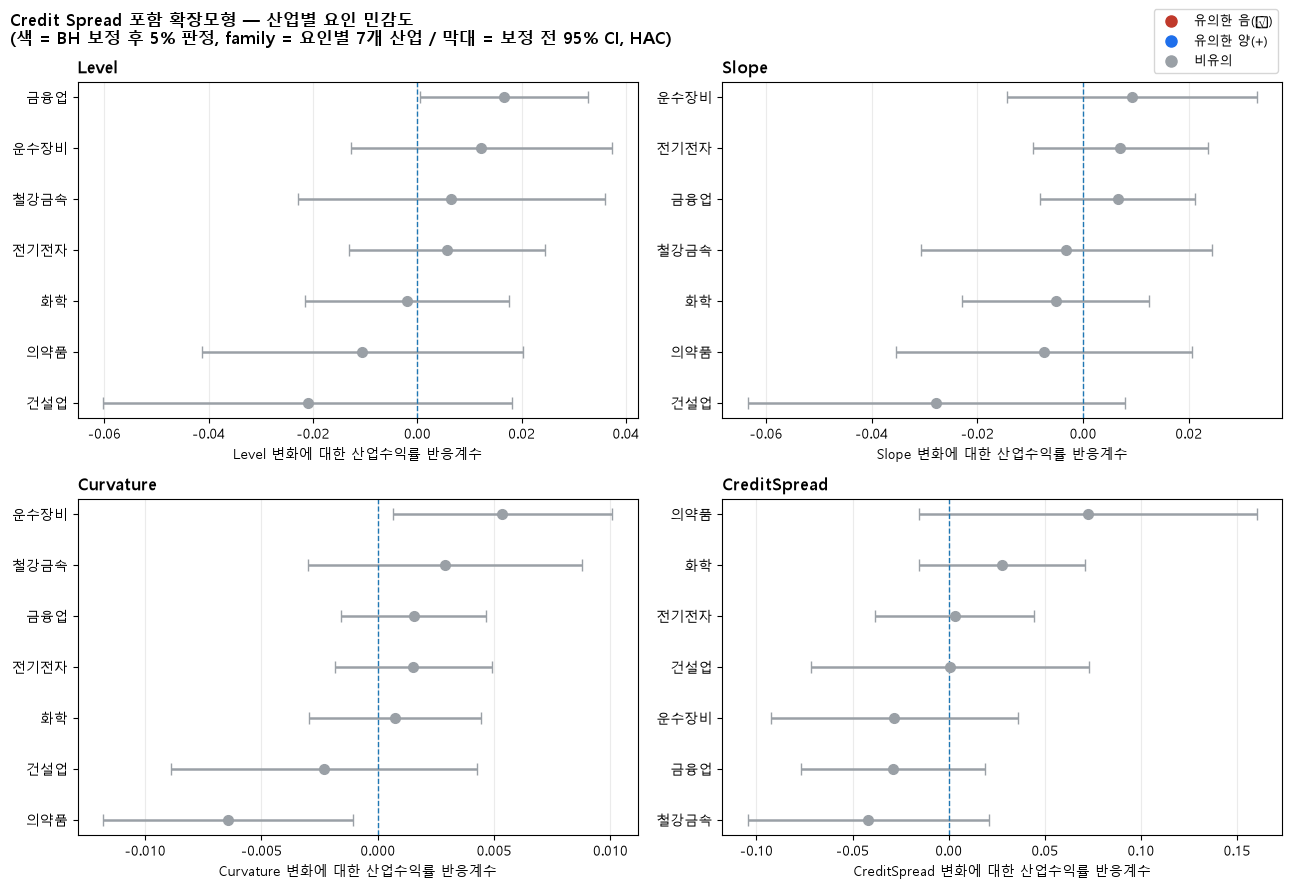

In [26]:
# 확장모형(4요인) 계수와 95% 신뢰구간을 2x2 패널로 그린다.
# 스타일(errorbar, capsize, 0선, 정렬)은 12단계 그림과 동일하게 유지한다.
credit_factor_order = ["Level", "Slope", "Curvature", "CreditSpread"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# BH 보정 컬럼이 붙은 credit_spread_betas 를 쓴다(credit_spread_extended 는 보정 전 원본).
_extended_bh = credit_spread_betas[credit_spread_betas["model"] == "B_Extended_4Factor"]

for ax, factor in zip(axes.ravel(), credit_factor_order):
    plot_data = (
        _extended_bh[_extended_bh["factor"] == factor]
        .sort_values("coefficient")
        .reset_index(drop=True)
    )

    y_pos = np.arange(len(plot_data))

    lower_error = plot_data["coefficient"] - plot_data["ci_lower_95"]
    upper_error = plot_data["ci_upper_95"] - plot_data["coefficient"]

    # 색상은 계수 부호를 나타낸다. 유의 판정은 BH 보정 후 q < 0.05 기준이다.
    # 오차막대는 보정하지 않은 95% 신뢰구간이므로, 구간이 0을 벗어나도 회색일 수 있다.
    point_colors = [
        config.sign_color(coef, sig)
        for coef, sig in zip(plot_data["coefficient"], plot_data["significant_5pct_bh"])
    ]

    for y, coef, lo, hi, color in zip(
        y_pos, plot_data["coefficient"], lower_error, upper_error, point_colors,
    ):
        ax.errorbar(
            coef, y,
            xerr=[[lo], [hi]],
            fmt="o",
            capsize=4,
            linewidth=1.8,
            markersize=7,
            color=color,
            ecolor=color,
        )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_data["industry"])
    ax.set_xlabel(f"{factor} 변화에 대한 산업수익률 반응계수")
    ax.set_title(f"{factor}", loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["ns"], label="비유의"),
]
fig.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=9,
           bbox_to_anchor=(0.99, 0.99))

fig.suptitle(
    "Credit Spread 포함 확장모형 — 산업별 요인 민감도\n"
    "(색 = BH 보정 후 5% 판정, family = 요인별 7개 산업 / 막대 = 보정 전 95% CI, HAC)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()

credit_fig_path = config.H1_FIGDIR / "04_yield_curve_factor_ci.png"
fig.savefig(credit_fig_path, dpi=200, bbox_inches="tight")
plt.show()


## 17단계. 사양 민감도 판정

B-1의 3요인 결과와 확장모형 결과를 요인·산업별로 맞대어,
<b>부호가 유지되고 유의성 판정이 뒤집히지 않는지</b>를 확인한다.
눈으로 비교하면 놓치기 쉬우므로 표로 만든다.

In [27]:
# B-1 3요인 결과와 확장모형 결과를 요인·산업 단위로 비교한다.
# 파일을 다시 읽지 않고 메모리의 yield_curve_factor_betas 를 쓴다(덮어쓰기 방지).
robustness_check = (
    yield_curve_factor_betas[
        ["industry", "factor", "coefficient", "p_value", "significant_5pct"]
    ]
    .rename(columns={
        "coefficient": "coef_base",
        "p_value": "p_base",
        "significant_5pct": "sig_base",
    })
    .merge(
        credit_spread_extended[
            ["industry", "factor", "coefficient", "p_value", "significant_5pct"]
        ].rename(columns={
            "coefficient": "coef_ext",
            "p_value": "p_ext",
            "significant_5pct": "sig_ext",
        }),
        on=["industry", "factor"],
        how="inner",
        validate="one_to_one",
    )
)

robustness_check["sign_kept"] = (
    np.sign(robustness_check["coef_base"]) == np.sign(robustness_check["coef_ext"])
)
robustness_check["sig_kept"] = (
    robustness_check["sig_base"] == robustness_check["sig_ext"]
)

n_pairs = len(robustness_check)

print(f"비교 대상: {n_pairs}개 (산업 x 요인)")
print("부호 유지:", int(robustness_check["sign_kept"].sum()), "/", n_pairs)
print("유의성 판정 유지:", int(robustness_check["sig_kept"].sum()), "/", n_pairs)
print()
print("판정이 달라진 조합:")
display(
    robustness_check[
        ~robustness_check["sign_kept"] | ~robustness_check["sig_kept"]
    ].round(6)
)

비교 대상: 21개 (산업 x 요인)
부호 유지: 20 / 21
유의성 판정 유지: 21 / 21

판정이 달라진 조합:


,industry,factor,coef_base,p_base,sig_base,coef_ext,p_ext,sig_ext,sign_kept,sig_kept
20,화학,Curvature,-0.00008,0.962436,False,0.000758,0.68809,False,False,True


## 18단계. 요약 문서

분석 결과를 문장으로 옮긴 문서는 `results/H1_yield_curve/summary.md`다.

- 금융업 Credit Spread 계수는 결과와 무관하게 <b>사전 예상 없음</b>으로 기술한다.
- BH 보정의 검정족 단위를 문서에 밝힌다.
- VIF는 Credit Spread뿐 아니라 기존 3요인도 함께 보고한다.
- 확증 분석과 사후 분석의 경계를 문서에서 구분한다.

# 최종 완료 확인

## 산출물

- B-1·B-2 산출물은 `results/H1_yield_curve/`(tables·figures)와 `summary.md`에 저장한다.
- 확장 패널: `data/processed/industry_rate_panel_extended.csv`. 경로는 `config.H1_TABDIR`/`config.H1_FIGDIR`로 참조한다.

## 최종 연구질문

> 산업은 금리 전반의 수준, 장단기 기울기, 중기 구간의 곡률 중 어떤 변화에 더 민감하게 반응하는가?

---

## 부록 — 탐색적 분석 (PART D)

아래 PART D는 탐색적 분석이며 B-1/B-2의 확정 결과가 아니다. 기존 산출물은 수정하지 않고 `exploratory_` 접두 파일만 생성한다.

# PART D. 자료 구조 진단과 민감도 점검

> 본분석(PART A~C) 결과를 뒷받침하는 보조 분석이다.
> 산출물은 `exploratory_` 접두를 붙여 본분석 결과와 구분한다.

## 왜 이 분석을 하나

PART B에서 <b>곡률에서만</b> 산업별 차이가 유의하게 나타났다.

| 요인 | BH 유의 산업 | 산업 간 차이 검정 (BH p) |
|---|---|---|
| Level | 0개 | 0.2755 |
| Slope | 0개 | 0.2844 |
| <b>Curvature</b> | <b>2개</b> (의약품·운수장비) | <b>0.0047</b> |

- 이 패턴이 특정 요인 구성의 산물인지 점검한다.
    - Level(7.25)·Slope(7.01)는 서로 상관 −0.843으로 얽혀 있다.
    - Curvature의 VIF는 2.45로 상대적으로 낮지만, 이 값만으로 경제적 효과의 분리나 강건성을 말할 수 없다.
    - 대체 λ와 나비 곡률 결과를 함께 보고해 측정 방식에 대한 민감도를 확인한다.

아래에서 네 가지를 확인한다.

1. <b>주성분분석</b> — 곡선 변동이 실제로 몇 차원인가
2. <b>동시검정</b> — 세 요인을 묶으면 어느 산업이 유의한가
3. <b>2요인·직교화</b> — 요인 구성을 바꾸면 결과가 어떻게 되는가
4. <b>산업 간 차이 검정 · HAC 시차</b> — 결론이 설정에 흔들리는가

## D-0. 수익률곡선은 몇 차원인가 — 주성분분석

### 왜 이것부터 보나

- D-1 이후의 진단은 모두 "요인들이 서로 겹친다"를 전제로 한다.
그런데 <b>왜</b> 겹치는지는 아직 확인하지 않았다.

- 가능성은 둘이다.

    1. 관측치나 만기가 부족해 요인 추정이 불안정하다 → <b>자료 부족 문제</b>
    2. 한국 국고채가 실제로 한 방향으로만 움직인다 → <b>시장의 구조적 특성</b>

- 둘은 대응이 완전히 다르다. 1이면 자료를 더 모아야 하고,
2라면 애초에 나눌 것이 없으므로 <b>분해하지 않는 것이 옳은 선택</b>이 된다.

#### **주성분분석(PCA)으로 구분한다.**
- 네 만기 금리 변화의 공분산행렬을 고유분해해
각 성분이 전체 변동의 몇 %를 설명하는지 본다.

### 무엇을 보면 되나

- <b>PC1 설명비중이 압도적이고 적재값 부호가 모두 같으면</b> → 곡선이 평행이동으로 움직인다
- PC2·PC3 비중이 작으면 → 기울기·곡률 변동이 애초에 희소하다

이 분석은 모형을 추정하는 것이 아니라 <b>자료의 성질을 기술</b>하는 것이므로,
연구자 자유도가 개입하지 않는다. 다만 B-1 결과를 본 뒤 수행했다는 점은 밝혀 둔다.

In [28]:
# 국고채 1·3·5·10년 '변화분'의 주성분분석.
# 수준이 아니라 변화분을 쓰는 이유는 회귀에서 쓰는 변수가 변화분이기 때문이다.
YIELD_CHANGE_COLS = ["d_y1", "d_y3_new", "d_y5", "d_y10_new"]
MATURITY_LABELS = ["1년", "3년", "5년", "10년"]

# 설명변수는 모든 산업이 공유하므로 날짜 단위로 한 번씩만 쓴다.
yield_changes = (
    extended_panel[["date"] + YIELD_CHANGE_COLS]
    .drop_duplicates(subset="date")
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

Z = yield_changes[YIELD_CHANGE_COLS].to_numpy(dtype=float)
Z_centered = Z - Z.mean(axis=0)

# 공분산행렬 고유분해. eigh 는 오름차순이므로 뒤집어 내림차순으로 만든다.
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(Z_centered, rowvar=False))
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

explained = eigenvalues / eigenvalues.sum()

yield_pca = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(eigenvalues))],
    "eigenvalue": eigenvalues,
    "explained_ratio": explained,
    "cumulative_ratio": np.cumsum(explained),
})

# 각 만기가 성분에 얼마나 실리는지(적재값)를 같은 표에 붙인다.
for j, label in enumerate(MATURITY_LABELS):
    yield_pca[f"loading_{label}"] = eigenvectors[j, :]

# 부호는 고유벡터에서 임의로 결정되므로, PC1 이 양(+)이 되도록 통일한다.
for i in range(len(eigenvalues)):
    load = eigenvectors[:, i]
    if load.sum() < 0 if i == 0 else load[0] < 0:
        for j, label in enumerate(MATURITY_LABELS):
            yield_pca.loc[i, f"loading_{label}"] *= -1

yield_pca["n_obs"] = len(yield_changes)

pca_path = config.H1_TABDIR / "exploratory_yield_pca.csv"
yield_pca.to_csv(pca_path, index=False, encoding="utf-8-sig")

print(f"PC1 설명비중: {explained[0]*100:.2f}%   PC1+PC2: {explained[:2].sum()*100:.2f}%")
display(yield_pca.round(5))

PC1 설명비중: 92.09%   PC1+PC2: 96.88%


,component,eigenvalue,explained_ratio,cumulative_ratio,loading_1년,loading_3년,loading_5년,loading_10년,n_obs
0,PC1,0.00492,0.92086,0.92086,0.23634,0.53339,0.58489,0.56352,2451
1,PC2,0.00026,0.04795,0.96881,0.45814,0.53572,0.00965,-0.70923,2451
2,PC3,0.00012,0.02239,0.99120,0.85263,-0.38260,-0.24462,0.25845,2451
3,PC4,0.00005,0.00880,1.00000,0.08525,-0.53115,0.77329,-0.33562,2451


### 요인을 늘리면 설명력이 실제로 늘어나는가

- PCA가 "곡선은 사실상 1차원"이라고 말한다면,
요인을 3개로 늘려도 산업수익률 설명력은 늘지 않아야 한다.

- 같은 산업·같은 기간에서 두 모형의 <b>조정 결정계수(adj R²)</b> 를 비교한다.
조정 결정계수를 쓰는 이유는 설명변수를 늘리면 일반 R²는 반드시 증가하기 때문이다.

    - 모형 1: `KOSPI + d_y3` (설명변수 2개)
    - 모형 2: `KOSPI + Level + Slope + Curvature` (설명변수 4개)

In [29]:
def compare_model_parsimony(data, base_vars, full_vars, control="kospi_return"):
    """단순모형과 확장모형의 조정 결정계수를 산업별로 비교한다."""
    rows = []

    for industry, group in data.groupby("industry"):
        need = ["industry_return", control] + list(base_vars) + list(full_vars)
        d = group[list(dict.fromkeys(need))].dropna()
        y = d["industry_return"]

        m_base = sm.OLS(y, sm.add_constant(d[[control] + list(base_vars)],
                                           has_constant="add")).fit()
        m_full = sm.OLS(y, sm.add_constant(d[[control] + list(full_vars)],
                                           has_constant="add")).fit()

        rows.append({
            "industry": industry,
            "adj_r2_single_rate": m_base.rsquared_adj,
            "adj_r2_three_factor": m_full.rsquared_adj,
            "delta_adj_r2": m_full.rsquared_adj - m_base.rsquared_adj,
            "improved": bool(m_full.rsquared_adj > m_base.rsquared_adj),
            "n_obs": int(m_base.nobs),
        })

    return pd.DataFrame(rows).sort_values("delta_adj_r2", ascending=False).reset_index(drop=True)


model_parsimony = compare_model_parsimony(
    extended_panel,
    base_vars=["d_y3"],
    full_vars=["d_ns_level", "d_ns_slope", "d_ns_curvature"],
)

parsimony_path = config.H1_TABDIR / "exploratory_model_parsimony.csv"
model_parsimony.to_csv(parsimony_path, index=False, encoding="utf-8-sig")

print("설명력이 개선된 산업:", int(model_parsimony["improved"].sum()), "/ 7")
print("평균 조정 R² 증가폭:", round(model_parsimony["delta_adj_r2"].mean(), 6))
display(model_parsimony.round(6))

설명력이 개선된 산업: 2 / 7
평균 조정 R² 증가폭: -2.7e-05


,industry,adj_r2_single_rate,adj_r2_three_factor,delta_adj_r2,improved,n_obs
0,건설업,0.397745,0.398449,0.000704,True,2451
1,금융업,0.622556,0.622855,0.000299,True,2451
2,운수장비,0.471529,0.471458,-0.000071,False,2451
3,전기전자,0.719054,0.718931,-0.000122,False,2451
4,화학,0.643351,0.643162,-0.000189,False,2451
5,의약품,0.242638,0.242288,-0.000349,False,2451
6,철강금속,0.382919,0.382460,-0.000459,False,2451


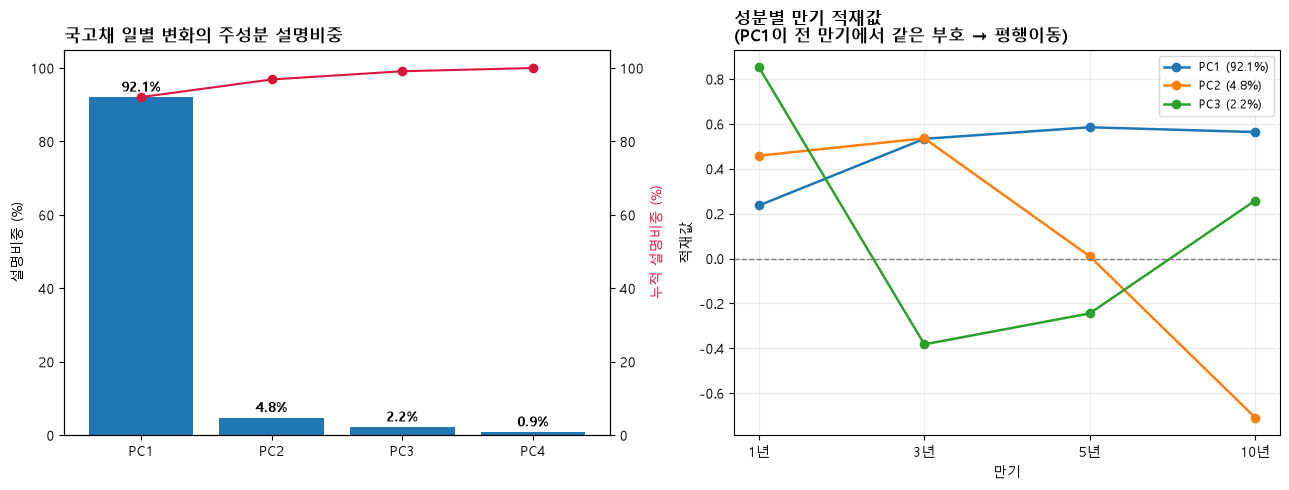

In [30]:
# 왼쪽: 각 주성분의 설명비중과 누적선
# 오른쪽: 성분별 적재값. PC1 이 네 만기에서 같은 부호면 '평행이동'이다.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
x_pos = np.arange(len(yield_pca))
ax.bar(x_pos, yield_pca["explained_ratio"] * 100)
for i, v in enumerate(yield_pca["explained_ratio"] * 100):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")

ax_cum = ax.twinx()
ax_cum.plot(x_pos, yield_pca["cumulative_ratio"] * 100,
            marker="o", linewidth=1.5, color="crimson")
ax_cum.set_ylim(0, 105)
ax_cum.set_ylabel("누적 설명비중 (%)", color="crimson")

ax.set_xticks(x_pos)
ax.set_xticklabels(yield_pca["component"])
ax.set_ylim(0, 105)
ax.set_ylabel("설명비중 (%)")
ax.set_title("국고채 일별 변화의 주성분 설명비중", loc="left", fontweight="bold")

ax = axes[1]
for i in range(3):
    ax.plot(MATURITY_LABELS,
            [yield_pca.loc[i, f"loading_{m}"] for m in MATURITY_LABELS],
            marker="o", linewidth=1.8,
            label=f"PC{i+1} ({yield_pca.loc[i, 'explained_ratio']*100:.1f}%)")

ax.axhline(0, linestyle="--", linewidth=1, color="gray")
ax.set_xlabel("만기")
ax.set_ylabel("적재값")
ax.set_title("성분별 만기 적재값\n(PC1이 전 만기에서 같은 부호 → 평행이동)",
             loc="left", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)

fig.tight_layout()

pca_fig_path = config.H1_FIGDIR / "08_yield_curve_pca.png"
fig.savefig(pca_fig_path, dpi=200, bbox_inches="tight")
plt.show()


In [31]:
# 3년물이 곡선의 지배적 변동(PC1)을 얼마나 잘 대표하는지 확인한다.
# 상관이 높다면 '3년물 하나만 쓴 것'은 임의 선택이 아니라 효율적 선택이 된다.
pc1_score = Z_centered @ eigenvectors[:, 0]

proxy_check = pd.DataFrame({
    "date": yield_changes["date"],
    "pc1": pc1_score,
}).merge(
    extended_panel[["date", "d_y3", "d_ns_level", "d_ns_slope", "d_ns_curvature"]]
    .drop_duplicates(subset="date"),
    on="date",
    how="inner",
)

pc1_corr = (
    proxy_check[["pc1", "d_y3", "d_ns_level", "d_ns_slope", "d_ns_curvature"]]
    .corr()["pc1"]
    .drop("pc1")
    .abs()
    .sort_values(ascending=False)
    .rename("abs_corr_with_pc1")
    .reset_index()
    .rename(columns={"index": "variable"})
)

print("PC1(지배적 곡선변동)과의 절대상관 — 높을수록 좋은 대리변수")
display(pc1_corr.round(4))

PC1(지배적 곡선변동)과의 절대상관 — 높을수록 좋은 대리변수


,variable,abs_corr_with_pc1
0,d_y3,0.9647
1,d_ns_slope,0.7197
2,d_ns_level,0.6036
3,d_ns_curvature,0.6030


### 관찰 결과

- 국고채 1·3·5·10년 변화의 PC1이 변동의 약 <b>92.1%</b>, PC1+PC2가 약 96.9%를 설명한다 — 곡선은 사실상 1차원.
- 요인을 셋으로 늘려도 산업수익률 설명력(조정 R²)은 늘지 않는다.
- 3년물 하나가 곡선의 지배적 변동(PC1)을 잘 대표한다.

### 해석

- 한국 국고채 곡선은 대부분 평행이동으로 움직여 Slope·Curvature가 따로 움직이는 몫이 작다.
- 이는 자료 부족이 아니라 곡선 구조의 성질이며, 곡선 요인 분해의 실익이 제한적임을 뜻한다.

### D-0-1. 1차원성은 전 기간의 구조인가 — 504영업일 Rolling PCA와 정책금리 사이클 진단

#### 분석 질문

전체 표본에서 확인된 높은 PC1 설명비중과 Level·Slope 간 높은 상관·VIF가
2016~2025년 전반에 지속된 구조적 특징인지,
아니면 특정 통화정책 사이클의 강한 공동이동이 전체 결과를 끌어올린 것인지 확인한다.

#### 분석 방법

1. 국고채 1·3·5·10년 일별 변화분에 대해 504영업일 Rolling PCA를 수행한다.
2. 같은 504영업일 창에서 Level–Slope 상관과 VIF를 계산한다.
3. 한국은행 기준금리 방향 전환일을 기준으로 5개 정책 사이클을 사전 정의한다.
4. 각 정책 사이클의 원자료를 이용해 PCA·상관·VIF를 별도로 재계산한다.
5. 각 정책 사이클에서 단일 3년물 모형과 Nelson–Siegel 3요인 모형의 조정 R²를 비교한다.

Rolling 분석은 시간적 변화를 시각화하는 용도로 사용하고,
정책국면 간 비교는 각 국면의 원자료를 이용한 직접 계산값을 주 결과로 사용한다.

In [32]:
# ---------------------------------------------------------------
# D-0-1. Rolling PCA / 정책금리 사이클 진단 공통 설정
# ---------------------------------------------------------------

ROLLING_WINDOW = 504  # 약 2년 영업일

# 정책국면은 분석 결과가 아니라 한국은행 기준금리 방향 전환일을 기준으로 정의한다.
POLICY_CYCLES = pd.DataFrame([
    {
        "cycle": 1,
        "policy_cycle": "저금리·완화 국면",
        "start": "2016-01-04",
        "end": "2017-11-29",
    },
    {
        "cycle": 2,
        "policy_cycle": "인상·정상화 사이클",
        "start": "2017-11-30",
        "end": "2019-07-17",
    },
    {
        "cycle": 3,
        "policy_cycle": "인하·초저금리 사이클",
        "start": "2019-07-18",
        "end": "2021-08-25",
    },
    {
        "cycle": 4,
        "policy_cycle": "인상·고금리 유지 사이클",
        "start": "2021-08-26",
        "end": "2024-10-10",
    },
    {
        "cycle": 5,
        "policy_cycle": "인하 재개 사이클",
        "start": "2024-10-11",
        "end": "2025-12-30",
    },
])

POLICY_CYCLES["start"] = pd.to_datetime(
    POLICY_CYCLES["start"],
    format="%Y-%m-%d",
    errors="raise",
)

POLICY_CYCLES["end"] = pd.to_datetime(
    POLICY_CYCLES["end"],
    format="%Y-%m-%d",
    errors="raise",
)

# 기존 15단계 VIF 계산과 동일한 사양을 유지한다.
# 그래야 전체 표본 VIF 7.25 / 7.01과 직접 비교할 수 있다.
ROLLING_VIF_VARS = VIF_VARS.copy()

# 관심 대상은 수익률곡선 세 요인의 VIF.
CURVE_VIF_TARGETS = [
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
]


def classify_policy_cycle(date):
    """날짜를 사전 정의된 정책금리 사이클에 배정한다."""
    for row in POLICY_CYCLES.itertuples(index=False):
        if row.start <= date <= row.end:
            return row.cycle, row.policy_cycle

    return pd.NA, pd.NA


def compute_pca_diagnostics(data):
    """
    국고채 1·3·5·10년 변화분의 PCA 진단값.

    전체 표본 D-0과 동일하게:
    - 금리 수준이 아니라 변화분 사용
    - 표준화하지 않고 공분산행렬 사용
    """
    z = data[YIELD_CHANGE_COLS].to_numpy(dtype=float)
    z_centered = z - z.mean(axis=0)

    eigenvalues, eigenvectors = np.linalg.eigh(
        np.cov(z_centered, rowvar=False)
    )

    # 내림차순 정렬
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    explained = eigenvalues / eigenvalues.sum()

    # PC1 부호는 임의적이므로 기존 D-0과 동일하게 양(+) 방향으로 통일
    pc1_loading = eigenvectors[:, 0].copy()

    if pc1_loading.sum() < 0:
        pc1_loading *= -1

    return {
        "pc1_share": float(explained[0]),
        "pc1_pc2_share": float(explained[:2].sum()),
        "pc1_loading_1y": float(pc1_loading[0]),
        "pc1_loading_3y": float(pc1_loading[1]),
        "pc1_loading_5y": float(pc1_loading[2]),
        "pc1_loading_10y": float(pc1_loading[3]),
        "pc1_same_sign": bool(
            np.all(pc1_loading > 0)
            or np.all(pc1_loading < 0)
        ),
    }


def compute_vif_diagnostics(data):
    """
    기존 15단계와 같은 설명변수 사양으로 VIF를 계산한다.
    """
    design = sm.add_constant(
        data[ROLLING_VIF_VARS],
        has_constant="add",
    )

    values = {
        var: variance_inflation_factor(
            design.to_numpy(dtype=float),
            i,
        )
        for i, var in enumerate(design.columns)
        if var != "const"
    }

    return {
        "vif_level": float(values["d_ns_level"]),
        "vif_slope": float(values["d_ns_slope"]),
        "vif_curvature": float(values["d_ns_curvature"]),
        "max_curve_vif": float(
            max(values[var] for var in CURVE_VIF_TARGETS)
        ),
    }


# 설명변수는 산업마다 반복되므로 날짜별 한 번만 사용한다.
DIAG_COLS = list(dict.fromkeys(
    ["date"]
    + YIELD_CHANGE_COLS
    + ROLLING_VIF_VARS
))

diagnostic_daily = (
    extended_panel[DIAG_COLS]
    .drop_duplicates(subset="date")
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

print("진단용 일별 관측치:", len(diagnostic_daily))
print("Rolling window:", ROLLING_WINDOW, "영업일")

진단용 일별 관측치: 2451
Rolling window: 504 영업일


In [33]:
# ---------------------------------------------------------------
# 504영업일 Rolling PCA / L-S 상관 / VIF
# ---------------------------------------------------------------

rolling_rows = []

for end_idx in range(
    ROLLING_WINDOW,
    len(diagnostic_daily) + 1,
):
    window = diagnostic_daily.iloc[
        end_idx - ROLLING_WINDOW:end_idx
    ].copy()

    pca_stats = compute_pca_diagnostics(window)
    vif_stats = compute_vif_diagnostics(window)

    # 정책국면별 rolling 평균을 만들 때는 종료일보다
    # window 중앙일을 기준으로 국면을 부여한다.
    mid_date = window["date"].iloc[len(window) // 2]

    cycle_no, cycle_name = classify_policy_cycle(mid_date)

    rolling_rows.append({
        "window_start": window["date"].iloc[0],
        "window_mid": mid_date,
        "window_end": window["date"].iloc[-1],

        "cycle_mid": cycle_no,
        "policy_cycle_mid": cycle_name,

        "n_obs": len(window),

        # Level-Slope 상관
        "ls_corr": float(
            window["d_ns_level"].corr(
                window["d_ns_slope"]
            )
        ),

        **pca_stats,
        **vif_stats,
    })


rolling_curve_structure = pd.DataFrame(rolling_rows)


# config 규정: 결과 폴더를 직접 만들지 않고 H1_TABDIR 사용
rolling_path = (
    config.H1_TABDIR
    / "rolling_curve_structure.csv"
)

rolling_curve_structure.to_csv(
    rolling_path,
    index=False,
    encoding="utf-8-sig",
)

print("Rolling window 수:", len(rolling_curve_structure))
rolling_preview = rolling_curve_structure.head().copy()
rolling_numeric_cols = rolling_preview.select_dtypes(include="number").columns
rolling_preview[rolling_numeric_cols] = rolling_preview[rolling_numeric_cols].round(4)
display(rolling_preview)

Rolling window 수: 1948


,window_start,window_mid,window_end,cycle_mid,policy_cycle_mid,n_obs,ls_corr,pc1_share,pc1_pc2_share,pc1_loading_1y,pc1_loading_3y,pc1_loading_5y,pc1_loading_10y,pc1_same_sign,vif_level,vif_slope,vif_curvature,max_curve_vif
0,2016-01-05,2017-01-11,2018-01-23,1,저금리·완화 국면,504,-0.9327,0.9140,0.9738,0.2466,0.4569,0.5744,0.6328,True,13.5355,11.6337,2.7047,13.5355
1,2016-01-06,2017-01-12,2018-01-24,1,저금리·완화 국면,504,-0.9328,0.9140,0.9738,0.2468,0.4569,0.5744,0.6328,True,13.5693,11.6615,2.7044,13.5693
2,2016-01-07,2017-01-13,2018-01-25,1,저금리·완화 국면,504,-0.9325,0.9141,0.9738,0.2467,0.4571,0.5746,0.6325,True,13.5202,11.6236,2.7032,13.5202
3,2016-01-08,2017-01-16,2018-01-26,1,저금리·완화 국면,504,-0.9325,0.9142,0.9738,0.2466,0.4572,0.5746,0.6324,True,13.4959,11.6106,2.6980,13.4959
4,2016-01-11,2017-01-17,2018-01-29,1,저금리·완화 국면,504,-0.9325,0.9148,0.9740,0.2472,0.4581,0.5749,0.6313,True,13.4578,11.6057,2.6924,13.4578


In [34]:
# ---------------------------------------------------------------
# Rolling 결과의 정책국면별 평균 — 보조 진단
# ---------------------------------------------------------------

rolling_policy_summary = (
    rolling_curve_structure
    .dropna(subset=["cycle_mid"])
    .groupby(
        ["cycle_mid", "policy_cycle_mid"],
        as_index=False,
    )
    .agg(
        n_windows=("pc1_share", "size"),

        mean_pc1_share=("pc1_share", "mean"),
        mean_pc1_pc2_share=("pc1_pc2_share", "mean"),

        mean_ls_corr=("ls_corr", "mean"),

        mean_max_curve_vif=(
            "max_curve_vif",
            "mean",
        ),
    )
)


rolling_policy_summary_path = (
    config.H1_TABDIR
    / "rolling_policy_cycle_summary.csv"
)

rolling_policy_summary.to_csv(
    rolling_policy_summary_path,
    index=False,
    encoding="utf-8-sig",
)

display(rolling_policy_summary.round(4))

,cycle_mid,policy_cycle_mid,n_windows,mean_pc1_share,mean_pc1_pc2_share,mean_ls_corr,mean_max_curve_vif
0,1,저금리·완화 국면,216,0.9110,0.9732,-0.9300,15.1769
1,2,인상·정상화 사이클,398,0.9227,0.9742,-0.9101,11.0101
2,3,인하·초저금리 사이클,522,0.9018,0.9655,-0.8858,12.5796
3,4,인상·고금리 유지 사이클,765,0.9335,0.9722,-0.8066,7.8734
4,5,인하 재개 사이클,47,0.9392,0.9774,-0.8987,12.6844


In [35]:
# ---------------------------------------------------------------
# 정책금리 사이클별 직접 진단
# ---------------------------------------------------------------

policy_curve_rows = []
policy_model_rows = []


for row in POLICY_CYCLES.itertuples(index=False):

    # --------------------------------
    # 1. 금리곡선 구조 진단
    # --------------------------------
    daily_sub = diagnostic_daily.loc[
        diagnostic_daily["date"].between(
            row.start,
            row.end,
        )
    ].copy()

    if len(daily_sub) < 10:
        continue

    pca_stats = compute_pca_diagnostics(daily_sub)
    vif_stats = compute_vif_diagnostics(daily_sub)

    policy_curve_rows.append({
        "cycle": row.cycle,
        "policy_cycle": row.policy_cycle,
        "start": row.start,
        "end": row.end,
        "n_dates": len(daily_sub),

        "ls_corr": float(
            daily_sub["d_ns_level"].corr(
                daily_sub["d_ns_slope"]
            )
        ),

        **pca_stats,
        **vif_stats,
    })


    # --------------------------------
    # 2. 산업수익률 설명력 비교
    # --------------------------------
    panel_sub = extended_panel.loc[
        extended_panel["date"].between(
            row.start,
            row.end,
        )
    ].copy()

    # 기존 D-0에서 만든 함수를 그대로 재사용
    parsimony_sub = compare_model_parsimony(
        panel_sub,
        base_vars=["d_y3"],
        full_vars=[
            "d_ns_level",
            "d_ns_slope",
            "d_ns_curvature",
        ],
    )

    policy_model_rows.append({
        "cycle": row.cycle,
        "policy_cycle": row.policy_cycle,

        "n_industries": int(
            parsimony_sub["industry"].nunique()
        ),

        "mean_adj_r2_single_rate": float(
            parsimony_sub[
                "adj_r2_single_rate"
            ].mean()
        ),

        "mean_adj_r2_three_factor": float(
            parsimony_sub[
                "adj_r2_three_factor"
            ].mean()
        ),

        "mean_delta_adj_r2": float(
            parsimony_sub[
                "delta_adj_r2"
            ].mean()
        ),

        "improved_industries": int(
            parsimony_sub["improved"].sum()
        ),
    })


policy_curve_structure = pd.DataFrame(
    policy_curve_rows
)

policy_model_parsimony = pd.DataFrame(
    policy_model_rows
)


# 두 결과를 하나의 정책국면 표로 결합
policy_cycle_diagnostics = (
    policy_curve_structure
    .merge(
        policy_model_parsimony,
        on=["cycle", "policy_cycle"],
        how="left",
        validate="one_to_one",
    )
    .sort_values("cycle")
    .reset_index(drop=True)
)


policy_cycle_path = (
    config.H1_TABDIR
    / "policy_cycle_curve_structure.csv"
)

policy_cycle_diagnostics.to_csv(
    policy_cycle_path,
    index=False,
    encoding="utf-8-sig",
)


display_cols = [
    "cycle",
    "policy_cycle",
    "n_dates",

    "pc1_share",
    "pc1_pc2_share",

    "ls_corr",

    "vif_level",
    "vif_slope",
    "max_curve_vif",

    "mean_adj_r2_single_rate",
    "mean_adj_r2_three_factor",
    "mean_delta_adj_r2",

    "improved_industries",
]

display(
    policy_cycle_diagnostics[
        display_cols
    ].round(4)
)

,cycle,policy_cycle,n_dates,pc1_share,pc1_pc2_share,ls_corr,vif_level,vif_slope,max_curve_vif,mean_adj_r2_single_rate,mean_adj_r2_three_factor,mean_delta_adj_r2,improved_industries
0,1,저금리·완화 국면,468,0.9201,0.9751,-0.9336,13.5744,11.7597,13.5744,0.3278,0.3284,0.0006,3
1,2,인상·정상화 사이클,398,0.9187,0.9739,-0.9192,11.8108,10.7106,11.8108,0.4098,0.4094,-0.0003,3
2,3,인하·초저금리 사이클,522,0.8939,0.9647,-0.9088,13.9964,11.1960,13.9964,0.6336,0.6333,-0.0002,2
3,4,인상·고금리 유지 사이클,765,0.9316,0.9708,-0.7833,5.0977,5.5515,5.5515,0.5208,0.5203,-0.0005,1
4,5,인하 재개 사이클,298,0.9107,0.9696,-0.8995,15.2033,12.9959,15.2033,0.4546,0.4529,-0.0017,2


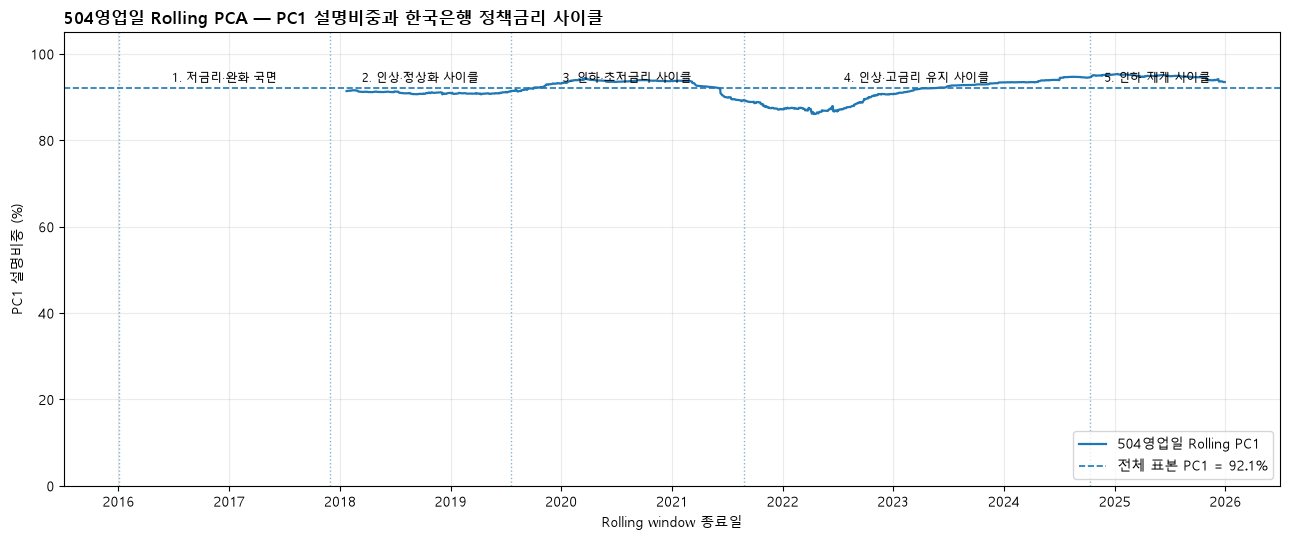

In [36]:
# ---------------------------------------------------------------
# 504영업일 Rolling PC1 시계열
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 5.5))


ax.plot(
    rolling_curve_structure["window_end"],
    rolling_curve_structure["pc1_share"] * 100,
    linewidth=1.6,
    label=f"{ROLLING_WINDOW}영업일 Rolling PC1",
)


# 전체 표본의 PC1 = 기존 D-0 결과
full_sample_pc1 = float(
    yield_pca.loc[0, "explained_ratio"] * 100
)

ax.axhline(
    full_sample_pc1,
    linestyle="--",
    linewidth=1.2,
    label=(
        f"전체 표본 PC1 = "
        f"{full_sample_pc1:.1f}%"
    ),
)


# 정책금리 사이클 시작점 표시
for row in POLICY_CYCLES.itertuples(index=False):
    ax.axvline(
        row.start,
        linestyle=":",
        linewidth=1,
        alpha=0.55,
    )


# 정책국면 명칭 표시
y_top = ax.get_ylim()[1]

for row in POLICY_CYCLES.itertuples(index=False):

    mid = (
        row.start
        + (row.end - row.start) / 2
    )

    ax.text(
        mid,
        y_top,
        f"{row.cycle}. {row.policy_cycle}",
        ha="center",
        va="top",
        fontsize=8.5,
    )


ax.set_title(
    "504영업일 Rolling PCA — "
    "PC1 설명비중과 한국은행 정책금리 사이클",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Rolling window 종료일")
ax.set_ylabel("PC1 설명비중 (%)")

ax.set_ylim(0, 105)

ax.grid(alpha=0.25)
ax.legend(loc="lower right")

fig.tight_layout()


# config 경로 규정 준수
rolling_pc1_fig_path = (
    config.H1_FIGDIR
    / "rolling_pc1_policy_cycles.png"
)
fig.savefig(
    rolling_pc1_fig_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### 관찰 결과

- 504영업일 Rolling PC1 설명비중은 전체 기간에서 86.08%~95.38% 범위였다.
- PC1 비중이 가장 높았던 정책국면은 인하 재개 사이클(2024-10~2025-12)이며, 평균/국면 PC1 설명비중은 93.92%였다.
- Level–Slope 상관의 절댓값과 최대 VIF는 저금리·완화 국면(2016-01~2017-11)에서 가장 높았다(|평균 ls_corr|=0.930, 평균 최대 VIF=15.18).
- 3요인 모형의 단일 3년물 대비 평균 조정 R² 증가폭은 저금리·완화 국면에서 가장 컸으며(+0.00064, 약 0.06%p), 3개 산업에서 설명력이 개선되었다.

## 해석

- 5개 정책국면 전체에서 Rolling PC1 설명비중이 국면 평균 기준 90.2%~93.9% 범위를 유지하고, Level–Slope 상관의 절댓값도 모든 국면에서 0.81 이상으로 항상 크므로, 전체 표본에서 확인된 높은 공동이동과 공선성은 특정 통화정책 사이클에 집중된 현상이라기보다 2016~2025년 표본기간 전반에 반복된 국고채 수익률곡선의 구조적 특징으로 해석한다.
- 다만 공선성의 정도(최대 VIF)는 국면 간 편차가 있다. 인상·고금리 유지 사이클(2021-08~2024-10)은 다른 국면(평균 최대 VIF 11~15)보다 뚜렷이 낮은 평균 최대 VIF(7.87)를 보인다. 그런데 이 상대적으로 공선성이 낮은 국면에서도 3요인 모형의 평균 조정 R² 증가폭은 오히려 음수(−0.00048)이고, 설명력이 개선된 산업 수도 5개 국면 중 가장 적은 1개에 그친다.
- 즉 공선성이 상대적으로 완화된 국면에서도 3요인 모형의 설명력 개선이 나타나지 않았으므로, Level·Slope 계수의 비유의성은 다중공선성만으로 설명되지 않으며, 산업수익률이 두 요인에 독립적으로 노출되는 정도 자체가 애초에 제한적일 가능성을 시사한다. 이는 인과관계가 아니라 관측된 패턴에 대한 잠정적 해석이다.

## D-1. Joint Significance Test (F-test)

### 무엇을 검정하나

$$
H_0:\ \beta_{Level}=\beta_{Slope}=\beta_{Curvature}=0
$$

- "수익률곡선이 이 산업 수익률과 <b>아무 관계도 없다</b>"가 귀무가설이다.

- 개별 t검정은 "다른 두 요인을 통제한 뒤 이 요인 <b>하나만</b>의 고유 기여"를 묻는다.
- 요인들이 겹쳐 있으면 고유 기여는 작아져 개별 t는 죽지만,
<b>셋이 함께 설명하는 몫</b>은 그대로 남는다.

따라서 다음 조합이 나오면 다중공선성의 전형적 증상이다.

> 동시검정 유의 + 개별검정 전부 비유의

표준오차는 HAC(maxlags=5)를 유지하므로 F검정도 HAC 기반 Wald 검정이 된다.
7개 산업 다중검정이므로 PART C에서 만든 `add_bh_correction()`을 그대로 쓴다.

In [37]:
def run_joint_significance_test(data, hac_lags=5,
                                test_vars=("d_ns_level", "d_ns_slope", "d_ns_curvature"),
                                control_cols=("kospi_return",)):
    """산업별로 H0: 지정한 요인 계수가 모두 0 인지 동시검정(F-test)한다."""
    test_vars = list(test_vars)
    x_cols = list(control_cols) + test_vars

    rows = []

    for industry, group in data.groupby("industry"):
        reg_data = group[["industry_return"] + x_cols].dropna()

        X = sm.add_constant(reg_data[x_cols], has_constant="add")
        y = reg_data["industry_return"]

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": hac_lags},
        )

        # "d_ns_level = 0, d_ns_slope = 0, ..." 형태의 제약식을 만든다.
        hypothesis = ", ".join(f"{v} = 0" for v in test_vars)
        f_test = model.f_test(hypothesis)

        individual_p = model.pvalues[test_vars]

        rows.append({
            "industry": industry,
            "model": "Exploratory_Joint_3Factor",
            "joint_f_stat": float(f_test.fvalue),
            "joint_p_value": float(f_test.pvalue),
            "df_num": int(len(test_vars)),
            "df_denom": int(model.df_resid),
            "min_individual_p": float(individual_p.min()),
            "n_individual_sig_5pct": int((individual_p < 0.05).sum()),
            "joint_sig_5pct": bool(f_test.pvalue < 0.05),
            "r_squared": model.rsquared,
            "adj_r_squared": model.rsquared_adj,
            "n_obs": int(model.nobs),
            "hac_lags": hac_lags,
        })

    return pd.DataFrame(rows)


joint_ftest = (
    run_joint_significance_test(extended_panel, hac_lags=HAC_LAGS)
    .pipe(add_bh_correction, group_cols=("model",), p_col="joint_p_value")
    .rename(columns={"p_value_bh": "joint_p_value_bh"})
    .sort_values("joint_p_value")
    .reset_index(drop=True)
)

joint_path = config.H1_TABDIR / "exploratory_joint_ftest.csv"
joint_ftest.to_csv(joint_path, index=False, encoding="utf-8-sig")

print("동시검정 유의 산업:", int(joint_ftest["joint_sig_5pct"].sum()), "/ 7")
print("개별검정 유의 조합:", int(joint_ftest["n_individual_sig_5pct"].sum()), "/ 21")
display(joint_ftest.round(5))

동시검정 유의 산업: 3 / 7
개별검정 유의 조합: 3 / 21


,industry,model,joint_f_stat,joint_p_value,df_num,df_denom,min_individual_p,n_individual_sig_5pct,joint_sig_5pct,r_squared,adj_r_squared,n_obs,hac_lags,joint_p_value_bh,bh_n_tests,bh_family,significant_5pct_bh
0,의약품,Exploratory_Joint_3Factor,4.73722,0.00268,3,2446,0.00236,1,True,0.24353,0.24229,2451,5,0.01875,7,Exploratory_Joint_3Factor,True
1,운수장비,Exploratory_Joint_3Factor,3.59193,0.01313,3,2446,0.00721,1,True,0.47232,0.47146,2451,5,0.04596,7,Exploratory_Joint_3Factor,True
2,금융업,Exploratory_Joint_3Factor,2.97331,0.03057,3,2446,0.02938,1,True,0.62347,0.62286,2451,5,0.07134,7,Exploratory_Joint_3Factor,False
3,철강금속,Exploratory_Joint_3Factor,2.03121,0.10744,3,2446,0.14948,0,False,0.38347,0.38246,2451,5,0.18802,7,Exploratory_Joint_3Factor,False
4,건설업,Exploratory_Joint_3Factor,1.25128,0.28955,3,2446,0.12431,0,False,0.39943,0.39845,2451,5,0.40537,7,Exploratory_Joint_3Factor,False
5,전기전자,Exploratory_Joint_3Factor,0.38846,0.76133,3,2446,0.36228,0,False,0.71939,0.71893,2451,5,0.79026,7,Exploratory_Joint_3Factor,False
6,화학,Exploratory_Joint_3Factor,0.34849,0.79026,3,2446,0.51630,0,False,0.64374,0.64316,2451,5,0.79026,7,Exploratory_Joint_3Factor,False


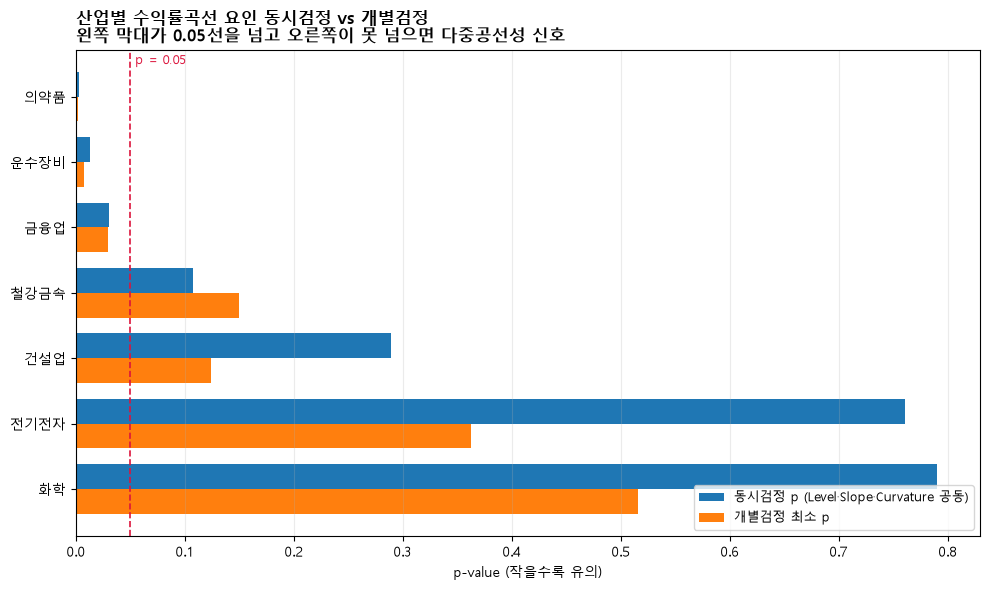

In [38]:
# 동시검정 p값과 개별검정 최소 p값을 나란히 놓아
# "함께는 유의한데 따로는 아니다"가 눈에 보이게 한다.
plot_data = joint_ftest.sort_values("joint_p_value", ascending=False).reset_index(drop=True)

y_pos = np.arange(len(plot_data))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(y_pos + bar_height / 2, plot_data["joint_p_value"],
        height=bar_height, label="동시검정 p (Level·Slope·Curvature 공동)")
ax.barh(y_pos - bar_height / 2, plot_data["min_individual_p"],
        height=bar_height, label="개별검정 최소 p")

ax.axvline(0.05, linestyle="--", linewidth=1.2, color="crimson")
ax.text(0.05, len(plot_data) - 0.35, " p = 0.05", color="crimson", fontsize=9, va="top")

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["industry"])
ax.set_xlabel("p-value (작을수록 유의)")
ax.set_title(
    "산업별 수익률곡선 요인 동시검정 vs 개별검정\n"
    "왼쪽 막대가 0.05선을 넘고 오른쪽이 못 넘으면 다중공선성 신호",
    loc="left",
    fontweight="bold",
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

joint_fig_path = config.H1_FIGDIR / "05_joint_ftest.png"
fig.savefig(joint_fig_path, dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 세 요인 동시검정에서 의약품·운수장비만 유의하고 나머지는 추가 설명력이 확인되지 않는다.
- 동시검정과 개별검정 결과가 일치해, 다중공선성이 개별 효과를 가렸다는 증거는 없다.

## D-2. 2요인 모형 (Level + Slope)

### 왜 Curvature를 빼나

- 본분석에서 유의한 결과는 전부 Curvature에서 나왔다.
- 그렇다면 <b>Curvature를 빼면 Level·Slope가 그 자리를 대신하는지</b>를 확인해야 한다.

- Level–Slope 상관이 <b>−0.843</b>으로 강하므로, 셋 중 하나를 빼면
남은 둘의 VIF는 크게 떨어진다(설명변수가 2개일 때 VIF는 $1/(1-r^2)$).

### 무엇을 확인하나

- Curvature를 제거해 겹침을 줄였을 때 <b>Level·Slope가 유의해지는가.</b>
- 유의해지지 않는다면, 곡률에서 나온 결과는 단순히 "요인을 줄여서 생긴 것"이 아니라는 뜻이다.

9단계의 `run_yield_curve_factor_model()`을 `x_cols`만 바꿔 그대로 재사용한다.

In [39]:
# Level + Slope 2요인 모형. 함수는 9단계 것을 그대로 쓴다.
TWO_FACTOR_X_COLS = ["kospi_return", "d_ns_level", "d_ns_slope"]
TWO_FACTOR_LABELS = {"d_ns_level": "Level", "d_ns_slope": "Slope"}

two_factor_betas = (
    run_yield_curve_factor_model(
        extended_panel,
        hac_lags=HAC_LAGS,
        x_cols=TWO_FACTOR_X_COLS,
        factor_labels=TWO_FACTOR_LABELS,
    )
    .assign(model="Exploratory_TwoFactor")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

# 2요인 모형의 VIF 를 다시 계산한다(설명변수가 줄면 VIF 도 줄어야 한다).
two_factor_daily = (
    extended_panel[["date"] + TWO_FACTOR_X_COLS]
    .drop_duplicates(subset="date")
    .dropna()
)
two_factor_design = sm.add_constant(two_factor_daily[TWO_FACTOR_X_COLS], has_constant="add")

two_factor_vif = {
    var: variance_inflation_factor(two_factor_design.to_numpy(dtype=float), i)
    for i, var in enumerate(two_factor_design.columns)
    if var != "const"
}

two_factor_betas["vif"] = two_factor_betas["variable"].map(two_factor_vif)

two_factor_path = config.H1_TABDIR / "exploratory_two_factor_betas.csv"
two_factor_betas.to_csv(two_factor_path, index=False, encoding="utf-8-sig")

print("2요인 VIF:", {k: round(v, 3) for k, v in two_factor_vif.items()})
print("3요인 대비 유의 조합:",
      int(two_factor_betas["significant_5pct"].sum()), "/", len(two_factor_betas))
display(two_factor_betas.round(5))

2요인 VIF: {'kospi_return': np.float64(1.0), 'd_ns_level': np.float64(3.455), 'd_ns_slope': np.float64(3.454)}
3요인 대비 유의 조합: 1 / 14


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,...,adj_r_squared,n_obs,hac_lags,optimal_lambda,model,p_value_bh,bh_n_tests,bh_family,significant_5pct_bh,vif
0,건설업,Level,d_ns_level,-0.01153,0.01257,-0.91767,0.35879,-0.03616,0.01310,False,...,0.39852,2451,5,0.5,Exploratory_TwoFactor,0.54582,7,Exploratory_TwoFactor | Level,False,3.45470
1,건설업,Slope,d_ns_slope,-0.01900,0.01190,-1.59641,0.11040,-0.04233,0.00433,False,...,0.39852,2451,5,0.5,Exploratory_TwoFactor,0.19319,7,Exploratory_TwoFactor | Slope,False,3.45399
2,금융업,Level,d_ns_level,0.00817,0.00637,1.28217,0.19978,-0.00432,0.02065,False,...,0.62265,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
3,금융업,Slope,d_ns_slope,-0.00190,0.00532,-0.35701,0.72109,-0.01232,0.00853,False,...,0.62265,2451,5,0.5,Exploratory_TwoFactor,0.78542,7,Exploratory_TwoFactor | Slope,False,3.45399
4,운수장비,Level,d_ns_level,-0.01166,0.00901,-1.29442,0.19552,-0.02932,0.00600,False,...,0.47014,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
5,운수장비,Slope,d_ns_slope,-0.01346,0.00812,-1.65867,0.09718,-0.02937,0.00245,False,...,0.47014,2451,5,0.5,Exploratory_TwoFactor,0.19319,7,Exploratory_TwoFactor | Slope,False,3.45399
6,의약품,Level,d_ns_level,0.02115,0.01156,1.83028,0.06721,-0.00150,0.04380,False,...,0.24022,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
7,의약품,Slope,d_ns_slope,0.02338,0.00983,2.37760,0.01743,0.00411,0.04265,True,...,0.24022,2451,5,0.5,Exploratory_TwoFactor,0.12198,7,Exploratory_TwoFactor | Slope,False,3.45399
8,전기전자,Level,d_ns_level,-0.00037,0.00638,-0.05864,0.95324,-0.01288,0.01213,False,...,0.71896,2451,5,0.5,Exploratory_TwoFactor,0.95324,7,Exploratory_TwoFactor | Level,False,3.45470
9,전기전자,Slope,d_ns_slope,0.00153,0.00561,0.27226,0.78542,-0.00947,0.01252,False,...,0.71896,2451,5,0.5,Exploratory_TwoFactor,0.78542,7,Exploratory_TwoFactor | Slope,False,3.45399


### 관찰 결과

- Level+Slope 2요인으로 줄여도 산업 간 차이 신호는 살아나지 않는다.
- Curvature를 뺀 구성에서는 산업 간 차이가 유의하지 않다. 이는 λ=0.5의 3요인 사양에서 관찰된 패턴을 기술할 뿐, 곡률이 차이의 원인임을 식별하지 않는다.

## D-3. 직교화 (Gram–Schmidt Orthogonalization)

### 방법

요인을 순서대로 쌓으면서 앞 요인과 겹치는 부분을 잔차로 제거한다.

1. `o_level` = Level (그대로)
2. `o_slope` = Slope를 `o_level`에 회귀한 <b>잔차</b>
3. `o_curvature` = Curvature를 `o_level`·`o_slope`에 회귀한 <b>잔차</b>

이렇게 만든 세 변수는 서로 상관이 0이므로 VIF가 1이 된다.

### 먼저 알아야 할 한계 — 이건 해결책이 아니다

1. 직교화는 겹치는 정보를 <b>없애는 것이 아니라 앞 요인에 몰아주는 것</b>이다.
따라서 결과는 <b>순서에 전적으로 의존</b>한다. Slope를 먼저 놓으면 답이 달라진다.

2. FWL(Frisch–Waugh–Lovell) 정리에 의해
<b>마지막에 직교화한 Curvature의 계수와 표준오차는 원래 3요인 모형과 정확히 같다.</b>
아래 결과에서 이 점을 검증한다. 즉 직교화로 "유의성이 생겨난다면"
그건 새로운 정보가 아니라 공유된 변동을 앞 요인에 배정한 결과일 뿐이다.

그래서 이 분석은 <b>어느 요인이 공유 변동의 대부분을 설명하는지 진단하는 용도</b>이지,
논문 본문 결과로 쓸 수 있는 추정치가 아니다.

In [40]:
def orthogonalize_factors(daily, factor_cols):
    """Gram-Schmidt 직교화. 앞 요인과 겹치는 부분을 잔차로 떼어낸다."""
    out = daily.copy()
    built = []

    for col in factor_cols:
        target = f"o_{col}"
        if not built:
            out[target] = out[col]                      # 첫 요인은 그대로
        else:
            X = sm.add_constant(out[built], has_constant="add")
            out[target] = sm.OLS(out[col], X).fit().resid   # 앞 요인 성분 제거
        built.append(target)

    return out, built


BASE_FACTORS = ["d_ns_level", "d_ns_slope", "d_ns_curvature"]

# 설명변수는 모든 산업이 공유하므로 날짜 단위에서 한 번만 직교화한다.
orth_daily, ORTH_COLS = orthogonalize_factors(
    extended_panel[["date"] + BASE_FACTORS].drop_duplicates(subset="date").dropna(),
    BASE_FACTORS,
)

# 직교화 확인: 상관 0, VIF 1
print("직교화 후 상관행렬:")
display(orth_daily[ORTH_COLS].corr().round(6))

# 기존 패널은 건드리지 않고 사본에만 직교 변수를 붙인다.
exploratory_panel = extended_panel.merge(
    orth_daily[["date"] + ORTH_COLS],
    on="date",
    how="left",
    validate="many_to_one",
)

ORTH_X_COLS = ["kospi_return"] + ORTH_COLS
ORTH_LABELS = {
    "o_d_ns_level": "Level_orth",
    "o_d_ns_slope": "Slope_orth",
    "o_d_ns_curvature": "Curvature_orth",
}

orthogonalized_betas = (
    run_yield_curve_factor_model(
        exploratory_panel,
        hac_lags=HAC_LAGS,
        x_cols=ORTH_X_COLS,
        factor_labels=ORTH_LABELS,
    )
    .assign(model="Exploratory_Orthogonalized")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

orth_path = config.H1_TABDIR / "exploratory_orthogonalized_betas.csv"
orthogonalized_betas.to_csv(orth_path, index=False, encoding="utf-8-sig")

display(orthogonalized_betas.round(5))

직교화 후 상관행렬:


,o_d_ns_level,o_d_ns_slope,o_d_ns_curvature
o_d_ns_level,1.0,-0.0,-0.0
o_d_ns_slope,-0.0,1.0,-0.0
o_d_ns_curvature,-0.0,-0.0,1.0


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,...,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda,model,p_value_bh,bh_n_tests,bh_family,significant_5pct_bh
0,건설업,Level_orth,o_d_ns_level,0.00533,0.00637,0.83580,0.40327,-0.00717,0.01782,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.91886,7,Exploratory_Orthogonalized | Level_orth,False
1,건설업,Slope_orth,o_d_ns_slope,-0.01900,0.01198,-1.58630,0.11267,-0.04247,0.00447,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.19717,7,Exploratory_Orthogonalized | Slope_orth,False
2,건설업,Curvature_orth,o_d_ns_curvature,-0.00234,0.00306,-0.76450,0.44457,-0.00833,0.00366,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.51866,7,Exploratory_Orthogonalized | Curvature_orth,False
3,금융업,Level_orth,o_d_ns_level,0.00984,0.00436,2.25534,0.02411,0.00129,0.01840,True,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.16878,7,Exploratory_Orthogonalized | Level_orth,False
4,금융업,Slope_orth,o_d_ns_slope,-0.00190,0.00533,-0.35725,0.72091,-0.01236,0.00855,False,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.78731,7,Exploratory_Orthogonalized | Slope_orth,False
5,금융업,Curvature_orth,o_d_ns_curvature,0.00241,0.00137,1.76201,0.07807,-0.00027,0.00510,False,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.18216,7,Exploratory_Orthogonalized | Curvature_orth,False
6,운수장비,Level_orth,o_d_ns_level,0.00026,0.00557,0.04651,0.96290,-0.01066,0.01118,False,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.96290,7,Exploratory_Orthogonalized | Level_orth,False
7,운수장비,Slope_orth,o_d_ns_slope,-0.01348,0.00789,-1.70782,0.08767,-0.02895,0.00199,False,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.19717,7,Exploratory_Orthogonalized | Slope_orth,False
8,운수장비,Curvature_orth,o_d_ns_curvature,0.00621,0.00231,2.68719,0.00721,0.00168,0.01074,True,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.02522,7,Exploratory_Orthogonalized | Curvature_orth,True
9,의약품,Level_orth,o_d_ns_level,0.00044,0.00826,0.05345,0.95737,-0.01574,0.01662,False,...,0.24353,0.24229,2451,5,0.5,Exploratory_Orthogonalized,0.96290,7,Exploratory_Orthogonalized | Level_orth,False


In [41]:
# FWL 검증 — 마지막에 직교화한 Curvature 는 원래 3요인 모형과 같아야 한다.
# 같지 않다면 직교화 구현이 틀린 것이므로 반드시 확인한다.
fwl_check = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient", "std_error_hac", "p_value"]]
    .rename(columns={
        "coefficient": "coef_3factor",
        "std_error_hac": "se_3factor",
        "p_value": "p_3factor",
    })
    .merge(
        orthogonalized_betas[orthogonalized_betas["factor"] == "Curvature_orth"]
        [["industry", "coefficient", "std_error_hac", "p_value"]]
        .rename(columns={
            "coefficient": "coef_orth",
            "std_error_hac": "se_orth",
            "p_value": "p_orth",
        }),
        on="industry",
        validate="one_to_one",
    )
)

fwl_check["max_abs_diff"] = np.maximum(
    (fwl_check["coef_3factor"] - fwl_check["coef_orth"]).abs(),
    (fwl_check["se_3factor"] - fwl_check["se_orth"]).abs(),
)

print("FWL 검증 — Curvature 계수·SE 최대 절대차:",
      f'{fwl_check["max_abs_diff"].max():.3e}')
print("(0에 가까워야 정상. 직교화가 마지막 요인 추정치를 바꾸지 않음을 확인)")
display(fwl_check.round(6))

FWL 검증 — Curvature 계수·SE 최대 절대차: 3.333e-16
(0에 가까워야 정상. 직교화가 마지막 요인 추정치를 바꾸지 않음을 확인)


,industry,coef_3factor,se_3factor,p_3factor,coef_orth,se_orth,p_orth,max_abs_diff
0,건설업,-0.002338,0.003058,0.444568,-0.002338,0.003058,0.444568,0.0
1,금융업,0.002413,0.001370,0.078067,0.002413,0.001370,0.078067,0.0
2,운수장비,0.006207,0.002310,0.007206,0.006207,0.002310,0.007206,0.0
3,의약품,-0.008599,0.002828,0.002363,-0.008599,0.002828,0.002363,0.0
4,전기전자,0.001441,0.001582,0.362277,0.001441,0.001582,0.362277,0.0
5,철강금속,0.004148,0.002878,0.149483,0.004148,0.002878,0.149483,0.0
6,화학,-0.000080,0.001704,0.962436,-0.000080,0.001704,0.962436,0.0


### 관찰 결과

- FWL 정리대로 마지막에 직교화한 Curvature의 계수·SE·p는 원래 3요인 모형과 동일하다.
- 직교화는 공유 정보를 없애는 게 아니라 앞 변수로 재배분할 뿐이며, 결과는 변수 순서에 의존한다.

### 해석

- 직교화는 다중공선성 해결책이 아니라 공유 정보 배분을 확인하는 진단 도구다. Curvature 계수 보존은 FWL의 기계적 결과이므로 고유한 경제적 효과나 강건성의 증거로 사용하지 않는다.

## D-4. 산업마다 다른가 — 산업 간 계수 동일성 검정

### 지금까지와 무엇이 다른가

지금까지 한 검정은 전부 <b>"이 산업의 계수가 0인가"</b> 였다.
그런데 이 연구의 질문은 <b>"산업마다 다른가"</b> 다. 둘은 다른 질문이다.

각 산업을 따로 검정하면 7번을 물어야 하고 다중검정 부담이 생긴다.
반면 산업 간 차이는 <b>한 번에</b> 검정할 수 있다.
개별 계수가 전부 비유의해도 산업 간 차이는 유의할 수 있다.

$$
H_0:\ \delta_1 = \delta_2 = \cdots = \delta_K
$$

### 검정 설정은 04·05와 동일하게 맞춘다

`src/models.py`의 `cross_industry_Ftest()` 사양을 그대로 쓴다.

- 산업더미로 <b>산업별 절편</b>
- 산업별 시장 교차항으로 <b>시장베타도 산업마다 다르게</b> (이걸 빠뜨리면 시장효과가 금리 교차항으로 샌다)
- <b>날짜 클러스터 표준오차</b> — 같은 날 산업 간 잔차 상관을 보정한다.
  시계열 HAC는 이 상관을 놓쳐 검정이 지나치게 보수적이 된다.

기존 함수와의 차이는 <b>요인을 여러 개 동시에 넣는다</b>는 점 하나다.
아래에서 3년물 하나만 넣어 기존 함수와 결과가 일치하는지 검증한다.

In [42]:
def run_industry_difference_test(data, test_vars, model_name,
                                 ret_col="industry_return",
                                 mkt_col="kospi_return",
                                 industry_col="industry",
                                 date_col="date"):
    """H0: 모든 산업의 계수가 같다. 요인별로 F-검정한다."""
    test_vars = list(test_vars)
    d = data.dropna(subset=[ret_col, mkt_col, industry_col, date_col] + test_vars).copy()

    date_codes = pd.factorize(d[date_col])[0]
    if len(np.unique(date_codes)) < 2:
        raise ValueError("날짜 그룹이 2개 이상이어야 클러스터 SE를 쓸 수 있습니다.")

    dummies = pd.get_dummies(d[industry_col], prefix="ind", dtype=float)
    blocks = [dummies, dummies.mul(d[mkt_col].values, axis=0).add_prefix("mkt_")]

    for v in test_vars:
        blocks.append(dummies.mul(d[v].values, axis=0).add_prefix(f"{v}__"))

    X = pd.concat(blocks, axis=1)
    names = list(X.columns)

    model = sm.OLS(d[ret_col].values, X.values).fit(
        cov_type="cluster", cov_kwds={"groups": date_codes})

    rows = []
    for v in test_vars:
        idx = [i for i, c in enumerate(names) if c.startswith(f"{v}__")]

        # "첫 산업 계수 = 나머지 산업 계수" 제약행렬
        R = np.zeros((len(idx) - 1, len(names)))
        for r, j in enumerate(idx[1:]):
            R[r, idx[0]] = 1.0
            R[r, j] = -1.0

        t = model.f_test(R)

        rows.append({
            "model": model_name,
            "variable": v,
            "f_stat": float(t.fvalue),
            "p_value": float(t.pvalue),
            "df_num": int(len(idx) - 1),
            "n_industries": int(dummies.shape[1]),
            "n_obs": int(model.nobs),
            "n_dates": int(len(np.unique(date_codes))),
            "significant_5pct": bool(t.pvalue < 0.05),
        })

    return pd.DataFrame(rows)

In [43]:
# ── 검증: 3년물 하나만 넣어 src/models.py 의 기존 함수와 결과가 같은지 확인한다.
from src.models import cross_industry_Ftest

_check_new = run_industry_difference_test(
    extended_panel, ["d_y3"], "검증용",
)

_check_old = cross_industry_Ftest(
    extended_panel
    .dropna(subset=["industry_return", "kospi_return", "d_y3", "date"])
    .rename(columns={"industry_return": "ret", "kospi_return": "mkt", "d_y3": "dY"})
    [["industry", "ret", "mkt", "dY", "date"]]
)

_diff_f = abs(_check_new.loc[0, "f_stat"] - float(_check_old.fvalue))
_diff_p = abs(_check_new.loc[0, "p_value"] - float(_check_old.pvalue))

print("[검증] 새 함수 vs src/models.py:cross_industry_Ftest()")
print(f"   F  차이: {_diff_f:.3e}")
print(f"   p  차이: {_diff_p:.3e}")

if max(_diff_f, _diff_p) > 1e-8:
    raise RuntimeError("기존 함수와 결과가 다릅니다. 설정을 다시 확인하세요.")

print("   → 일치. 새 함수는 기존 사양을 그대로 따른다.")

[검증] 새 함수 vs src/models.py:cross_industry_Ftest()
   F  차이: 0.000e+00
   p  차이: 0.000e+00
   → 일치. 새 함수는 기존 사양을 그대로 따른다.


In [44]:
# 3년물 단일 / NS 3요인 / NS 4요인 / 관측금리 나비 3요인 모형을 검정한다.
industry_difference_test = pd.concat([
    run_industry_difference_test(extended_panel, ["d_y3"], "A_Single_3Y"),
    run_industry_difference_test(
        extended_panel,
        ["d_ns_level", "d_ns_slope", "d_ns_curvature"],
        "B_ThreeFactor",
    ),
    run_industry_difference_test(
        extended_panel,
        ["d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_spread"],
        "C_FourFactor",
    ),
    run_industry_difference_test(
        extended_panel,
        ["bfly_level", "bfly_slope", "bfly_curvature"],
        "D_Butterfly",
    ),
], ignore_index=True)

FACTOR_NAME = {
    "d_y3": "3Y_Rate",
    "d_ns_level": "Level",
    "d_ns_slope": "Slope",
    "d_ns_curvature": "Curvature",
    "d_credit_spread": "CreditSpread",
    "bfly_level": "Level",
    "bfly_slope": "Slope",
    "bfly_curvature": "Curvature",
}
industry_difference_test.insert(
    2, "factor", industry_difference_test["variable"].map(FACTOR_NAME)
)

# 검정족 = 한 모형 안의 요인들
industry_difference_test = add_bh_correction(
    industry_difference_test, group_cols=("model",), p_col="p_value"
)

diff_path = config.H1_TABDIR / "industry_difference_test.csv"
industry_difference_test.to_csv(diff_path, index=False, encoding="utf-8-sig")

display(
    industry_difference_test[
        ["model", "factor", "f_stat", "df_num", "p_value",
         "p_value_bh", "significant_5pct", "significant_5pct_bh",
         "n_obs", "n_dates"]
    ].round(5)
)

,model,factor,f_stat,df_num,p_value,p_value_bh,significant_5pct,significant_5pct_bh,n_obs,n_dates
0,A_Single_3Y,3Y_Rate,4.18916,6,0.00034,0.00034,True,True,17157,2451
1,B_ThreeFactor,Level,1.47235,6,0.18364,0.27545,False,False,17157,2451
2,B_ThreeFactor,Slope,1.23634,6,0.28435,0.28435,False,False,17157,2451
3,B_ThreeFactor,Curvature,3.58002,6,0.00155,0.00466,True,True,17157,2451
4,C_FourFactor,Level,1.26717,6,0.26911,0.36993,False,False,17157,2451
5,C_FourFactor,Slope,1.14136,6,0.33550,0.36993,False,False,17157,2451
6,C_FourFactor,Curvature,2.12352,6,0.04773,0.19092,True,False,17157,2451
7,C_FourFactor,CreditSpread,1.08329,6,0.36993,0.36993,False,False,17157,2451
8,D_Butterfly,Level,1.25350,6,0.27578,0.27941,False,False,17157,2451
9,D_Butterfly,Slope,1.24618,6,0.27941,0.27941,False,False,17157,2451


> 이 표는 모형별·요인별로 「모든 산업의 계수가 같다」를 검정한 결과다.
> 
> - <b>SE</b>: 7개 산업이 한 식에 들어가는 통합회귀이므로 날짜 클러스터. 부록 A 참고.
> - <b>BH family</b>: 한 모형 안의 요인들이 한 족이다 — `A_Single_3Y`(1개), `B_ThreeFactor`(3개), `C_FourFactor`(4개), `D_Butterfly`(3개). 모형을 가로질러 묶지 않는 이유는 모형마다 답하려는 질문이 다르기 때문이다. 보정 전후 p값은 부록 B 참고.

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


...

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


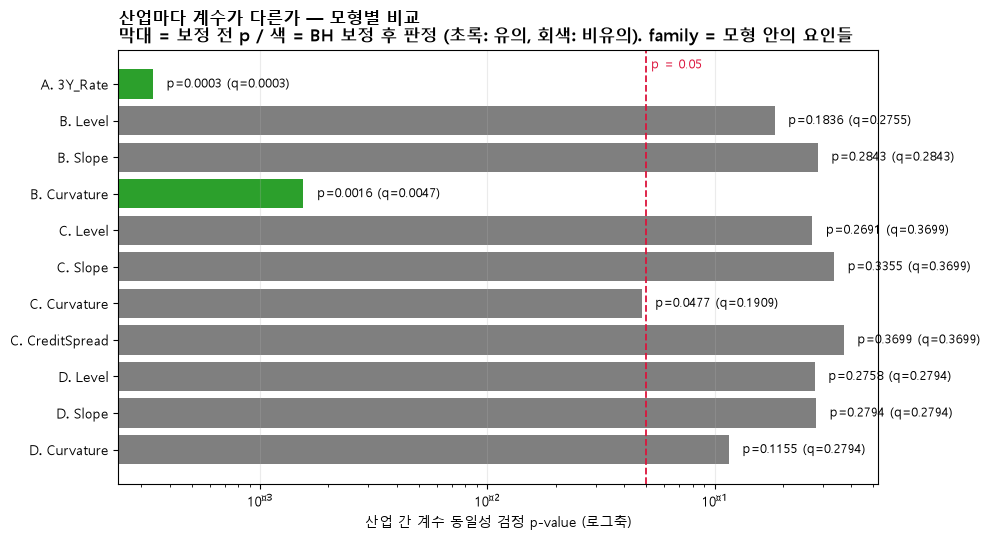

In [45]:
# 모형별 p값 비교. 0.05선을 넘는지가 핵심이라 로그축으로 그린다.
plot_data = industry_difference_test.copy()
plot_data["label"] = plot_data["model"].str[0] + ". " + plot_data["factor"]
plot_data = plot_data.iloc[::-1].reset_index(drop=True)

# 막대 길이는 보정 전 p, 색은 BH 보정 후 판정이다. 둘 다 보여야 보정의 효과가 드러난다.
colors = ["tab:green" if s else "tab:gray" for s in plot_data["significant_5pct_bh"]]

fig, ax = plt.subplots(figsize=(10, 5.5))

y_pos = np.arange(len(plot_data))
ax.barh(y_pos, plot_data["p_value"], color=colors)

for i, (v, q) in enumerate(zip(plot_data["p_value"], plot_data["p_value_bh"])):
    ax.text(v * 1.15, i, f"p={v:.4f} (q={q:.4f})", va="center", fontsize=9)

ax.axvline(0.05, linestyle="--", linewidth=1.3, color="crimson")
ax.text(0.05, len(plot_data) - 0.3, " p = 0.05", color="crimson", fontsize=9, va="top")

ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["label"])
ax.set_xlabel("산업 간 계수 동일성 검정 p-value (로그축)")
ax.set_title(
    "산업마다 계수가 다른가 — 모형별 비교\n"
    "막대 = 보정 전 p / 색 = BH 보정 후 판정 (초록: 유의, 회색: 비유의). family = 모형 안의 요인들",
    loc="left",
    fontweight="bold",
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

diff_fig_path = config.H1_FIGDIR / "09_industry_difference_test.png"
fig.savefig(diff_fig_path, dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 3년물 단일 모형에서는 산업 간 금리 민감도 차이가 유의하다.
- 3요인 모형에서는 Curvature에서만 산업 간 차이가 유의하다.
- 신용스프레드를 더한 4요인에서는 BH 보정 후 Curvature 차이도 유의하지 않다.
- 관측금리 기반 나비 3요인 모형에서도 Curvature의 산업 간 차이는 유의하지 않다(F≈1.706, raw p≈0.1155, BH p≈0.2794). 따라서 NS λ=0.5의 Curvature 이질성은 곡률 구성 방식에 민감한 조건부 결과다.

## D-5. 세 모형 비교와 그림

3요인 · 2요인 · 직교화 결과를 한자리에 놓고,
<b>어떤 모형에서 몇 개 조합이 유의해지는지</b>를 본다.

유의 개수가 늘어난다고 해서 그 모형이 '더 옳은' 것은 아니다.
같은 데이터에서 모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking이므로,
아래 표는 <b>어느 설정에서 신호가 살아나는지 진단하는 용도</b>로만 쓴다.

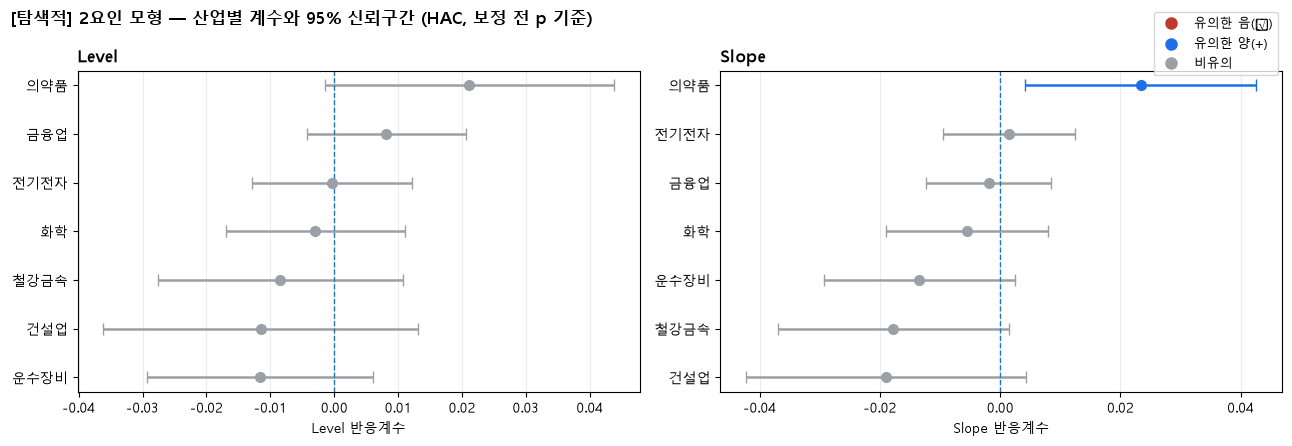

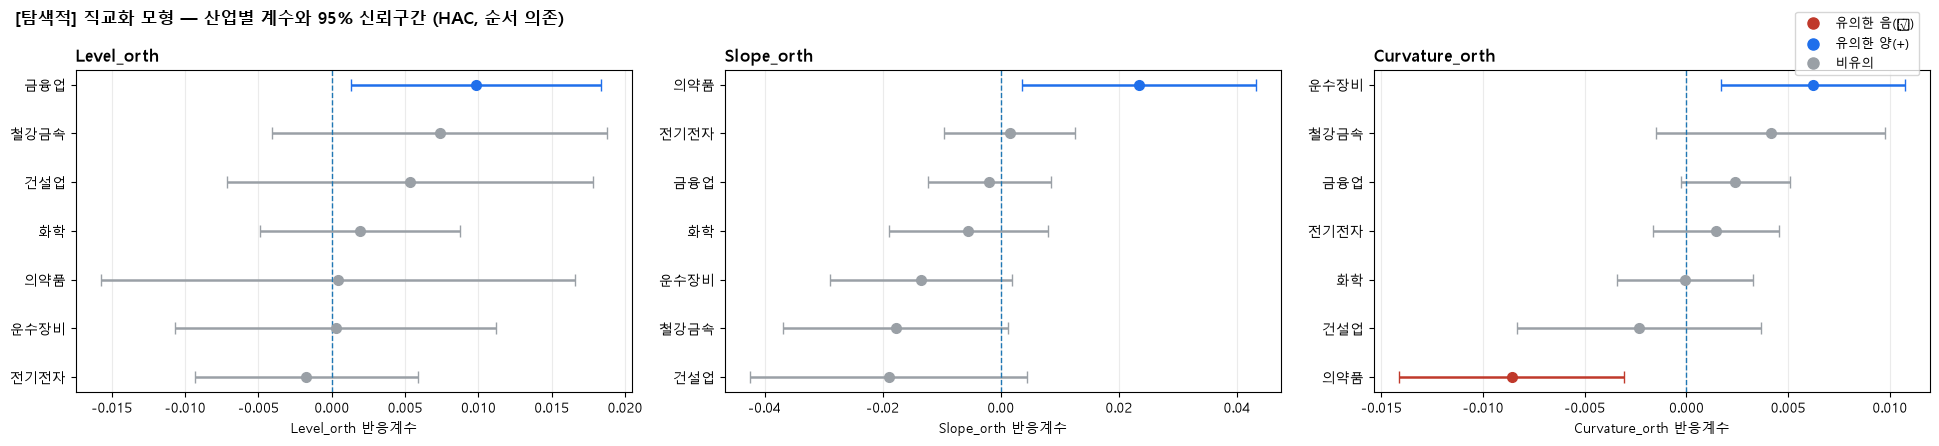

In [46]:
# 2요인·직교화 모형의 계수 신뢰구간 그림 (12단계 errorbar 스타일 유지)
def plot_factor_ci(result, factors, title, out_path, ncols=2):
    """요인별 산업 계수와 95% CI 를 패널로 그린다. 스타일은 12단계와 동일.

    색상은 계수 부호를 나타낸다. 탐색적 분석이라 BH를 적용하지 않고
    보정 전 p_value < 0.05(significant_5pct) 기준으로 판정한다.
    """
    nrows = int(np.ceil(len(factors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows),
                             squeeze=False)
    flat = axes.ravel()

    for ax, factor in zip(flat, factors):
        d = (result[result["factor"] == factor]
             .sort_values("coefficient")
             .reset_index(drop=True))
        y_pos = np.arange(len(d))

        point_colors = [
            config.sign_color(coef, sig)
            for coef, sig in zip(d["coefficient"], d["significant_5pct"])
        ]

        for y, coef, lo, hi, color in zip(
            y_pos,
            d["coefficient"],
            d["coefficient"] - d["ci_lower_95"],
            d["ci_upper_95"] - d["coefficient"],
            point_colors,
        ):
            ax.errorbar(
                coef, y,
                xerr=[[lo], [hi]],
                fmt="o", capsize=4, linewidth=1.8, markersize=7,
                color=color, ecolor=color,
            )
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(d["industry"])
        ax.set_xlabel(f"{factor} 반응계수")
        ax.set_title(factor, loc="left", fontweight="bold")
        ax.grid(axis="x", alpha=0.25)

    for ax in flat[len(factors):]:
        ax.set_visible(False)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["ns"], label="비유의"),
    ]
    fig.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=9,
               bbox_to_anchor=(0.99, 0.99))

    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()


plot_factor_ci(
    two_factor_betas, ["Level", "Slope"],
    "[탐색적] 2요인 모형 — 산업별 계수와 95% 신뢰구간 (HAC, 보정 전 p 기준)",
    config.H1_FIGDIR / "06_two_factor_ci.png",
)

plot_factor_ci(
    orthogonalized_betas, ["Level_orth", "Slope_orth", "Curvature_orth"],
    "[탐색적] 직교화 모형 — 산업별 계수와 95% 신뢰구간 (HAC, 순서 의존)",
    config.H1_FIGDIR / "07_orthogonalized_ci.png",
    ncols=3,
)

In [47]:
# 모형별 유의 조합 수 비교
comparison = pd.DataFrame([
    {"모형": "3요인 (B-1 기준)",
     "설명변수": 3,
     "유의_조합": int(yield_curve_factor_betas["significant_5pct"].sum()),
     "전체_조합": len(yield_curve_factor_betas),
     "최대_VIF": round(max(v for k, v in vif_values.items() if k != "d_credit_spread"), 2)},
    {"모형": "4요인 (B-2 확장)",
     "설명변수": 4,
     "유의_조합": int(credit_spread_extended["significant_5pct"].sum()),
     "전체_조합": len(credit_spread_extended),
     "최대_VIF": round(max(vif_values.values()), 2)},
    {"모형": "2요인 (탐색적)",
     "설명변수": 2,
     "유의_조합": int(two_factor_betas["significant_5pct"].sum()),
     "전체_조합": len(two_factor_betas),
     "최대_VIF": round(max(two_factor_vif.values()), 2)},
    {"모형": "직교화 3요인 (탐색적)",
     "설명변수": 3,
     "유의_조합": int(orthogonalized_betas["significant_5pct"].sum()),
     "전체_조합": len(orthogonalized_betas),
     "최대_VIF": 1.0},
])

print("동시검정(F) 유의 산업:", int(joint_ftest["joint_sig_5pct"].sum()), "/ 7")
print()
display(comparison)
print()
print("주의: 유의 개수가 많은 모형이 더 옳은 모형이 아니다.")
print("      모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking 이다.")

동시검정(F) 유의 산업: 3 / 7



,모형,설명변수,유의_조합,전체_조합,최대_VIF
0,3요인 (B-1 기준),3,3,21,7.25
1,4요인 (B-2 확장),4,3,28,7.25
2,2요인 (탐색적),2,1,14,3.45
3,직교화 3요인 (탐색적),3,4,21,1.00



주의: 유의 개수가 많은 모형이 더 옳은 모형이 아니다.
      모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking 이다.


### 관찰 결과

- 2요인·직교화·확장 모형을 나란히 보면 유의 조합 수가 설정에 따라 달라진다.
- 유의 개수가 많다고 더 옳은 모형은 아니며, 어느 설정에서 신호가 살아나는지 진단하는 용도다.

## D-6. HAC 시차 민감도

### 왜 확인하나

- 지금까지 모든 회귀는 `maxlags=5`를 썼다. Baseline·B-1과 맞추려고 고정한 값이다.

- 그런데 Newey–West 경험식은 다른 값을 제시한다.

$$
\text{maxlags} = 4\left(\frac{T}{100}\right)^{2/9}
$$

T=2,451이면 <b>약 8</b>이다. 지금 쓰는 5보다 크다.

- 시차를 늘리면 표준오차가 커지는 게 보통이라 p값도 올라간다. 즉 지금 결과가 <b>시차를 짧게 잡아서 나온 것은 아닌지</b> 확인해야 한다.

### 무엇을 보나

시차를 5·8·10·20으로 바꿔가며 세 가지를 다시 본다.

1. 3요인 모형 개별 계수 — 유의했던 의약품·운수장비 Curvature가 버티는가
2. 4요인 모형 Credit Spread — 계속 비유의인가
3. 동시검정(D-1) — 같은 두 산업이 버티는가

<b>산업 간 차이 검정(D-4)은 날짜 클러스터 표준오차를 쓰므로 HAC 시차와 무관하다.</b> 여기서 다루지 않는다.

### 판단 기준

계수는 시차와 무관하게 똑같다. HAC는 표준오차만 바꾼다.
따라서 <b>유의성 판정이 뒤집히는 조합이 몇 개인지</b>만 보면 된다.

In [48]:
# Newey-West 경험식으로 권장 시차를 계산해 둔다(보고서에 근거로 쓴다).
N_OBS_PER_INDUSTRY = int(
    extended_panel.dropna(
        subset=["industry_return", "kospi_return", "d_ns_level"]
    ).groupby("industry").size().iloc[0]
)

RULE_OF_THUMB_LAGS = 4 * (N_OBS_PER_INDUSTRY / 100) ** (2 / 9)

HAC_LAG_GRID = [5, 8, 10, 20]

print(f"산업별 관측치 T = {N_OBS_PER_INDUSTRY}")
print(f"Newey-West 경험식 4(T/100)^(2/9) = {RULE_OF_THUMB_LAGS:.2f}  →  약 {round(RULE_OF_THUMB_LAGS)}")
print(f"현재 사용값 = {HAC_LAGS}")
print(f"검토할 시차 = {HAC_LAG_GRID}")

산업별 관측치 T = 2451
Newey-West 경험식 4(T/100)^(2/9) = 8.14  →  약 8
현재 사용값 = 5
검토할 시차 = [5, 8, 10, 20]


In [49]:
def run_hac_sensitivity(data, lag_grid, x_cols, factor_labels, model_name):
    """HAC 시차를 바꿔가며 같은 모형을 다시 추정한다."""
    frames = []

    for lags in lag_grid:
        r = run_yield_curve_factor_model(
            data, hac_lags=lags, x_cols=x_cols, factor_labels=factor_labels,
        )
        r["model"] = model_name
        frames.append(r)

    return pd.concat(frames, ignore_index=True)


# (1) 3요인 모형
sens_three = run_hac_sensitivity(
    extended_panel, HAC_LAG_GRID,
    x_cols=["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature"],
    factor_labels={"d_ns_level": "Level", "d_ns_slope": "Slope",
                   "d_ns_curvature": "Curvature"},
    model_name="B_ThreeFactor",
)

# (2) 4요인 모형 (Credit Spread 포함)
sens_four = run_hac_sensitivity(
    extended_panel, HAC_LAG_GRID,
    x_cols=CREDIT_X_COLS,
    factor_labels=CREDIT_FACTOR_LABELS,
    model_name="C_FourFactor",
)

hac_sensitivity = pd.concat([sens_three, sens_four], ignore_index=True)

# 계수가 시차에 따라 변하지 않는지 확인한다(변하면 구현이 잘못된 것이다).
_coef_spread = (
    hac_sensitivity
    .groupby(["model", "industry", "factor"])["coefficient"]
    .agg(lambda s: s.max() - s.min())
    .max()
)
print(f"[검증] 시차별 계수 최대 변동폭: {_coef_spread:.3e}  (0이어야 정상)")
if _coef_spread > 1e-12:
    raise RuntimeError("HAC 시차가 계수를 바꿨습니다. 구현을 확인하세요.")

sens_path = config.H1_TABDIR / "exploratory_hac_sensitivity.csv"
hac_sensitivity.to_csv(sens_path, index=False, encoding="utf-8-sig")

# 유의성 판정이 시차에 따라 바뀌는 조합을 찾는다.
flip = (
    hac_sensitivity
    .groupby(["model", "industry", "factor"])["significant_5pct"]
    .nunique()
    .reset_index(name="n_distinct")
)
flipped = flip[flip["n_distinct"] > 1]

print()
print(f"검토한 조합: {len(flip)}개  (모형 2개 x 산업 7개 x 요인)")
print(f"시차에 따라 유의성이 뒤집힌 조합: {len(flipped)}개")
if len(flipped):
    display(
        hac_sensitivity.merge(flipped[["model", "industry", "factor"]],
                              on=["model", "industry", "factor"])
        [["model", "industry", "factor", "hac_lags", "coefficient",
          "std_error_hac", "p_value", "significant_5pct"]]
        .round(6)
    )

[검증] 시차별 계수 최대 변동폭: 0.000e+00  (0이어야 정상)

검토한 조합: 49개  (모형 2개 x 산업 7개 x 요인)
시차에 따라 유의성이 뒤집힌 조합: 0개


In [50]:
# 동시검정(D-1)도 시차를 바꿔 다시 본다.
joint_sensitivity = pd.concat(
    [
        run_joint_significance_test(extended_panel, hac_lags=lags)
        .assign(hac_lags=lags)
        for lags in HAC_LAG_GRID
    ],
    ignore_index=True,
)

joint_pivot = joint_sensitivity.pivot(
    index="industry", columns="hac_lags", values="joint_p_value"
).sort_values(HAC_LAG_GRID[0])

print("동시검정 p값 — 시차별")
display(joint_pivot.round(5))

joint_flip = (
    joint_sensitivity.groupby("industry")["joint_sig_5pct"].nunique()
)
print("시차에 따라 판정이 뒤집힌 산업:",
      list(joint_flip[joint_flip > 1].index) or "없음")

동시검정 p값 — 시차별


hac_lags,5,8,10,20
industry,,,,
의약품,0.00268,0.00384,0.00505,0.01012
운수장비,0.01313,0.01248,0.01163,0.00751
금융업,0.03057,0.03733,0.04208,0.05150
철강금속,0.10744,0.10309,0.10841,0.12462
건설업,0.28955,0.30858,0.32004,0.32183
전기전자,0.76133,0.75921,0.76799,0.78449
화학,0.79026,0.78210,0.77697,0.77645


시차에 따라 판정이 뒤집힌 산업: ['금융업']


### 그림 읽는 법

왼쪽은 3요인 모형에서 산업별 <b>가장 작은 개별 p값</b>, 오른쪽은 <b>동시검정 p값</b>이다.
가로축은 HAC 시차, 세로축은 p값(로그축)이다.
회색 점선이 경험식 권장값, 붉은 선이 p=0.05다.

선이 붉은 선을 넘나들면 시차 선택에 따라 판정이 바뀐다는 뜻이다.

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


...

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


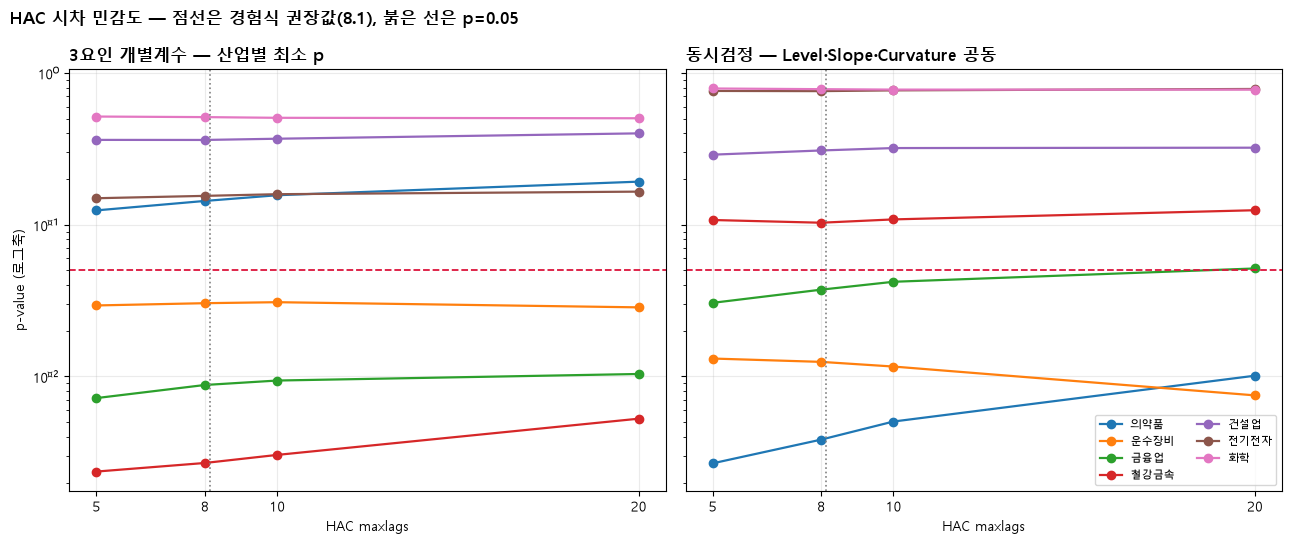

In [51]:
min_individual = (
    hac_sensitivity[hac_sensitivity["model"] == "B_ThreeFactor"]
    .groupby(["industry", "hac_lags"])["p_value"].min()
    .unstack("hac_lags")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for ax, table, title in [
    (axes[0], min_individual, "3요인 개별계수 — 산업별 최소 p"),
    (axes[1], joint_pivot, "동시검정 — Level·Slope·Curvature 공동"),
]:
    for industry in table.index:
        ax.plot(table.columns, table.loc[industry], marker="o",
                linewidth=1.6, label=industry)

    ax.axhline(0.05, linestyle="--", linewidth=1.3, color="crimson")
    ax.set_xticks(HAC_LAG_GRID)
    ax.set_xlabel("HAC maxlags")
    ax.set_yscale("log")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("p-value (로그축)")
axes[0].axvline(RULE_OF_THUMB_LAGS, linestyle=":", linewidth=1.2, color="gray")
axes[1].axvline(RULE_OF_THUMB_LAGS, linestyle=":", linewidth=1.2, color="gray")
axes[1].legend(fontsize=8, ncol=2)

fig.suptitle(
    f"HAC 시차 민감도 — 점선은 경험식 권장값({RULE_OF_THUMB_LAGS:.1f}), "
    "붉은 선은 p=0.05",
    x=0.01, ha="left", fontweight="bold",
)
fig.tight_layout()

sens_fig_path = config.H1_FIGDIR / "10_hac_sensitivity.png"
fig.savefig(sens_fig_path, dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- HAC 시차를 5·8·10·20으로 바꿔도 49개 계수 조합에서 유의성 판정이 뒤집힌 사례가 없다.
- 동시검정에서만 금융업 1건이 0.03→0.05 경계로 갈렸다.
- 전체 결론은 HAC 시차 선택에 강건하다.

# PART E. 후속 검토

본분석에서 남은 두 질문을 확인한다.

1. <b>곡률과 신용스프레드의 중첩은 어떤 성격인가</b> — Credit Spread를 넣으면 곡률 계수가 줄어든다.
   이것이 실제 효과 감소인가, 아니면 겹친 부분을 어느 쪽에 배정하느냐의 문제인가.
2. <b>의약품·운수장비의 부호 차이를 경제적으로 설명할 수 있는가</b> — 방어주와 경기민감주의
   차이로 볼 수 있는지 확인한다.

## E-1. 곡률–신용스프레드 중첩의 성격

### 왜 확인하나

-4요인 모형에서 곡률 계수가 <b>13~36%</b> 줄고 <b>BH p가 0.0901</b>로 밀렸다. 두 가지 해석이 가능하다.

1. <b>(a) 실제 효과 감소</b> — 곡률로 보이던 것의 일부가 사실 신용위험 효과였다.
2. <b>(b) 배정 문제</b> — 두 변수가 겹치는 부분을 신용스프레드가 가져갔을 뿐이다.

### 직교화로는 (a)와 (b)를 구분할 수 없다 (교수 §8)

- 신용스프레드를 회귀식의 <b>모든 설명변수</b>(시장수익률·곡선 3요인)에 직교화한 뒤 다시 넣으면, FWL 정리에 의해 곡률 계수는 3요인 모형과 정확히 같아진다. 그런데 이 '같아짐'은 직교화의 <b>필연적 결과</b>이지 (b)의 증거가 아니다. 즉 이 비교는 실제 효과 감소와 공유분 재배정을 구분해 주지 못한다.

- 아래는 그 성질을 직접 보이기 위한 것이다 — 곡률 계수가 보존되는지는 확인하되, 보존 자체를 (b)의 근거로 쓰지 않는다.

In [52]:
# 신용스프레드 중 곡선요인으로 설명되는 부분이 얼마나 되는가
factor_daily_e = (
    extended_panel[["date", "kospi_return", "d_ns_level", "d_ns_slope",
                    "d_ns_curvature", "d_credit_spread"]]
    .drop_duplicates(subset="date").dropna().reset_index(drop=True)
)
# 최종 회귀의 모든 설명변수(시장수익률+곡선 3요인)에 직교화해야 FWL로 곡률 계수가 정확히 보존된다 (교수 §8).
# 시장수익률을 빼면 곡률 계수가 2.9e-6 만큼 어긋난다(완전 보존 아님).
_X = sm.add_constant(
    factor_daily_e[["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature"]],
    has_constant="add")
_m = sm.OLS(factor_daily_e["d_credit_spread"], _X).fit()

print(f"신용스프레드를 시장수익률·곡선 3요인에 회귀 → R² = {_m.rsquared:.4f}")
print(f"  겹치는 부분 {_m.rsquared*100:.1f}%, 고유 부분 {(1-_m.rsquared)*100:.1f}%")
print(f"  곡률 계수 {_m.params['d_ns_curvature']:+.4f} (t = {_m.tvalues['d_ns_curvature']:.2f})")

# 곡선요인과 겹치지 않는 신용스프레드(직교화)
factor_daily_e["d_credit_orth"] = _m.resid
exploratory_panel_e = extended_panel.merge(
    factor_daily_e[["date", "d_credit_orth"]], on="date", how="left")

신용스프레드를 시장수익률·곡선 3요인에 회귀 → R² = 0.1859
  겹치는 부분 18.6%, 고유 부분 81.4%
  곡률 계수 -0.0299 (t = -18.33)


In [53]:
CREDIT_ORTH_X = ["kospi_return", "d_ns_level", "d_ns_slope",
                 "d_ns_curvature", "d_credit_orth"]
CREDIT_ORTH_LABELS = {"d_ns_level": "Level", "d_ns_slope": "Slope",
                      "d_ns_curvature": "Curvature", "d_credit_orth": "CreditSpread_orth"}

credit_orth_betas = (
    run_yield_curve_factor_model(exploratory_panel_e, hac_lags=HAC_LAGS,
                                 x_cols=CREDIT_ORTH_X,
                                 factor_labels=CREDIT_ORTH_LABELS)
    .assign(model="E_CreditOrthogonalized")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

# 세 모형의 Curvature 계수를 나란히 비교
overlap_check = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient", "std_error_hac"]]
    .rename(columns={"coefficient": "coef_3factor", "std_error_hac": "se_3factor"})
    .merge(credit_spread_betas[
               (credit_spread_betas["model"] == "B_Extended_4Factor") &
               (credit_spread_betas["factor"] == "Curvature")]
           [["industry", "coefficient", "p_value_bh"]]
           .rename(columns={"coefficient": "coef_4factor", "p_value_bh": "bh_4factor"}),
           on="industry")
    .merge(credit_orth_betas[credit_orth_betas["factor"] == "Curvature"]
           [["industry", "coefficient", "p_value_bh"]]
           .rename(columns={"coefficient": "coef_orth", "p_value_bh": "bh_orth"}),
           on="industry")
)
overlap_check["차이_3요인vs직교화"] = (
    overlap_check["coef_3factor"] - overlap_check["coef_orth"]).abs()

overlap_path = config.H1_TABDIR / "credit_curvature_overlap.csv"
overlap_check.to_csv(overlap_path, index=False, encoding="utf-8-sig")

display(overlap_check.round(6))
print()
print(f"3요인 vs 직교화 4요인 계수 최대 차이: "
      f"{overlap_check['차이_3요인vs직교화'].max():.2e}")
print("→ 계수 보존은 FWL의 필연적 결과이며, 이것만으로 (a)/(b)를 구분할 수 없다 (교수 §8).")
print()

,industry,coef_3factor,se_3factor,coef_4factor,bh_4factor,coef_orth,bh_orth,차이_3요인vs직교화
0,건설업,-0.002338,0.003058,-0.002313,0.572208,-0.002338,0.518796,0.0
1,금융업,0.002413,0.001370,0.001543,0.524882,0.002413,0.179817,0.0
2,운수장비,0.006207,0.002310,0.005363,0.090107,0.006207,0.023955,0.0
3,의약품,-0.008599,0.002828,-0.006435,0.090107,-0.008599,0.016127,0.0
4,전기전자,0.001441,0.001582,0.001537,0.524882,0.001441,0.505819,0.0
5,철강금속,0.004148,0.002878,0.002900,0.524882,0.004148,0.250354,0.0
6,화학,-0.000080,0.001704,0.000758,0.688090,-0.000080,0.963016,0.0



3요인 vs 직교화 4요인 계수 최대 차이: 4.19e-17
→ 계수 보존은 FWL의 필연적 결과이며, 이것만으로 (a)/(b)를 구분할 수 없다 (교수 §8).



### 관찰 결과

- 신용스프레드의 약 <b>18.6%</b>가 곡선요인과 겹치고 81.4%는 고유 성분이다.
- 모든 설명변수에 직교화하면 곡률 계수는 3요인 모형과 정확히 일치한다(최대 차이 ~1e-16). 이는 FWL 정리의 필연적 결과다.

### 해석 (교수 §8)

- 따라서 '직교화해도 곡률이 유지되므로 배정 문제(b)'라고 결론지을 수 없다. 계수 보존은 직교화가 만든 것이지 식별이 아니다.
- 두 변수가 공유하는 18.6%의 귀속은 <b>본 자료로 식별되지 않으며</b>, 직교화는 배정 규칙을 바꿀 뿐 식별을 만들어 내지 못한다.
- 만기가 다른 회사채로 신용요인을 추가 식별하는 것은 후속 과제로 남긴다.

## E-2. 부호 차이의 경제적 해석 시도

### 무엇을 확인하나

1. 의약품(−)과 운수장비(+)의 부호가 반대다.
<b>방어주와 경기민감주의 차이</b>로 볼 수 있다면, 곡률 노출이 경기민감도와 관련되어야 한다.

2. 경기민감도의 대용치로 <b>시장베타(KOSPI 계수)</b> 를 쓴다.
산업이 7개뿐이므로 순위상관으로만 본다. 계획서의 H3 방식과 같다.

### 판단 기준

- 상관이 뚜렷하게 양(+)이면 → "경기민감할수록 곡률 노출이 양(+)" 해석과 정합적
- 상관이 없으면 → <b>이 해석을 쓰면 안 된다</b>

In [54]:
from scipy.stats import spearmanr

beta_profile = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "market_beta", "coefficient", "p_value"]]
    .rename(columns={"coefficient": "curvature_beta", "p_value": "curvature_p"})
    .sort_values("market_beta").reset_index(drop=True)
)

rho, pval = spearmanr(beta_profile["market_beta"], beta_profile["curvature_beta"])
beta_profile["spearman_rho"] = round(rho, 4)
beta_profile["spearman_p"] = round(pval, 4)

profile_path = config.H1_TABDIR / "curvature_market_beta_profile.csv"
beta_profile.to_csv(profile_path, index=False, encoding="utf-8-sig")

display(beta_profile.round(5))
print(f"\n시장베타 vs 곡률계수  Spearman rho = {rho:+.3f}  (p = {pval:.4f}, n=7)")
print()
if pval < 0.10:
    print("→ 경기민감도와 곡률 노출 사이에 관련이 있다.")
else:
    print("→ 관련이 확인되지 않는다.")
    print("   '방어주 대 경기민감주' 해석은 이 자료로 뒷받침되지 않는다.")
    print("   부호 차이는 관찰 사실로만 보고하고 해석을 붙이지 않는다.")

,industry,market_beta,curvature_beta,curvature_p,spearman_rho,spearman_p
0,의약품,0.78917,-0.00860,0.00236,0.1429,0.7599
1,금융업,0.92575,0.00241,0.07807,0.1429,0.7599
2,운수장비,1.00631,0.00621,0.00721,0.1429,0.7599
3,건설업,1.01328,-0.00234,0.44457,0.1429,0.7599
4,철강금속,1.02485,0.00415,0.14948,0.1429,0.7599
5,화학,1.05406,-0.00008,0.96244,0.1429,0.7599
6,전기전자,1.20647,0.00144,0.36228,0.1429,0.7599



시장베타 vs 곡률계수  Spearman rho = +0.143  (p = 0.7599, n=7)

→ 관련이 확인되지 않는다.
   '방어주 대 경기민감주' 해석은 이 자료로 뒷받침되지 않는다.
   부호 차이는 관찰 사실로만 보고하고 해석을 붙이지 않는다.


---

# 부록 A. 어느 표에 어떤 표준오차를 왜 썼는가

표준오차는 가설(H1/H2)이 아니라 <b>회귀 형태</b>를 기준으로 정한다. 가설 단위로 정하면 같은 형태의 회귀에 서로 다른 SE가 붙어 기준이 흐려지기 때문이다.

- <b>통합회귀</b> — 산업더미 교차항으로 7개 산업이 한 회귀식에 함께 들어간다. 같은 날짜의 산업들이 공통 충격을 받아 잔차가 횡단면으로 상관되므로 <b>날짜 클러스터</b> SE를 쓴다. 시계열 HAC는 이 상관을 보정하지 못한다.
- <b>개별 시계열 회귀</b> — 산업이 하나뿐이라 횡단면 상관이 생길 여지가 없다. 날짜당 관측치가 1개여서 날짜로 클러스터를 잡으면 클러스터 크기가 1이 되고, 보정 효과는 없이 HAC의 자기상관 보정만 잃는다. 따라서 <b>HAC(Newey–West, lag 5)</b>를 유지한다.

점추정(계수)은 SE 방식과 무관하다. 달라지는 것은 SE·t·p·신뢰구간뿐이다.

아래는 이 노트북이 만든 결과표별 적용 내역이다. 전체 내역은 `results/H1_yield_curve/tables/appendix_06_se_by_table.csv`에 저장했다(과거 버전이 쓰던 `config.se_appendix_table()` 헬퍼는 경로 전용 리팩터링 과정에서 제거되어, 현재는 이 노트북 안에서 직접 만든다).

In [55]:
print("table columns:")
print(table.columns.tolist())
display(table)

print("\nhac_sensitivity columns:")
print(hac_sensitivity.columns.tolist())
display(hac_sensitivity.head())

table columns:
[5, 8, 10, 20]


hac_lags,5,8,10,20
industry,,,,
의약품,0.002678,0.003837,0.005049,0.010120
운수장비,0.013131,0.012483,0.011629,0.007509
금융업,0.030574,0.037332,0.042081,0.051498
철강금속,0.107440,0.103090,0.108414,0.124622
건설업,0.289550,0.308577,0.320042,0.321833
전기전자,0.761330,0.759212,0.767989,0.784487
화학,0.790255,0.782104,0.776974,0.776447



hac_sensitivity columns:
['industry', 'factor', 'variable', 'coefficient', 'std_error_hac', 't_value', 'p_value', 'ci_lower_95', 'ci_upper_95', 'significant_5pct', 'market_beta', 'r_squared', 'adj_r_squared', 'n_obs', 'hac_lags', 'optimal_lambda', 'model']


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda,model
0,건설업,Level,d_ns_level,-0.021038,0.019810,-1.061952,0.288258,-0.059866,0.017790,False,1.013279,0.399432,0.398449,2451,5,0.5,B_ThreeFactor
1,건설업,Slope,d_ns_slope,-0.027805,0.018091,-1.536940,0.124308,-0.063263,0.007653,False,1.013279,0.399432,0.398449,2451,5,0.5,B_ThreeFactor
2,건설업,Curvature,d_ns_curvature,-0.002338,0.003058,-0.764503,0.444568,-0.008330,0.003655,False,1.013279,0.399432,0.398449,2451,5,0.5,B_ThreeFactor
3,금융업,Level,d_ns_level,0.017979,0.008254,2.178290,0.029384,0.001802,0.034156,True,0.925754,0.623471,0.622855,2451,5,0.5,B_ThreeFactor
4,금융업,Slope,d_ns_slope,0.007189,0.007423,0.968519,0.332785,-0.007359,0.021737,False,0.925754,0.623471,0.622855,2451,5,0.5,B_ThreeFactor


In [56]:
# 부록 A - HAC 표준오차 민감도 내역
appendix_se = (
    hac_sensitivity[
        [
            "industry",
            "model",
            "factor",
            "variable",
            "hac_lags",
            "coefficient",
            "std_error_hac",
            "t_value",
            "p_value",
            "significant_5pct",
        ]
    ]
    .copy()
    .sort_values(["model", "industry", "factor", "hac_lags"])
    .reset_index(drop=True)
)

appendix_se_path = config.H1_TABDIR / "appendix_06_se_by_table.csv"

appendix_se.to_csv(
    appendix_se_path,
    index=False,
    encoding="utf-8-sig"
)

display(appendix_se.head(20))
print("저장:", config._rel(appendix_se_path))

,industry,model,factor,variable,hac_lags,coefficient,std_error_hac,t_value,p_value,significant_5pct
0,건설업,B_ThreeFactor,Curvature,d_ns_curvature,5,-0.002338,0.003058,-0.764503,0.444568,False
1,건설업,B_ThreeFactor,Curvature,d_ns_curvature,8,-0.002338,0.003206,-0.729005,0.465999,False
2,건설업,B_ThreeFactor,Curvature,d_ns_curvature,10,-0.002338,0.003316,-0.704993,0.480815,False
3,건설업,B_ThreeFactor,Curvature,d_ns_curvature,20,-0.002338,0.003752,-0.623021,0.533271,False
4,건설업,B_ThreeFactor,Level,d_ns_level,5,-0.021038,0.019810,-1.061952,0.288258,False
5,건설업,B_ThreeFactor,Level,d_ns_level,8,-0.021038,0.021131,-0.995570,0.319459,False
6,건설업,B_ThreeFactor,Level,d_ns_level,10,-0.021038,0.021926,-0.959473,0.337320,False
7,건설업,B_ThreeFactor,Level,d_ns_level,20,-0.021038,0.024366,-0.863401,0.387917,False
8,건설업,B_ThreeFactor,Slope,d_ns_slope,5,-0.027805,0.018091,-1.536940,0.124308,False
9,건설업,B_ThreeFactor,Slope,d_ns_slope,8,-0.027805,0.019006,-1.462992,0.143470,False


저장: results\H1_yield_curve\tables\appendix_06_se_by_table.csv


---

# 부록 B. BH(FDR) 보정을 어떤 단위로 묶었는가

BH는 하나의 검정족(family) 안에서 위양성 비율(FDR)을 통제하는 절차이고, 검정족은 <b>연구질문 단위</b>로 정의한다.

- Baseline(산업 간 차이)·H1(곡선요인)·H2(비대칭)은 서로 다른 연구질문이므로 각각 별도 family로 둔다.
- 전체를 하나로 일괄 보정하면, H1에서 검정을 몇 개 했는지가 Baseline 표의 임계값을 바꾸게 된다. 그러면 Baseline 결과가 왜 이렇게 나왔는지를 Baseline 가설 안에서 설명할 수 없다.
- 다만 이 선택이 결과를 유리하게 만든 것이 아님을 보이기 위해, <b>전체를 일괄 보정했을 때의 q값을 같은 표에 병기</b>한다.

표 읽는 법

- `보정 전 p` — 각 검정의 원 p값.
- `가설 단위 q` — 본문 판정에 쓰는 BH 보정값. 위 family 안에서만 보정한다.
- `전체 일괄 q` — 04·05·06·07의 확증 검정 전체를 하나의 족으로 묶었을 때의 값. 비교용이며 본문 판정에는 쓰지 않는다.
- 강건성·민감도 등 탐색적 검정(`exploratory_*`)은 확증 검정이 아니므로 일괄 보정 대상에서 뺀다.

전체 일괄 q는 다른 노트북의 결과표까지 읽어 계산한다. 04·05·06·07을 모두 한 번씩 실행한 뒤에 이 셀을 돌려야 값이 채워진다.

In [57]:
# 부록 B — BH 보정 단위 요약 (family / 검정 수 / 보정 전 p / 가설 단위 q / 전체 일괄 q)
# config.bh_appendix_table는 config.py를 경로 전용으로 리팩터링하며 사라진 함수다.
# 대신 이 노트북에서 이미 add_bh_correction()으로 계산해 둔 7개 결과표를 그대로 모아
# 같은 부록을 재구성한다. 가설 단위 q(q_family)는 각 표의 기존 p_value_bh를 그대로
# 재사용하고(재추정 없음), 전체 일괄 q만 이 노트북의 검정 전체를 하나의 족으로 묶어
# 새로 계산한다.
_bh_source_tables = [
    ("yield_curve_factor_betas", yield_curve_factor_betas, "p_value", "p_value_bh", "significant_5pct_bh"),
    ("credit_spread_betas", credit_spread_betas, "p_value", "p_value_bh", "significant_5pct_bh"),
    ("joint_ftest", joint_ftest, "joint_p_value", "joint_p_value_bh", "significant_5pct_bh"),
    ("two_factor_betas", two_factor_betas, "p_value", "p_value_bh", "significant_5pct_bh"),
    ("orthogonalized_betas", orthogonalized_betas, "p_value", "p_value_bh", "significant_5pct_bh"),
    ("industry_difference_test", industry_difference_test, "p_value", "p_value_bh", "significant_5pct_bh"),
    ("credit_orth_betas", credit_orth_betas, "p_value", "p_value_bh", "significant_5pct_bh"),
]
_bh_id_cols = ["industry", "factor", "variable", "model"]

_bh_rows = []
for _src_name, _src_df, _p_col, _p_bh_col, _sig_bh_col in _bh_source_tables:
    for _, _row in _src_df.iterrows():
        _bh_rows.append({
            "source_table": _src_name,
            "bh_family": _row["bh_family"],
            "bh_n_tests": int(_row["bh_n_tests"]),
            "test_id": " | ".join(f"{c}={_row[c]}" for c in _bh_id_cols if c in _row.index),
            "p_raw": float(_row[_p_col]),
            "q_family": float(_row[_p_bh_col]),
            "significant_family_5pct": bool(_row[_sig_bh_col]),
        })

appendix_bh_long = pd.DataFrame(_bh_rows)
appendix_bh_long["q_global"] = multipletests(
    appendix_bh_long["p_raw"].to_numpy(dtype=float), method="fdr_bh"
)[1]
appendix_bh_long["significant_global_5pct"] = appendix_bh_long["q_global"] < config.BH_ALPHA

def _bh_verdict(fam_sig, glob_sig):
    if fam_sig == glob_sig:
        return "동일"
    return "유의→비유의" if fam_sig else "비유의→유의"

appendix_bh_long["판정 변화"] = [
    _bh_verdict(f, g)
    for f, g in zip(appendix_bh_long["significant_family_5pct"], appendix_bh_long["significant_global_5pct"])
]

appendix_bh_detail = appendix_bh_long[[
    "source_table", "bh_family", "bh_n_tests", "test_id", "p_raw", "q_family", "q_global",
    "significant_family_5pct", "significant_global_5pct", "판정 변화",
]].reset_index(drop=True)

appendix_bh = (
    appendix_bh_long.groupby("bh_family", sort=False)
    .agg(
        검정_수=("bh_n_tests", "first"),
        보정_전_p=("p_raw", lambda s: ", ".join(f"{v:.6f}" for v in s)),
        가설_단위_q=("q_family", lambda s: ", ".join(f"{v:.6f}" for v in s)),
        전체_일괄_q=("q_global", lambda s: ", ".join(f"{v:.6f}" for v in s)),
        가설_단위_유의수=("significant_family_5pct", "sum"),
        전체_일괄_유의수=("significant_global_5pct", "sum"),
        판정_변화수=("판정 변화", lambda s: (s != "동일").sum()),
    )
    .reset_index()
)

appendix_bh_path = config.H1_TABDIR / "appendix_06_bh_families.csv"
appendix_bh.to_csv(appendix_bh_path, index=False, encoding="utf-8-sig")

display(appendix_bh)
print("저장:", config._rel(appendix_bh_path))

# 검정 단위 상세 — 개별 검정마다 보정 전후 p값을 확인한다.
appendix_bh_detail_path = config.H1_TABDIR / "appendix_06_bh_tests.csv"
appendix_bh_detail.to_csv(appendix_bh_detail_path, index=False, encoding="utf-8-sig")

_flip = appendix_bh_detail["판정 변화"].value_counts().to_dict()
print("저장:", config._rel(appendix_bh_detail_path))
print("가설 단위 vs 전체 일괄 — 5% 판정 비교:", _flip)

display(appendix_bh_detail.round(6))

,bh_family,검정_수,보정_전_p,가설_단위_q,전체_일괄_q,가설_단위_유의수,전체_일괄_유의수,판정_변화수
0,B_ThreeFactor | Level,7,"0.288258, 0.029384, 0.293168, 0.383484, 0.5648...","0.671097, 0.205691, 0.671097, 0.671097, 0.6741...","0.629789, 0.209431, 0.629789, 0.635188, 0.7350...",0,0,0
1,B_ThreeFactor | Slope,7,"0.124308, 0.332785, 0.412641, 0.533597, 0.4098...","0.622530, 0.622530, 0.622530, 0.622530, 0.6225...","0.425089, 0.635188, 0.635188, 0.723790, 0.6351...",0,0,0
2,B_ThreeFactor | Curvature,7,"0.444568, 0.078067, 0.007206, 0.002363, 0.3622...","0.518662, 0.182156, 0.025220, 0.016541, 0.5071...","0.641279, 0.368799, 0.106462, 0.061156, 0.6351...",2,0,2
3,A_Credit_Single | CreditSpread,7,"0.842721, 0.092379, 0.056938, 0.007771, 0.9402...","0.940242, 0.161663, 0.132856, 0.054397, 0.9402...","0.931070, 0.408255, 0.339153, 0.106462, 0.9772...",0,0,0
4,B_Extended_4Factor | CreditSpread,7,"0.982326, 0.233915, 0.389419, 0.106798, 0.8797...","0.982326, 0.409352, 0.545186, 0.409352, 0.9823...","0.982326, 0.593451, 0.635188, 0.416298, 0.9415...",0,0,0
5,B_Extended_4Factor | Curvature,7,"0.490464, 0.329895, 0.025745, 0.018890, 0.3749...","0.572208, 0.524882, 0.090107, 0.090107, 0.5248...","0.699933, 0.635188, 0.207473, 0.199068, 0.6351...",0,0,0
6,B_Extended_4Factor | Level,7,"0.294208, 0.043784, 0.336806, 0.502162, 0.5570...","0.774457, 0.306485, 0.774457, 0.774457, 0.7744...","0.629789, 0.285636, 0.635188, 0.709239, 0.7350...",0,0,0
7,B_Extended_4Factor | Slope,7,"0.127216, 0.383147, 0.440638, 0.606045, 0.4060...","0.707053, 0.707053, 0.707053, 0.707053, 0.7070...","0.425089, 0.635188, 0.641279, 0.761726, 0.6351...",0,0,0
8,Exploratory_Joint_3Factor,7,"0.002678, 0.013131, 0.030574, 0.107440, 0.2895...","0.018749, 0.045960, 0.071339, 0.188020, 0.4053...","0.061156, 0.163545, 0.209431, 0.416298, 0.6297...",2,0,2
9,Exploratory_TwoFactor | Level,7,"0.358790, 0.199783, 0.195519, 0.067209, 0.9532...","0.545817, 0.466160, 0.466160, 0.466160, 0.9532...","0.635188, 0.543689, 0.543689, 0.364516, 0.9772...",0,0,0


저장: results\H1_yield_curve\tables\appendix_06_bh_families.csv
저장: results\H1_yield_curve\tables\appendix_06_bh_tests.csv
가설 단위 vs 전체 일괄 — 5% 판정 비교: {'동일': 128, '유의→비유의': 9}


,source_table,bh_family,bh_n_tests,test_id,p_raw,q_family,q_global,significant_family_5pct,significant_global_5pct,판정 변화
0,yield_curve_factor_betas,B_ThreeFactor | Level,7,industry=건설업 | factor=Level | variable=d_ns_le...,0.288258,0.671097,0.629789,False,False,동일
1,yield_curve_factor_betas,B_ThreeFactor | Slope,7,industry=건설업 | factor=Slope | variable=d_ns_sl...,0.124308,0.622530,0.425089,False,False,동일
2,yield_curve_factor_betas,B_ThreeFactor | Curvature,7,industry=건설업 | factor=Curvature | variable=d_n...,0.444568,0.518662,0.641279,False,False,동일
3,yield_curve_factor_betas,B_ThreeFactor | Level,7,industry=금융업 | factor=Level | variable=d_ns_le...,0.029384,0.205691,0.209431,False,False,동일
4,yield_curve_factor_betas,B_ThreeFactor | Slope,7,industry=금융업 | factor=Slope | variable=d_ns_sl...,0.332785,0.622530,0.635188,False,False,동일
...,...,...,...,...,...,...,...,...,...,...
132,credit_orth_betas,E_CreditOrthogonalized | CreditSpread_orth,7,industry=철강금속 | factor=CreditSpread_orth | var...,0.193640,0.409352,0.543689,False,False,동일
133,credit_orth_betas,E_CreditOrthogonalized | Level,7,industry=화학 | factor=Level | variable=d_ns_lev...,0.740183,0.740183,0.866710,False,False,동일
134,credit_orth_betas,E_CreditOrthogonalized | Slope,7,industry=화학 | factor=Slope | variable=d_ns_slo...,0.518090,0.622250,0.716952,False,False,동일
135,credit_orth_betas,E_CreditOrthogonalized | Curvature,7,industry=화학 | factor=Curvature | variable=d_ns...,0.963016,0.963016,0.977283,False,False,동일


---

# 부록 C. 만기 확대 검토

국고채 20년·30년을 추가해 만기를 6개로 늘렸을 때의 결과다.
<b>본분석에는 반영하지 않는다.</b> 확인 결과 요인 분리가 개선되지 않았기 때문이다.

| 만기 세트 | 곡선 RMSE | 최대 VIF |
|---|---|---|
| 1·3·5·10년 (본분석) | 0.01084 | 9.46 |
| + 20·30년 | 0.03837 (3.5배) | <b>18.36</b> |

만기를 늘리자 Nelson–Siegel 3요인이 넓어진 만기 범위를 따라가지 못해
곡선 적합도가 나빠지고, 요인 중첩은 오히려 심해졌다.

또한 <b>국고채 2년물은 2021-03-10부터만 존재</b>해 전체 표본 분석에 쓸 수 없다.
2년물을 포함하면 표본이 2,451일에서 1,186일로 줄어든다.

> 상세 결과는 `notebooks/06-1_treasury_yield_curve.ipynb` 와
> `docs/private/maturity_extension/` 에 있다.
> 만기 개수는 요인 중첩의 원인이 아니다.